# Template 07: SHAP Analysis

**Purpose:** Generate residual + SHAP range plots for top features

**Inputs:**
- results/06_shap_train.parquet
- results/06_shap_test.parquet
- results/05c_predictions_train.parquet
- results/05c_predictions_test.parquet
- data/04c_train_encoded.parquet
- data/04c_test_encoded.parquet

**Outputs:**
- plots/{dataset}_{feature}_residual.png
- plots/{dataset}_{feature}_shap_range.png
- results/07_analysis_summary.yaml

In [1]:
config_path = "config/car_coll/v1"

In [2]:
# Parameters
config_path = "config/car_liab/v1"


In [3]:
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import yaml
import os
import sys
from pathlib import Path
from datetime import datetime

sys.path.insert(0, str(Path.cwd() / 'lib'))
from utils import setup_notebook_environment
from shap_utils import compute_shap_aggregate, create_residual_plot, create_shap_range_plot, create_fast_shap_summary, create_shap_beeswarm, create_shap_importance_pct
from IPython.display import Image, display

print("########################################")
print("# STAGE 07: SHAP ANALYSIS")
print("########################################")

project_root = setup_notebook_environment()

# Note: SHAP interpretation depends on target_method
# - residual: SHAP values show impact on ratio (PP/GLM correction factor)
# - direct: SHAP values show impact on PP directly

########################################
# STAGE 07: SHAP ANALYSIS
########################################


In [4]:
# Get machine config
pc_num = open("current.pc").read().strip()
pc_id = f"PC{pc_num}"

with open(f"{config_path}/config.yaml") as f:
    cfg = yaml.safe_load(f)
output_base = cfg["machines"][pc_id]["paths"]["output_path"]
shap_cfg = cfg.get("shap_analysis", {})
top_n = shap_cfg.get("top_n_features", 40)
datasets = shap_cfg.get("datasets", ["train", "test"])
resid_cfg = shap_cfg.get("residual_plot", {})
shap_range_cfg = shap_cfg.get("shap_range_plot", {})
print(f"\nConfig: top_n={top_n}")


Config: top_n=40


In [5]:
plots_dir = f"{output_base}/plots"
os.makedirs(plots_dir, exist_ok=True)
print(f"Plots: {plots_dir}")

Plots: output/car_liab/v1/plots


In [6]:
# Load ENCODED data (same data used for SHAP computation)
df_train = pd.read_parquet(f"{output_base}/data/04c_train_encoded.parquet")
df_test = pd.read_parquet(f"{output_base}/data/04c_test_encoded.parquet")

print(f"\n* Train encoded: {df_train.shape}")
print(f"* Test encoded: {df_test.shape}")


* Train encoded: (4550028, 151)
* Test encoded: (4539000, 151)


In [7]:
print("\nLoading...")
shap_train = pd.read_parquet(f"{output_base}/results/06_shap_train.parquet")
shap_test = pd.read_parquet(f"{output_base}/results/06_shap_test.parquet")
preds_train = pd.read_parquet(f"{output_base}/results/05c_predictions_train.parquet")
preds_test = pd.read_parquet(f"{output_base}/results/05c_predictions_test.parquet")

print(f"  SHAP train: {shap_train.shape}")
print(f"  SHAP test: {shap_test.shape}")
print(f"  Preds train: {preds_train.shape}")
print(f"  Preds test: {preds_test.shape}")


Loading...


  SHAP train: (10000, 152)
  SHAP test: (4539000, 152)
  Preds train: (4307292, 3)
  Preds test: (4295155, 3)


In [8]:
# Merge train data with predictions
# Use intersection of indices (SHAP is computed on sample)
common_idx = shap_train.index.intersection(preds_train.index)
data_tr = df_train.loc[common_idx].copy()
data_tr['actual'] = preds_train.loc[common_idx, 'actual']
data_tr['pred'] = preds_train.loc[common_idx, 'pred']
data_tr['weight'] = preds_train.loc[common_idx, 'exposure']

fc_tr = shap_train.loc[common_idx].copy()
fc_tr['weight'] = data_tr['weight']
out_tr = data_tr
print(f"Train: {out_tr.shape}")

Train: (9479, 154)


In [9]:
# Merge test data with predictions
# Use intersection of indices
common_idx = shap_test.index.intersection(preds_test.index)
data_te = df_test.loc[common_idx].copy()
data_te['actual'] = preds_test.loc[common_idx, 'actual']
data_te['pred'] = preds_test.loc[common_idx, 'pred']
data_te['weight'] = preds_test.loc[common_idx, 'exposure']

fc_te = shap_test.loc[common_idx].copy()
fc_te['weight'] = data_te['weight']
out_te = data_te
print(f"Test: {out_te.shape}")

Test: (4295155, 154)


In [10]:
print("\nSHAP aggregates...")
shagg, shagg_num, shagg2 = compute_shap_aggregate(fc_tr, weight_col="weight")
print(f"Features: {len(shagg2)}")
print(shagg2.head(10))


SHAP aggregates...
Features: 112
                                     field  total_shap
5                  cef_first_poten_dam_ind  786.547388
2                 cef_est_curr_mi_grp_imps  474.498048
7                      cef_lien_holder_ind  321.964195
89                            vc_msrp_impa  321.448074
55                            vc_doors_raw  232.687443
138                  vc_touch_screen_raw_0  195.520758
6                   cef_first_sev_prob_ind  195.421288
29   vc_auto_dimming_rearview_mirror_raw_0  174.746323
57                   vc_drive_type_fwd_ind  172.383785
110                    vc_rear_wiper_raw_0  169.289368


In [11]:
features = shagg2["field"].head(top_n).tolist()
print(f"\nPlotting {len(features)} features")


Plotting 40 features



SHAP BEESWARM PLOT
Note: Each dot = record. Color shows feature value (red=high, blue=low)
X-axis shows SHAP value impact on prediction


  Creating SHAP beeswarm for 9,479 samples...


  Beeswarm created with 40 features


Saved: output/car_liab/v1/plots/shap_beeswarm.png


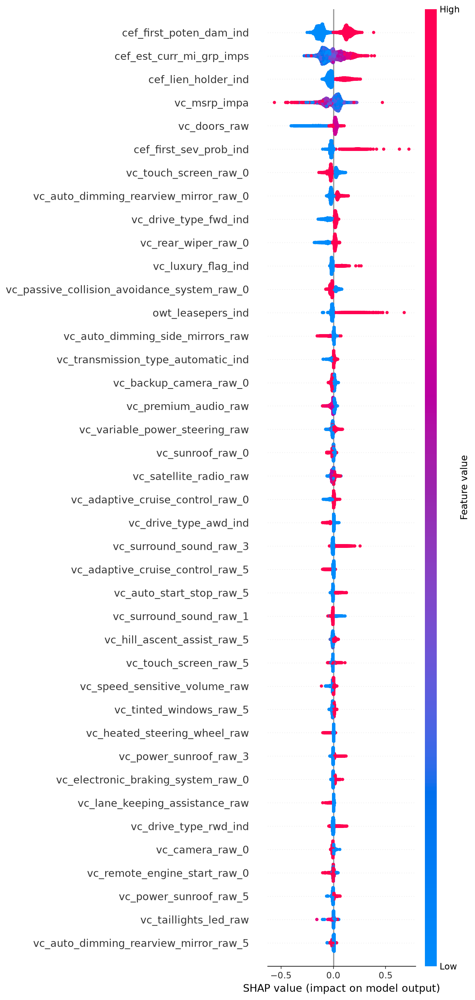

In [12]:
# SHAP Beeswarm Plot (standard - shows feature value impact)
print(f"\n{'='*60}")
print("SHAP BEESWARM PLOT")
print('='*60)
print("Note: Each dot = record. Color shows feature value (red=high, blue=low)")
print("X-axis shows SHAP value impact on prediction")
fig_beeswarm = create_shap_beeswarm(fc_tr, data_tr, top_n=top_n, weight_col='weight', max_display=top_n)
if fig_beeswarm:
    beeswarm_file = f'{plots_dir}/shap_beeswarm.png'
    fig_beeswarm.savefig(beeswarm_file, dpi=150, bbox_inches='tight')
    plt.close(fig_beeswarm)
    print(f"Saved: {beeswarm_file}")
    display(Image(beeswarm_file))
else:
    print("Warning: Could not create SHAP beeswarm plot")



SHAP FEATURE IMPORTANCE (%)
  Creating SHAP importance % chart for 9,479 rows...
  SHAP importance % chart created


Saved: output/car_liab/v1/plots/shap_importance_pct.png


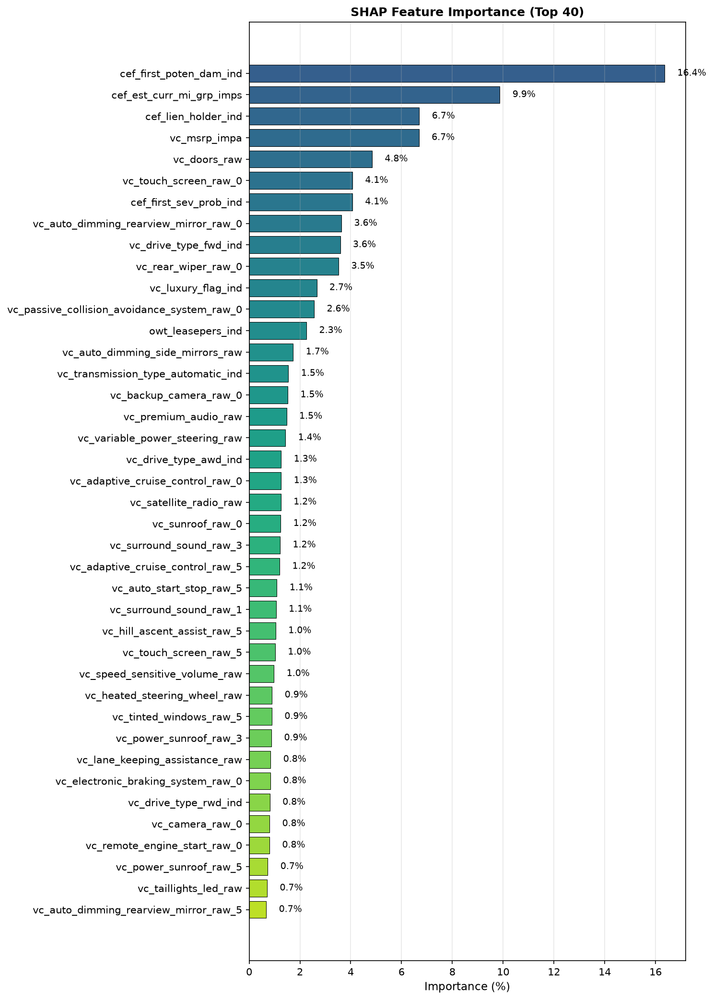

In [13]:
# SHAP Feature Importance (Percentage)
print(f"\n{'='*60}")
print("SHAP FEATURE IMPORTANCE (%)")
print('='*60)
fig_importance = create_shap_importance_pct(fc_tr, top_n=top_n, weight_col='weight')
if fig_importance:
    importance_file = f'{plots_dir}/shap_importance_pct.png'
    fig_importance.savefig(importance_file, dpi=150, bbox_inches='tight')
    plt.close(fig_importance)
    print(f"Saved: {importance_file}")
    display(Image(importance_file))
else:
    print("Warning: Could not create SHAP importance plot")


In [14]:
summary = {"timestamp": datetime.now().isoformat(), "plots": 0}
plots_by_feature = {}

In [15]:
print("="*60)
print("GENERATING PLOTS")
print("="*60)
for i, f in enumerate(features, 1):
    print(f"[{i}/{len(features)}] {f}")
    plots_by_feature[f] = []
    if f not in out_tr.columns or f not in out_te.columns:
        print(f"  WARNING: Feature {f} not found, skipping")
        continue
    if "train" in datasets:
        try:
            fig, _ = create_residual_plot(out_tr, f, "weight", dataset_label="Train", **resid_cfg)
            path = f"{plots_dir}/train_{f}_residual.png"
            fig.savefig(path, dpi=100, bbox_inches="tight")
            plt.close(fig)
            plots_by_feature[f].append(path)
            summary["plots"] += 1
        except Exception as e:
            print(f"  ERROR (Train Residual): {e}")
        try:
            fig, _ = create_shap_range_plot(fc_tr, data_tr, f, "weight", dataset_label="Train", **shap_range_cfg)
            path = f"{plots_dir}/train_{f}_shap_range.png"
            fig.savefig(path, dpi=100, bbox_inches="tight")
            plt.close(fig)
            plots_by_feature[f].append(path)
            summary["plots"] += 1
        except Exception as e:
            print(f"  ERROR (Train SHAP): {e}")
    if "test" in datasets:
        try:
            fig, _ = create_residual_plot(out_te, f, "weight", dataset_label="Test", **resid_cfg)
            path = f"{plots_dir}/test_{f}_residual.png"
            fig.savefig(path, dpi=100, bbox_inches="tight")
            plt.close(fig)
            plots_by_feature[f].append(path)
            summary["plots"] += 1
        except Exception as e:
            print(f"  ERROR (Test Residual): {e}")
        try:
            fig, _ = create_shap_range_plot(fc_te, data_te, f, "weight", dataset_label="Test", **shap_range_cfg)
            path = f"{plots_dir}/test_{f}_shap_range.png"
            fig.savefig(path, dpi=100, bbox_inches="tight")
            plt.close(fig)
            plots_by_feature[f].append(path)
            summary["plots"] += 1
        except Exception as e:
            print(f"  ERROR (Test SHAP): {e}")
print(f"\n[OK] Generated summary")

GENERATING PLOTS
[1/40] cef_first_poten_dam_ind

cef_first_poten_dam_ind Summary:
 cef_first_poten_dam_ind      weight   act_rate  pred_rate
                     0.0 3388.413628 204.002681 150.901912
                     1.0 2518.855847  41.783006 240.203041


/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  c['SHAP'].fillna(lowest_contrib, inplace=True)
/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace 


cef_first_poten_dam_ind Summary:
 cef_first_poten_dam_ind       weight   act_rate  pred_rate
                     0.0 1.540147e+06 216.219665 148.076037
                     1.0 1.136186e+06 383.644073 245.914239


/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  c['SHAP'].fillna(lowest_contrib, inplace=True)
/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace 

[2/40] cef_est_curr_mi_grp_imps

cef_est_curr_mi_grp_imps Summary:
cef_est_curr_mi_grp_imps     weight   act_rate  pred_rate
     (6401.999, 20460.8] 450.287576 745.016039 153.402641
      (20460.8, 31287.2] 315.971489   3.796025 147.547717
      (31287.2, 40196.2] 386.663714  76.954298 152.441947
      (40196.2, 48458.0] 369.964057   0.000000 120.369865
      (48458.0, 55230.0] 478.618511 609.094143 166.583847
      (55230.0, 60125.4] 470.388410  35.681629 171.070760
      (60125.4, 69234.4] 315.376194  48.296131 142.870740
      (69234.4, 84984.0] 524.657055  42.283365 203.910147
      (84984.0, 99629.6] 435.102061   5.742554 197.706033
     (99629.6, 110000.0] 553.698317   0.000000 214.926048
    (110000.0, 120121.2] 303.888194  19.962153 193.922118
    (120121.2, 132000.0] 473.941392 154.734197 165.207214
    (132000.0, 163000.0] 374.595506   0.000000 279.537118
    (163000.0, 194000.0] 231.762549  10.532426 297.687303
    (194000.0, 225000.0] 122.444877   0.000000 335.571276
    (

...

[40/40] vc_auto_dimming_rearview_mirror_raw_5

vc_auto_dimming_rearview_mirror_raw_5 Summary:
 vc_auto_dimming_rearview_mirror_raw_5      weight   act_rate  pred_rate
                                   0.0 3955.863565 127.025539 197.577393
                                   1.0 1951.405909 150.658112 171.551042


/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  c['SHAP'].fillna(lowest_contrib, inplace=True)
/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace 


vc_auto_dimming_rearview_mirror_raw_5 Summary:
 vc_auto_dimming_rearview_mirror_raw_5       weight   act_rate  pred_rate
                                   0.0 1.784593e+06 303.731670 199.862746
                                   1.0 8.917400e+05 254.405654 169.095849


/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  c['SHAP'].fillna(lowest_contrib, inplace=True)
/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace 


[OK] Generated summary



DISPLAYING ALL PLOTS

FEATURE: cef_first_poten_dam_ind


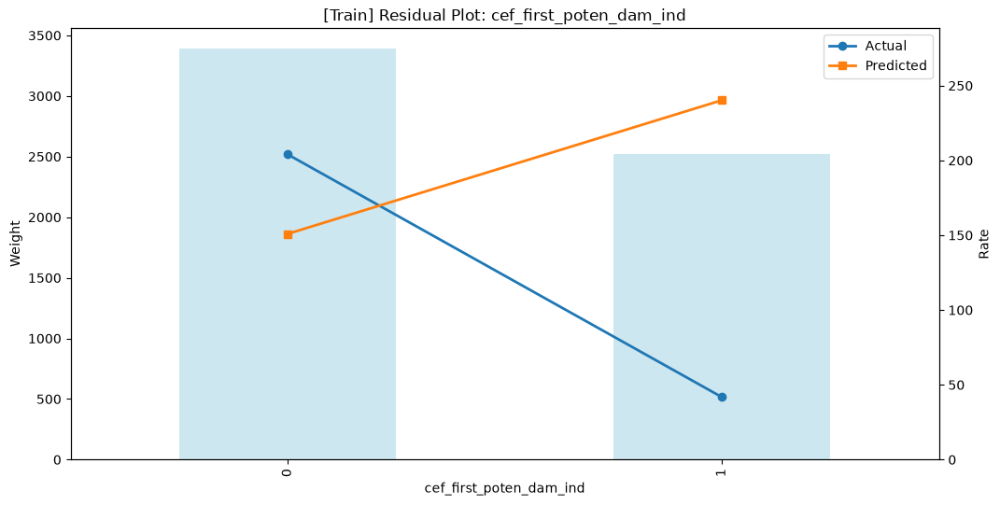

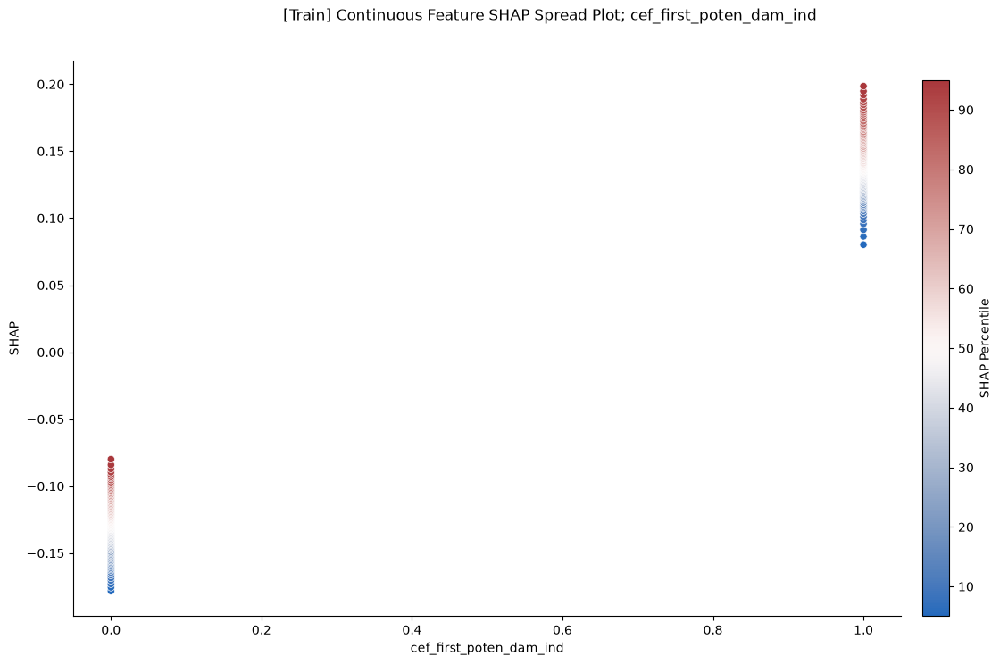

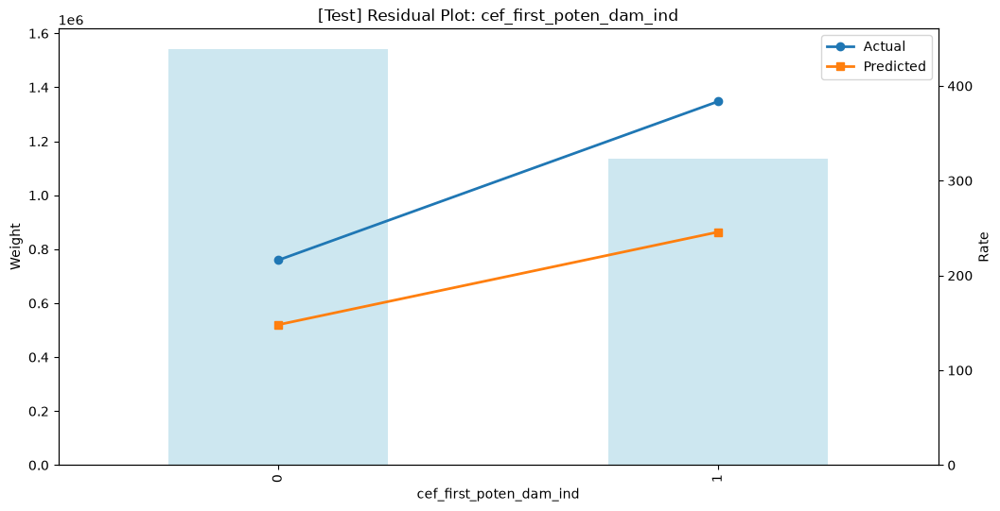

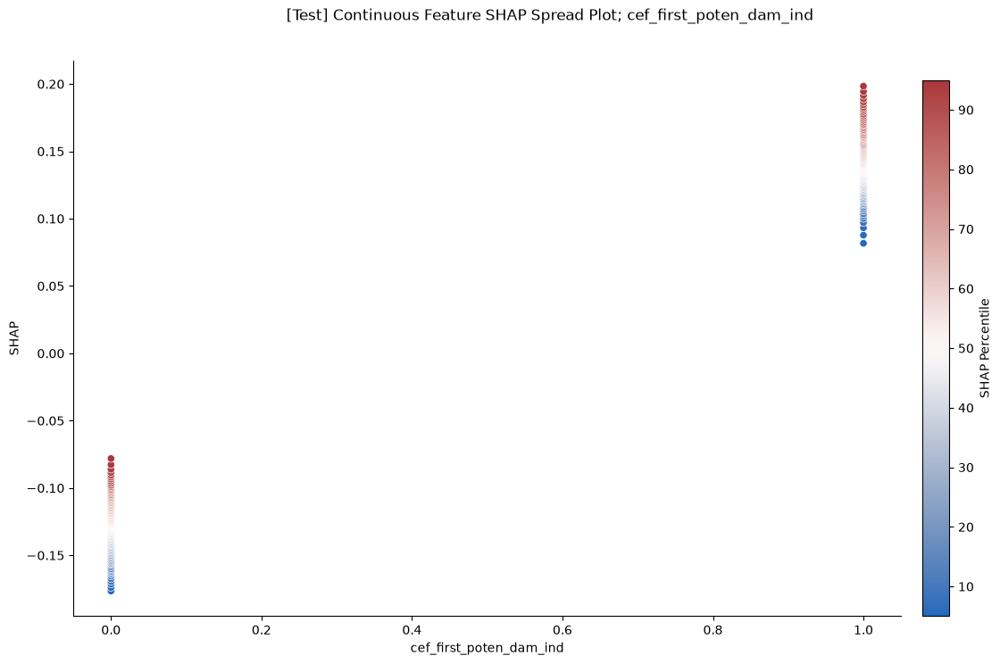


FEATURE: cef_est_curr_mi_grp_imps


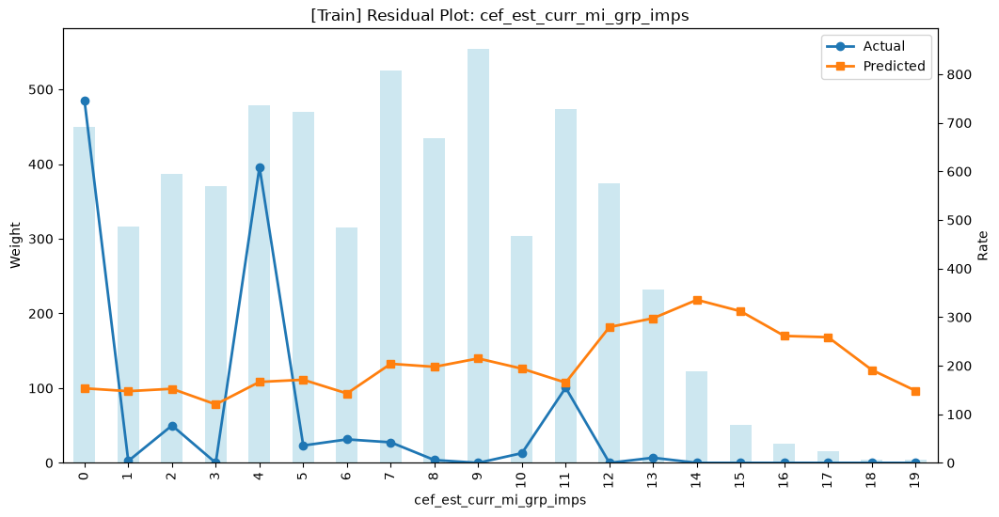

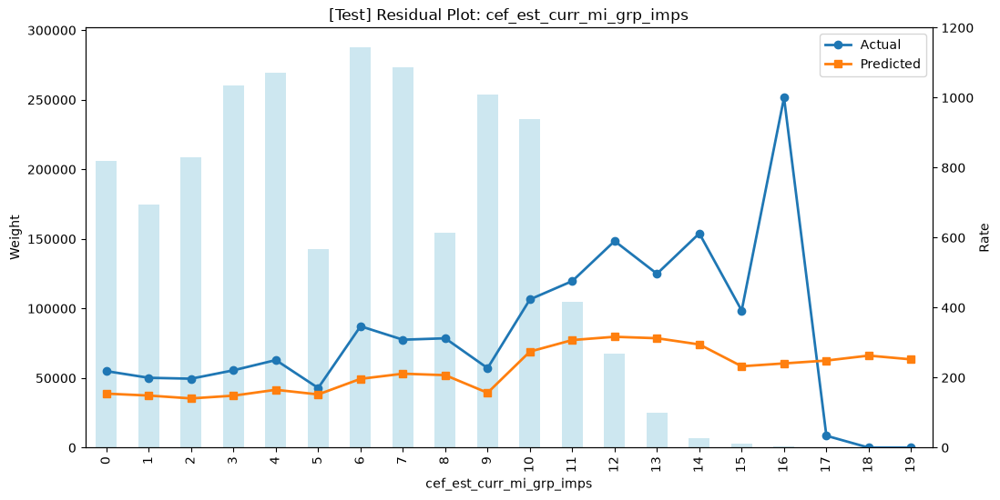


FEATURE: cef_lien_holder_ind


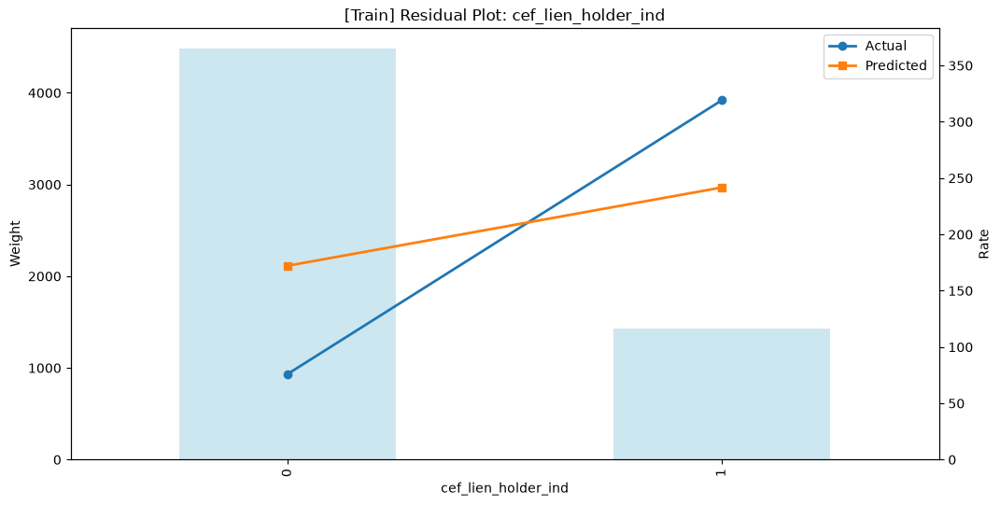

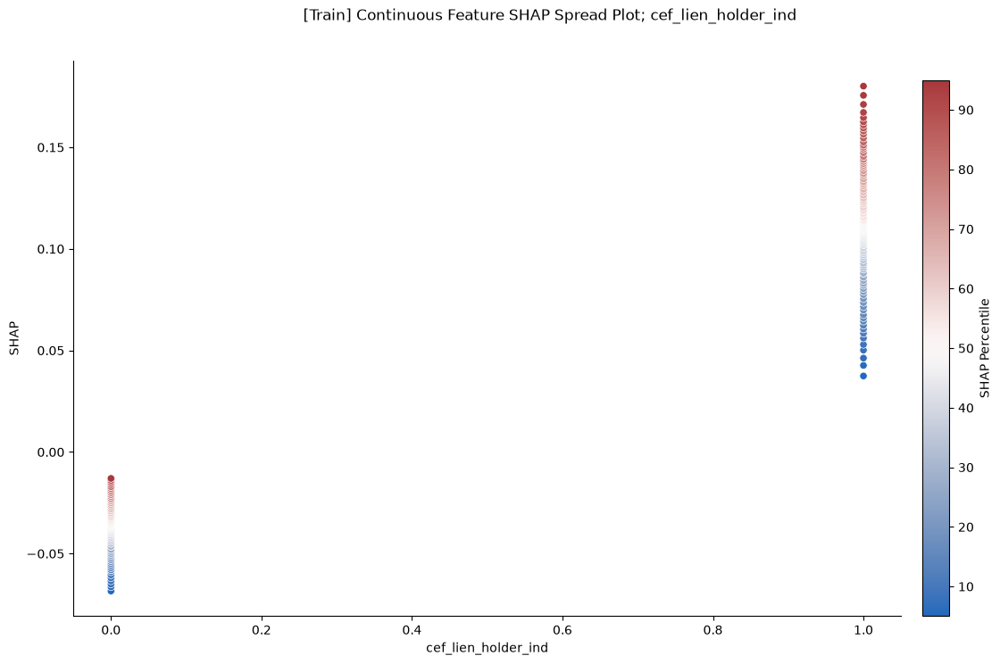

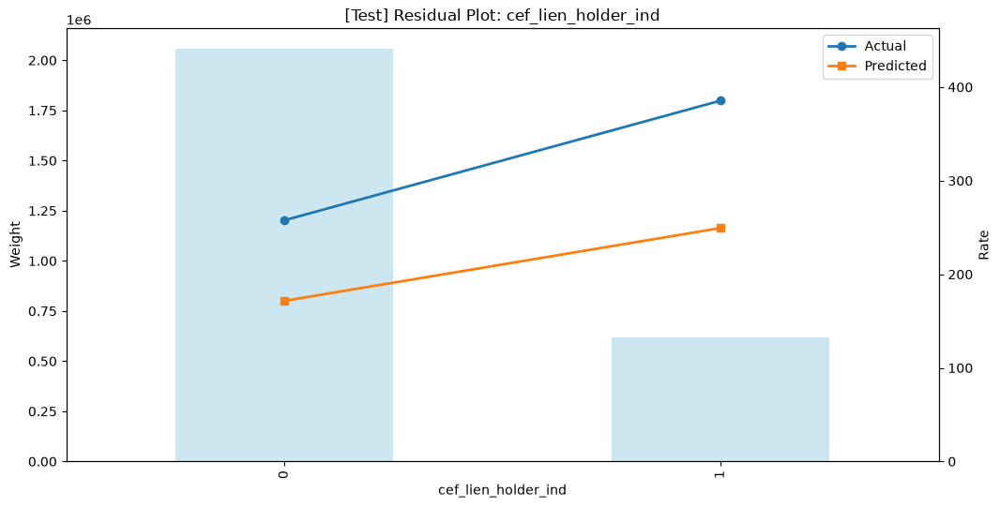

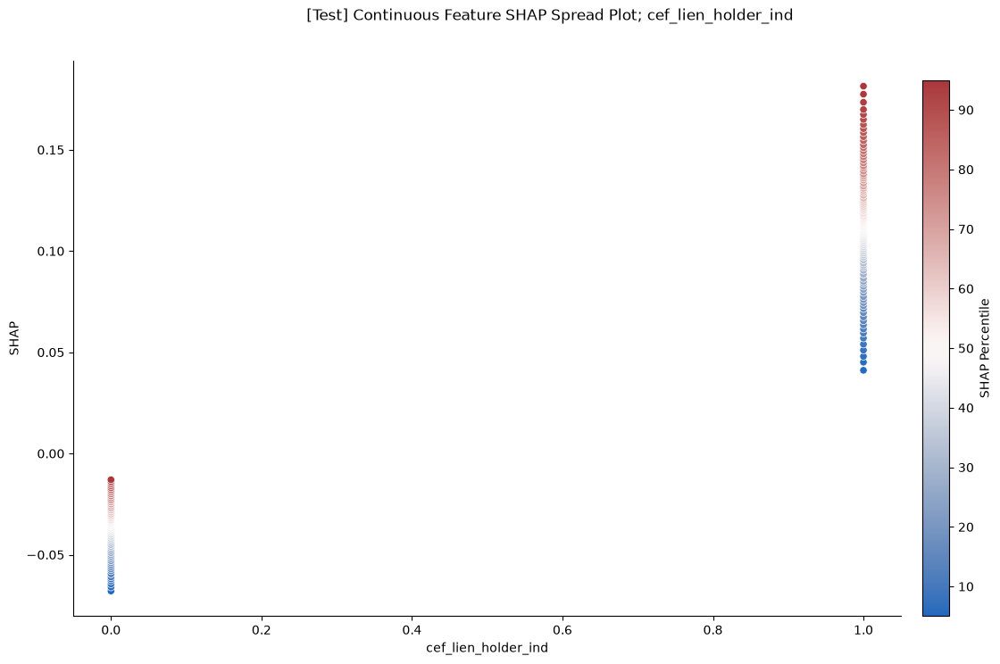


FEATURE: vc_msrp_impa


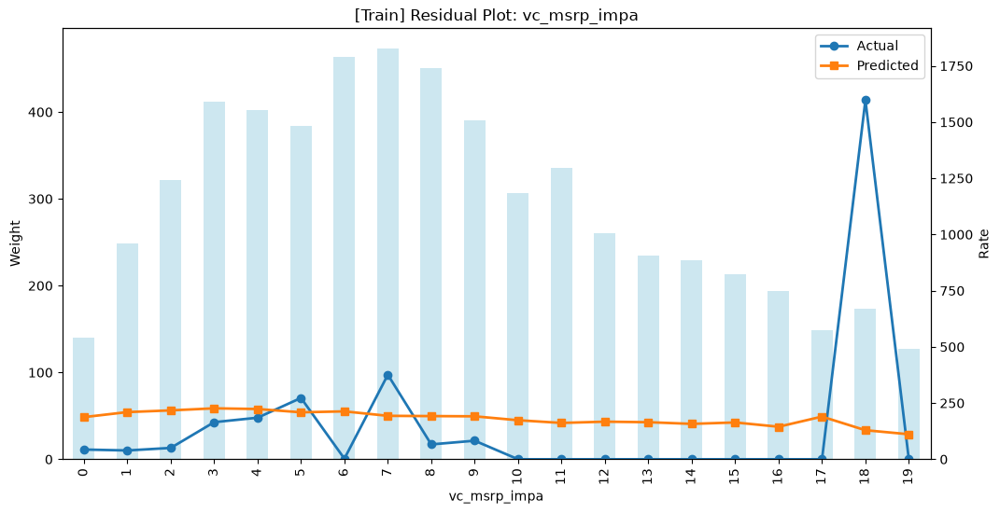

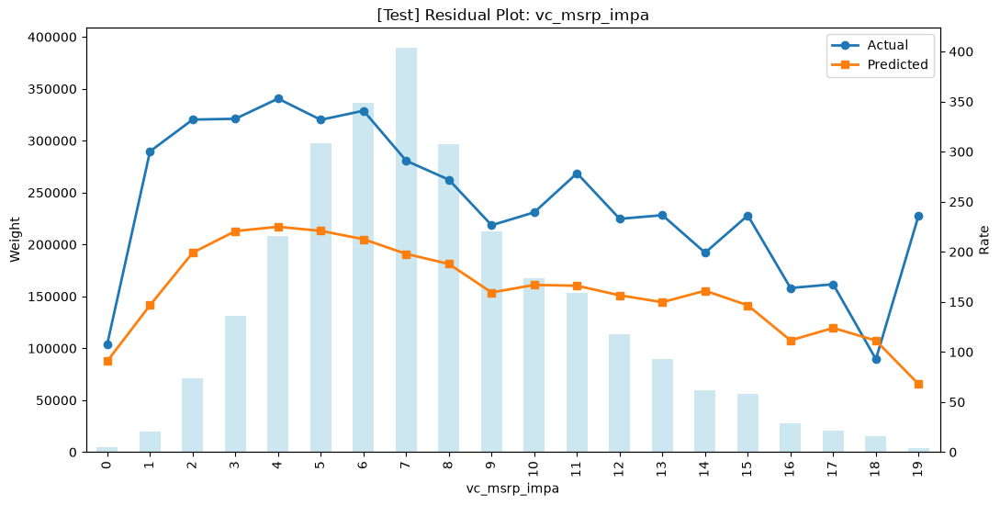


FEATURE: vc_doors_raw


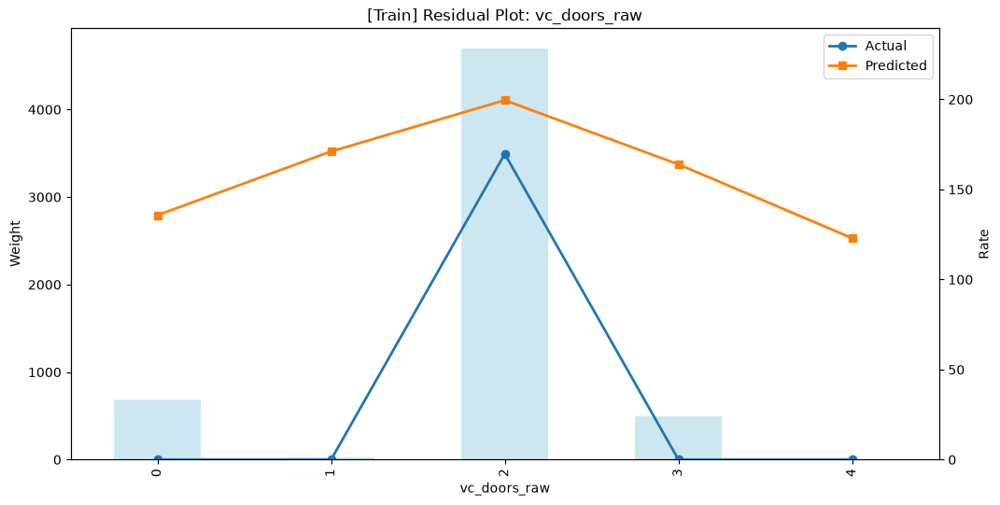

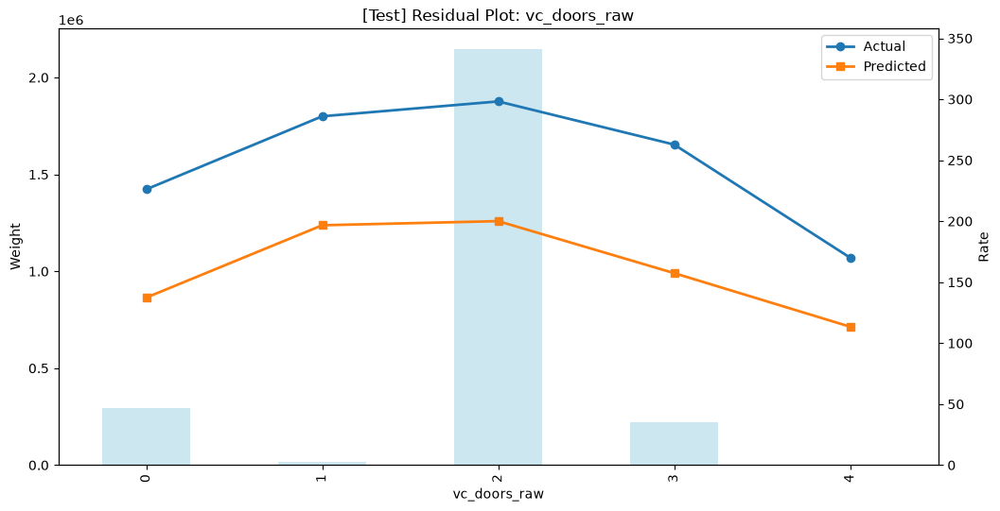

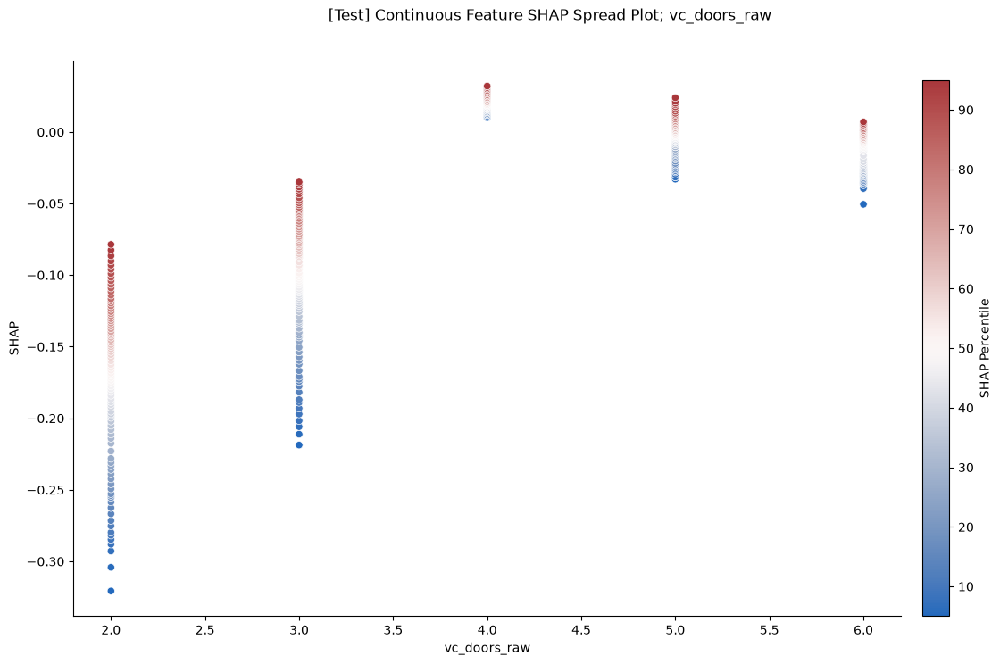


FEATURE: vc_touch_screen_raw_0


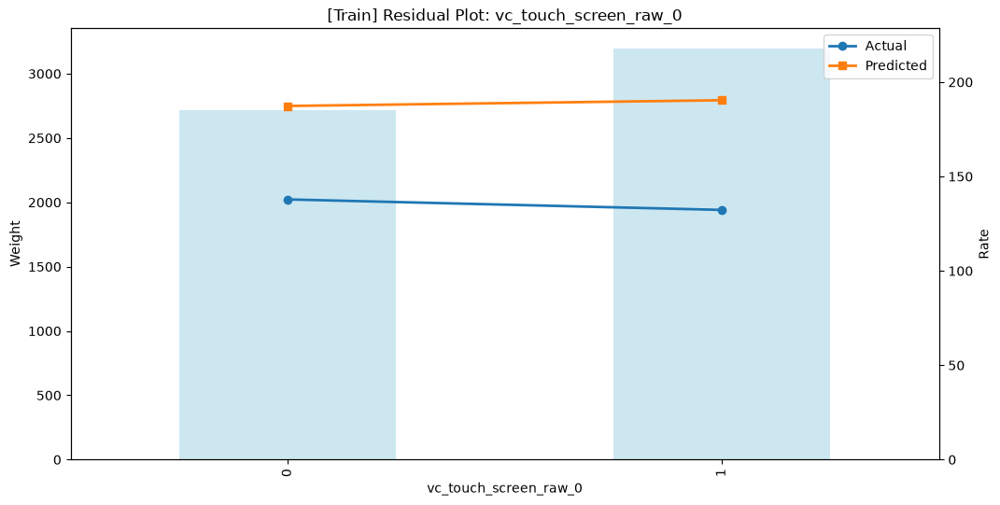

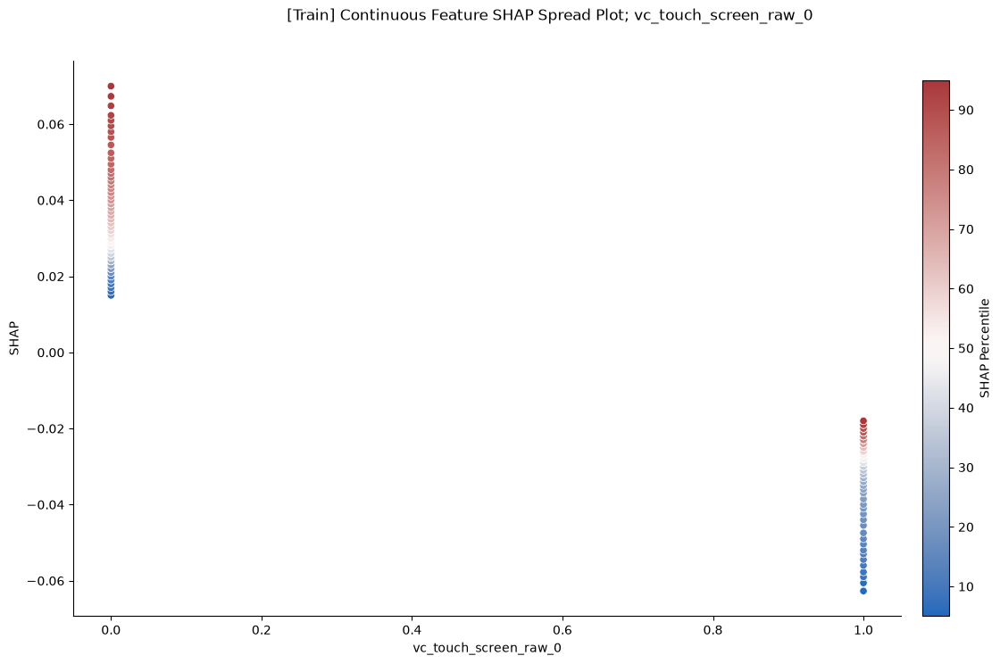

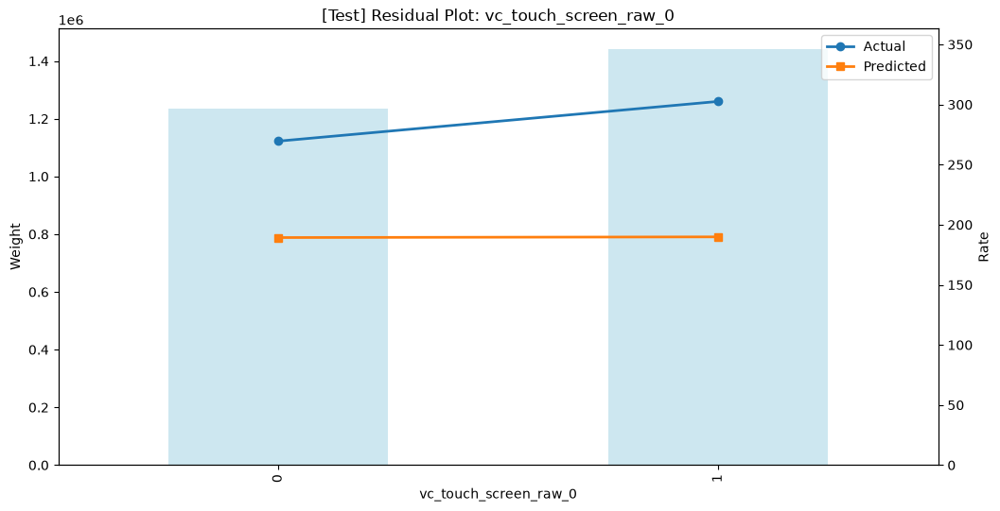

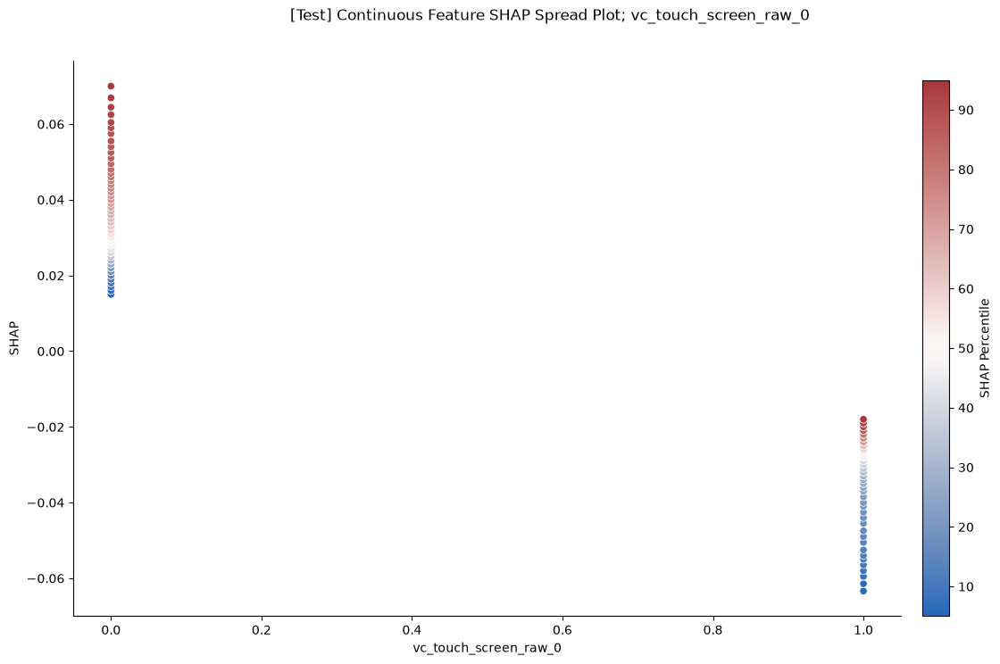


FEATURE: cef_first_sev_prob_ind


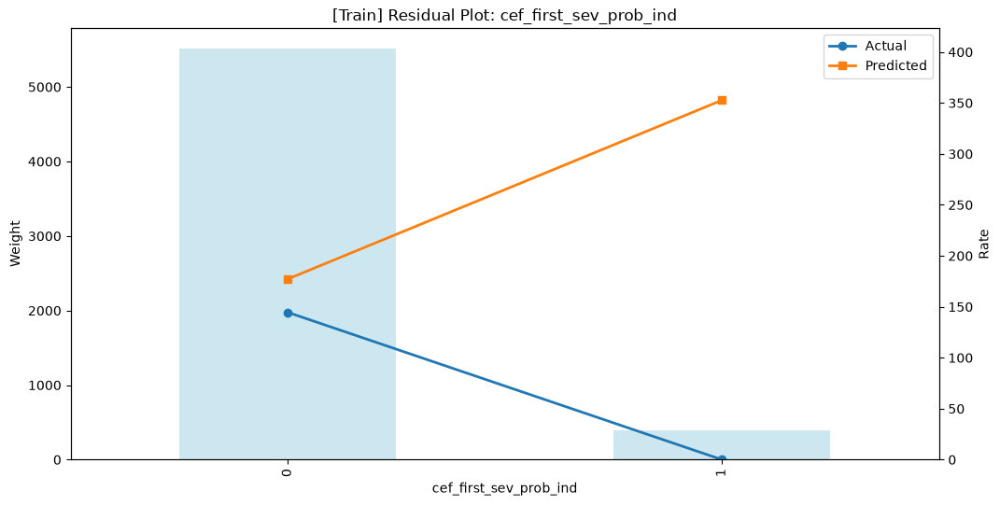

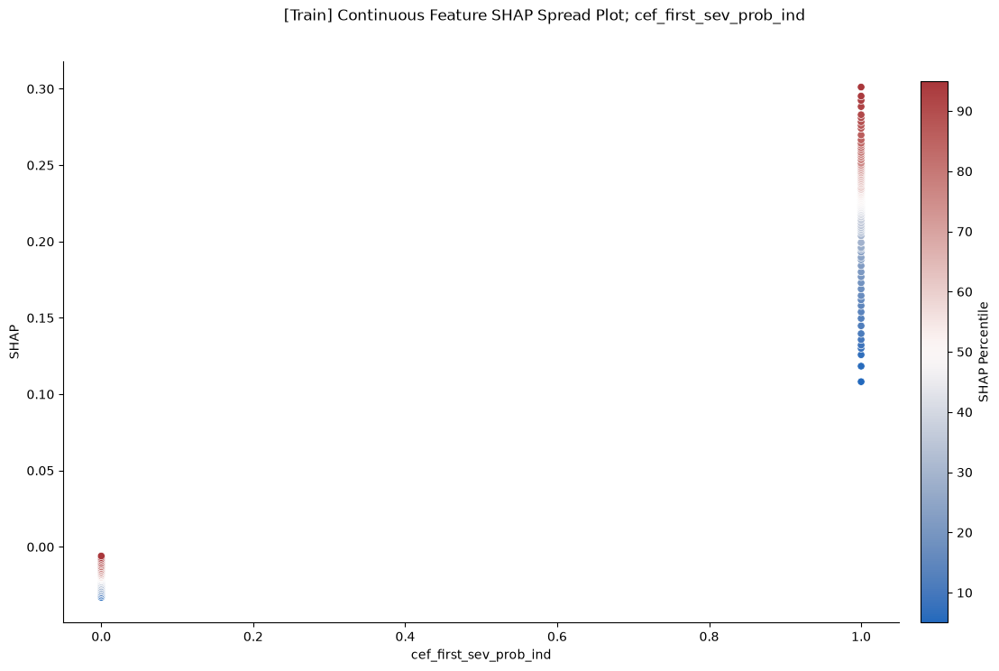

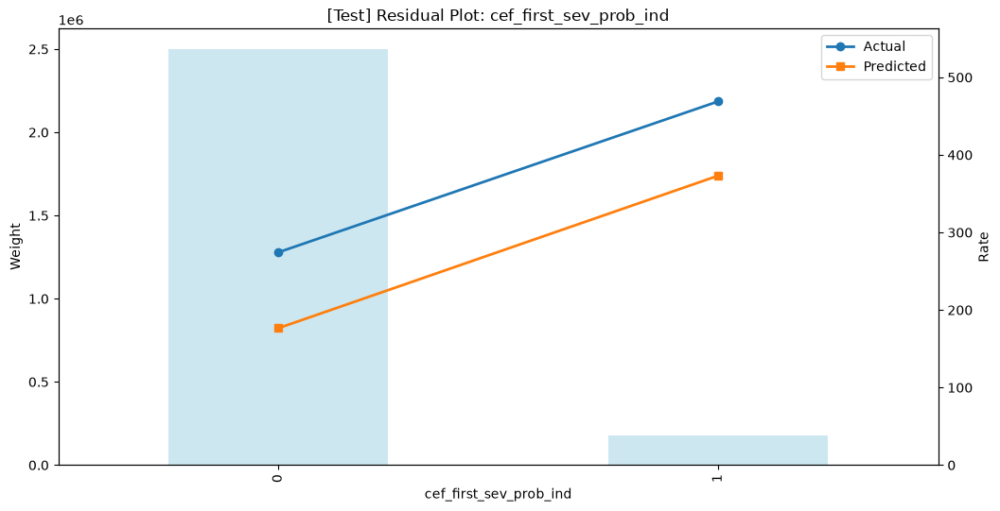

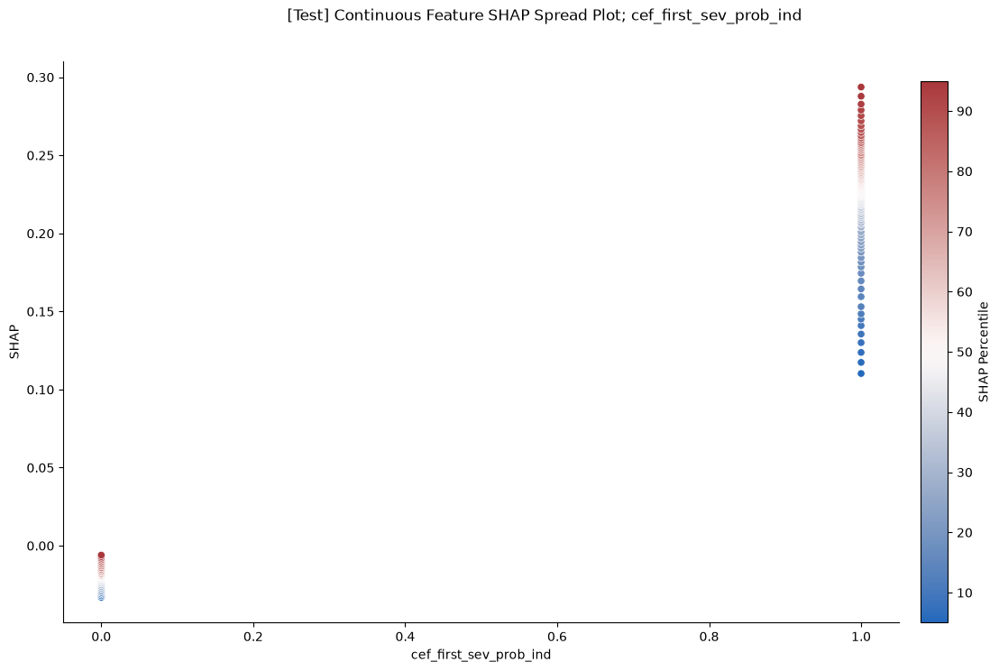


FEATURE: vc_auto_dimming_rearview_mirror_raw_0


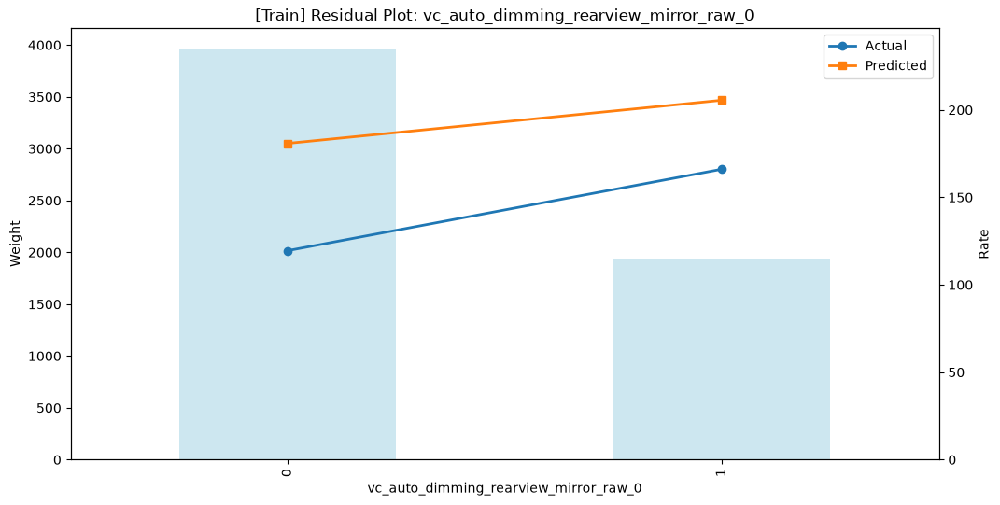

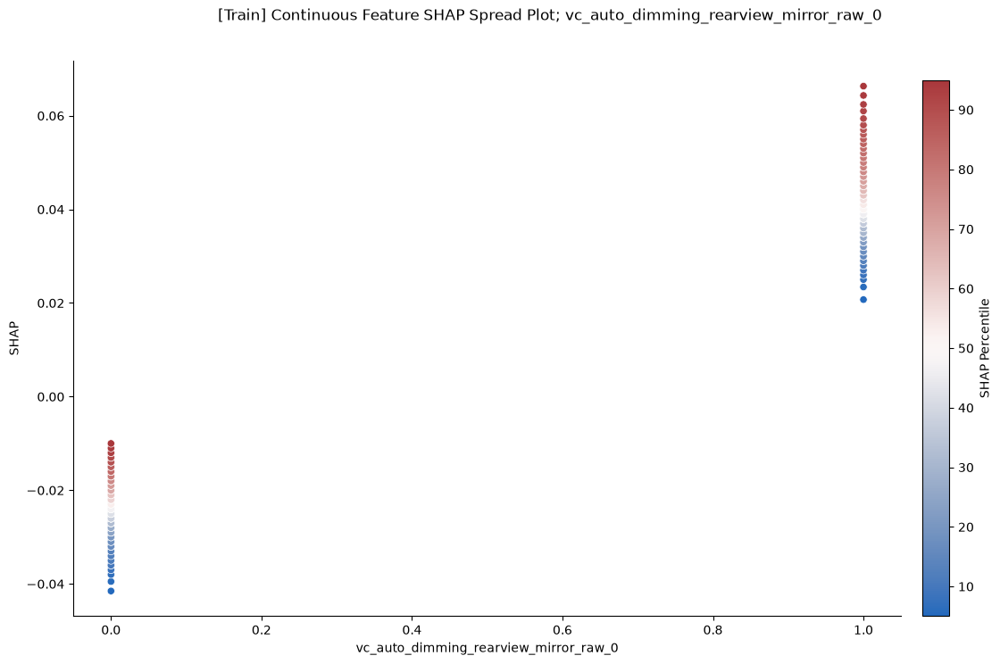

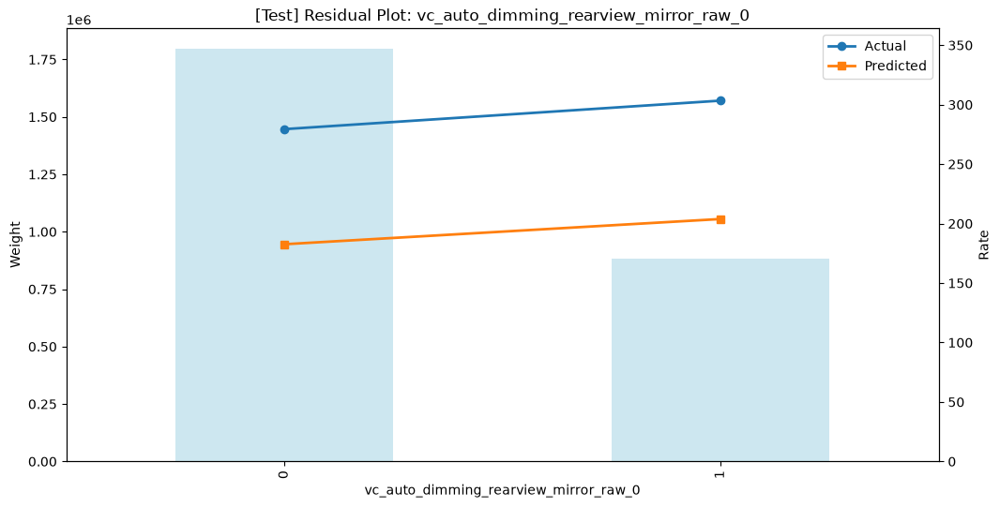

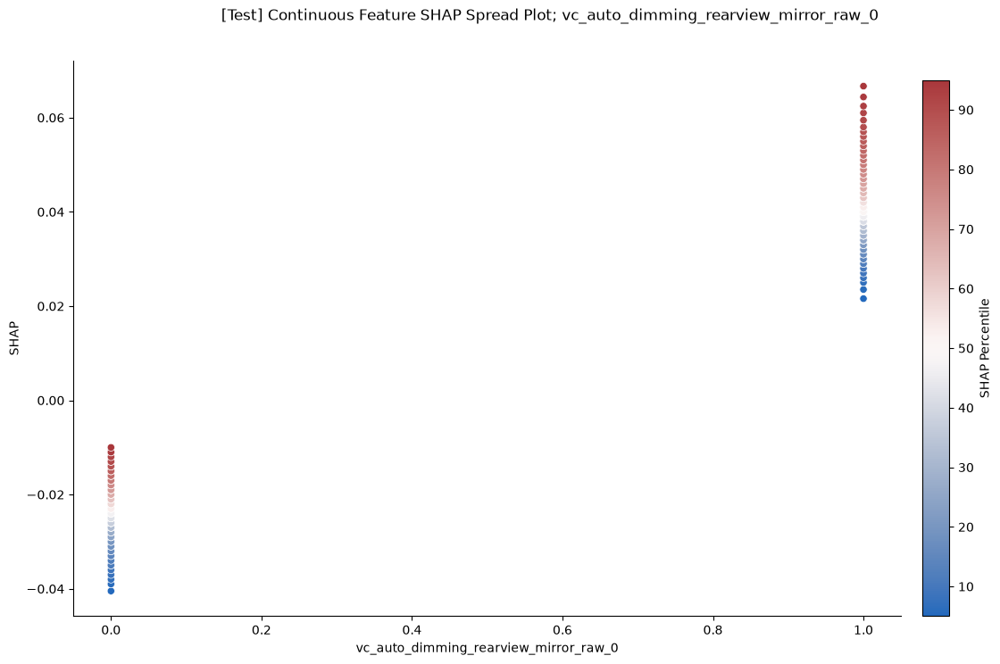


FEATURE: vc_drive_type_fwd_ind


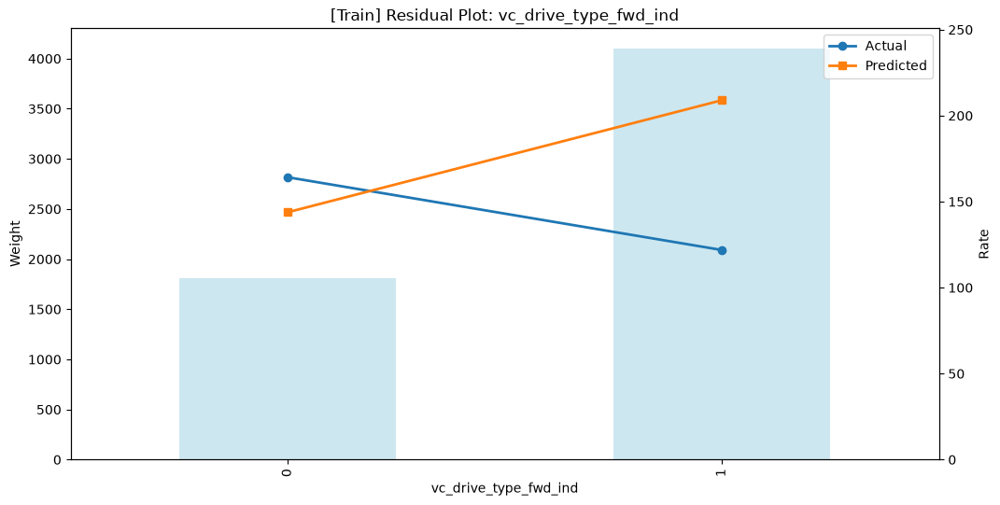

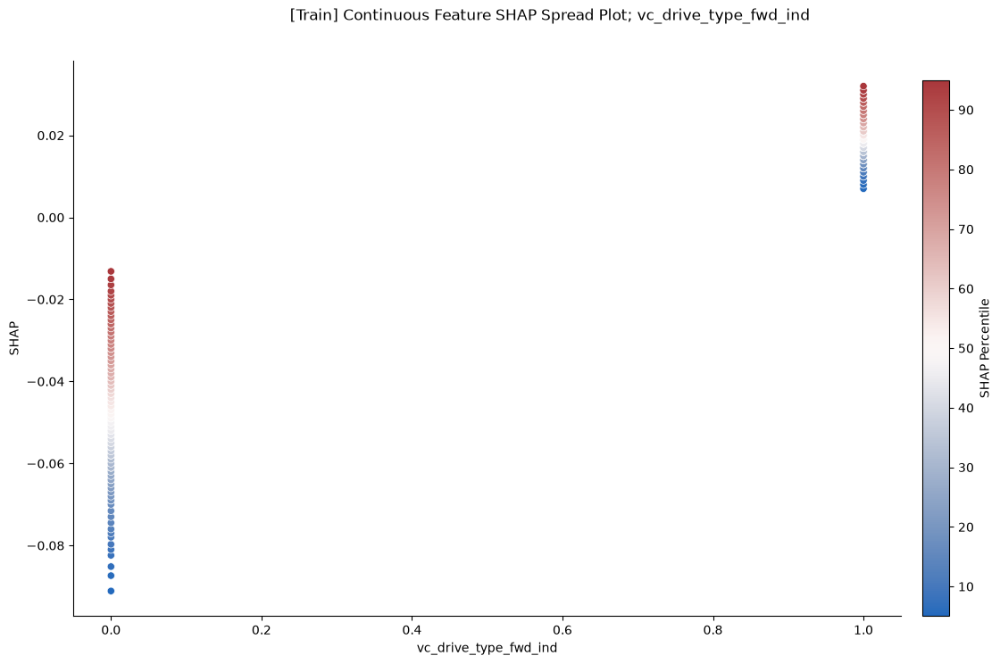

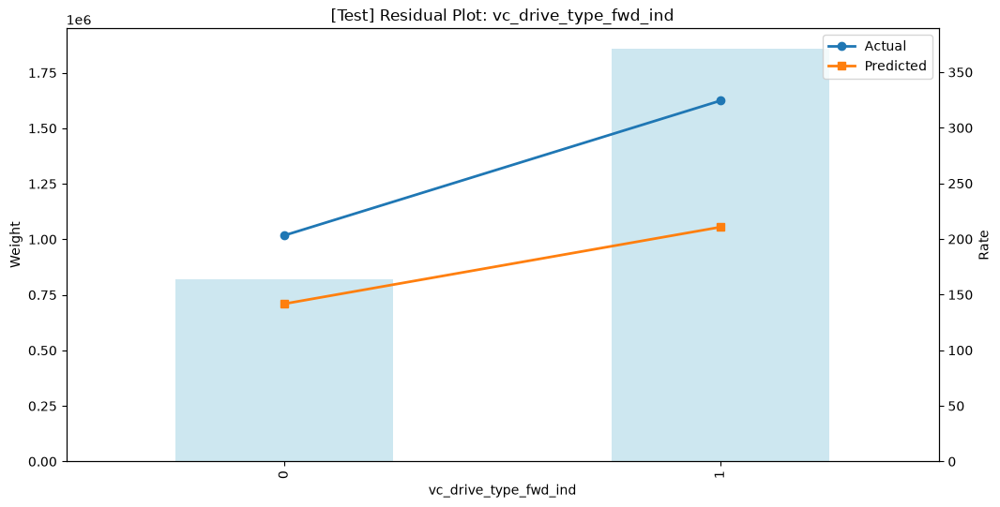

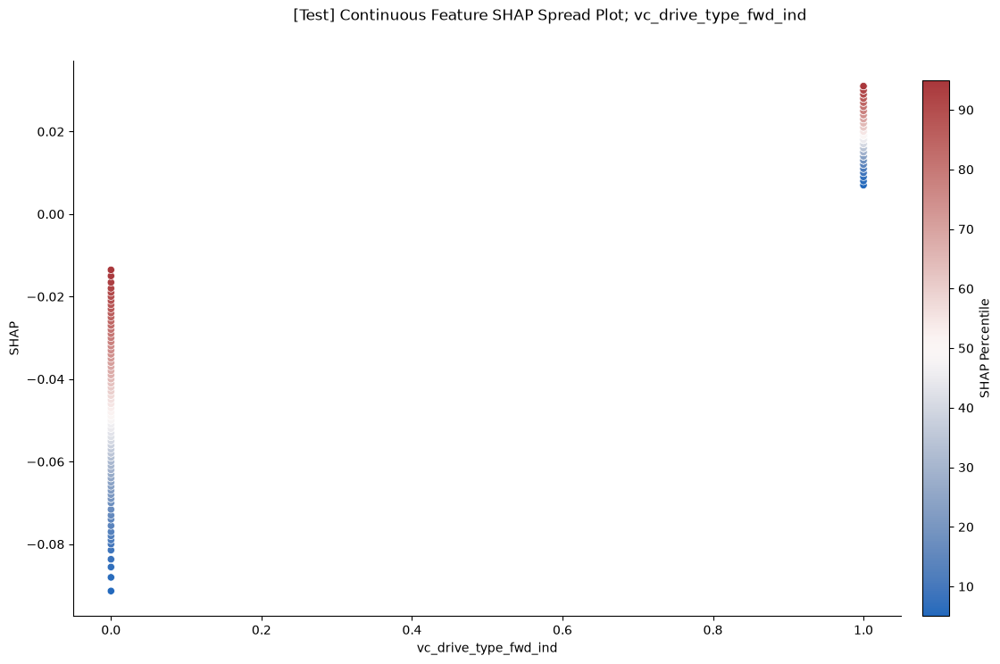


FEATURE: vc_rear_wiper_raw_0


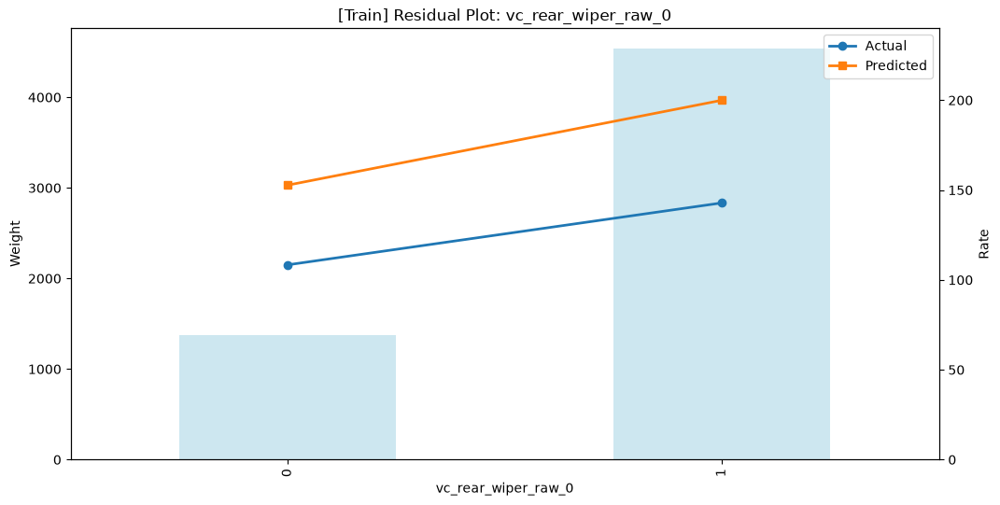

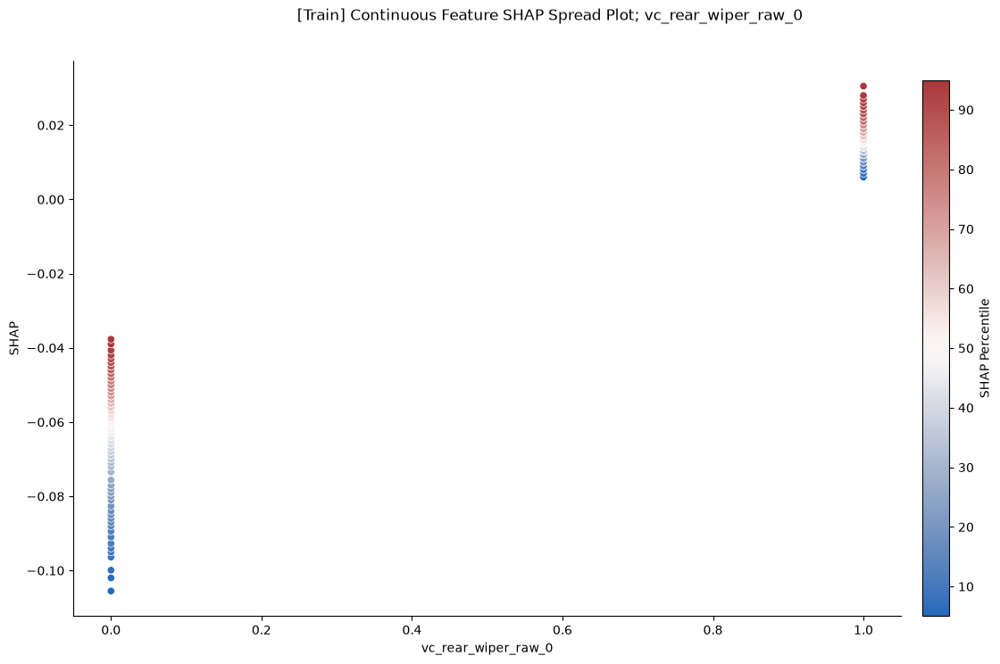

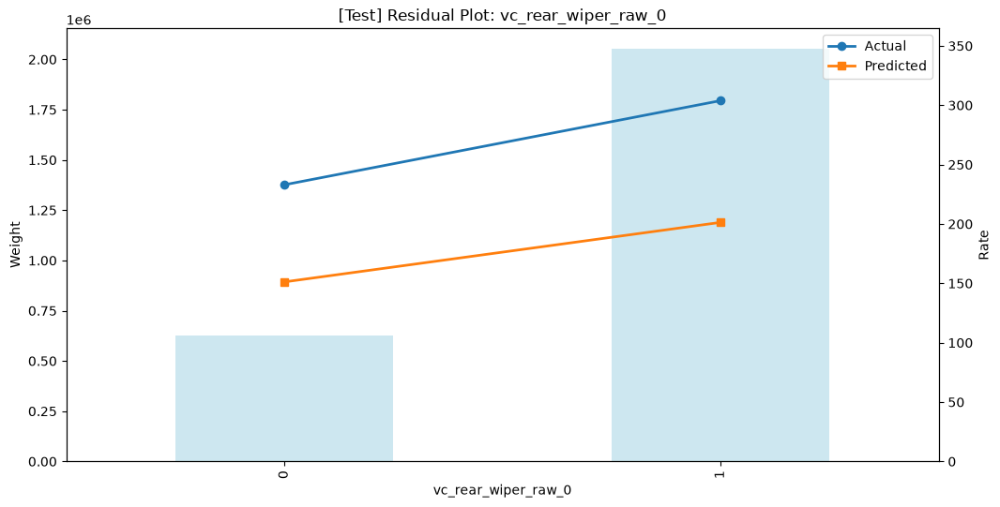

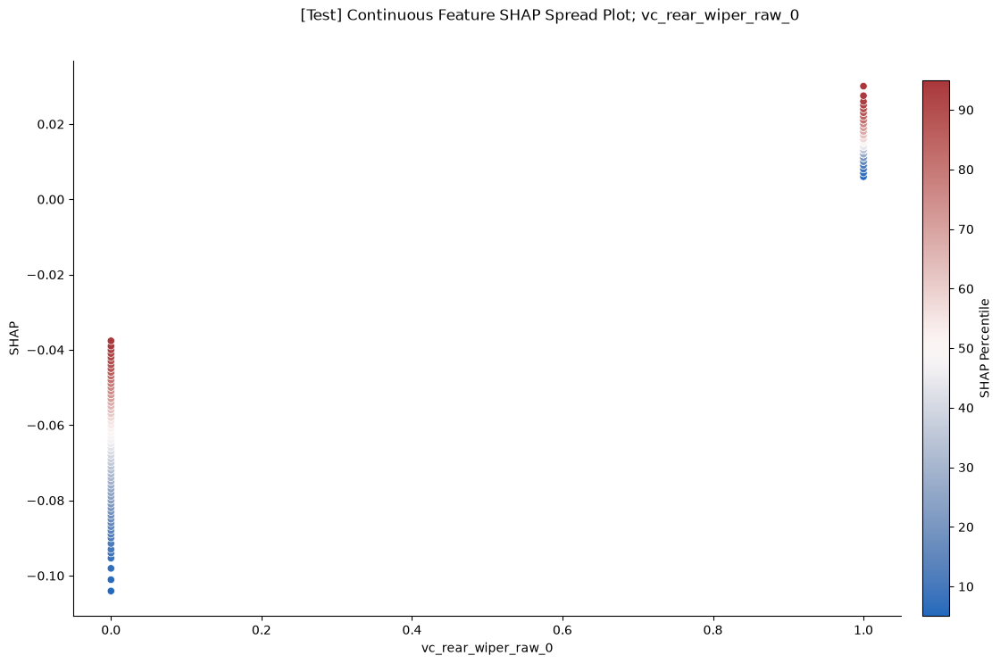


FEATURE: vc_luxury_flag_ind


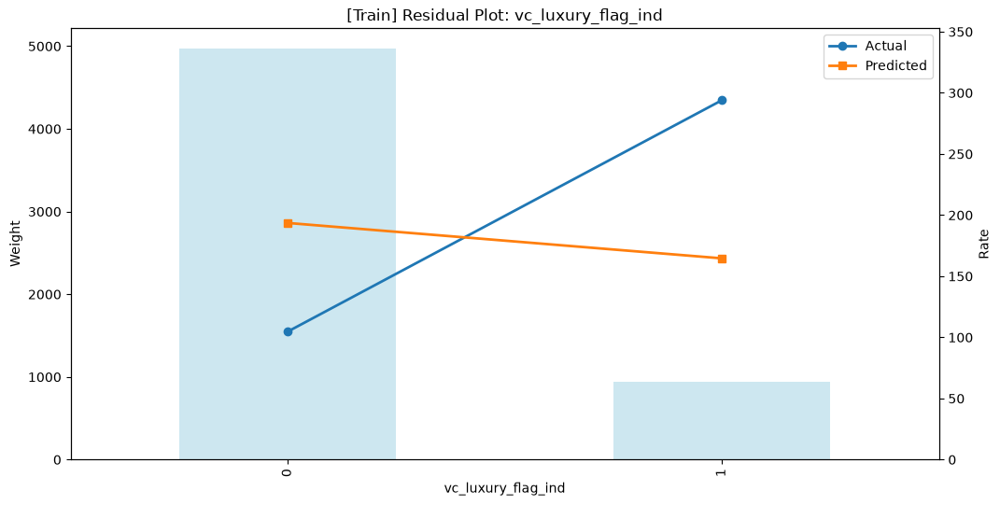

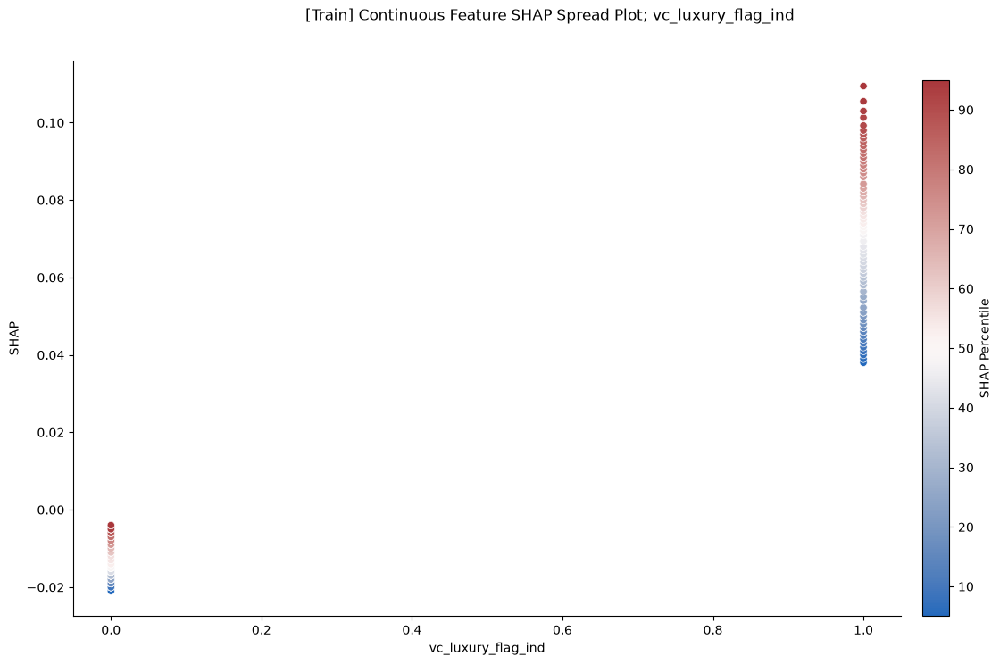

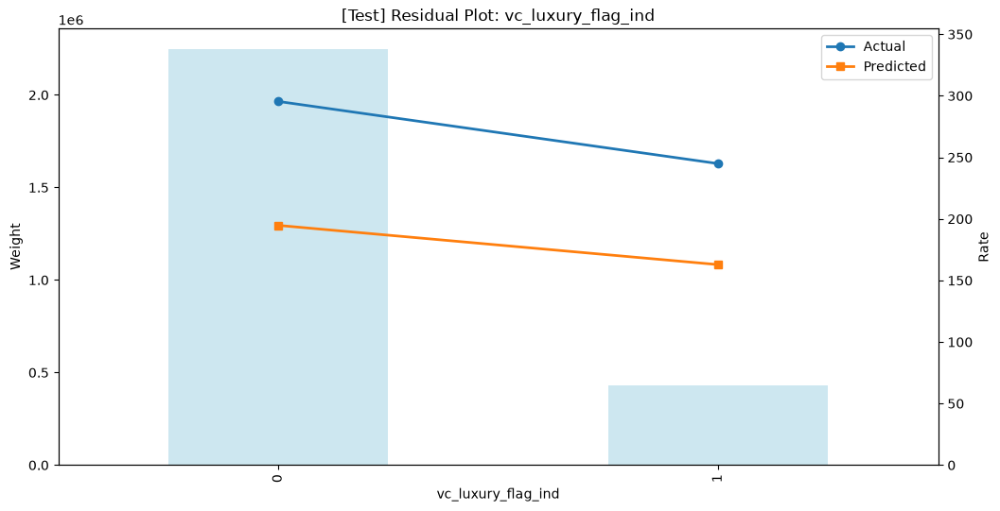

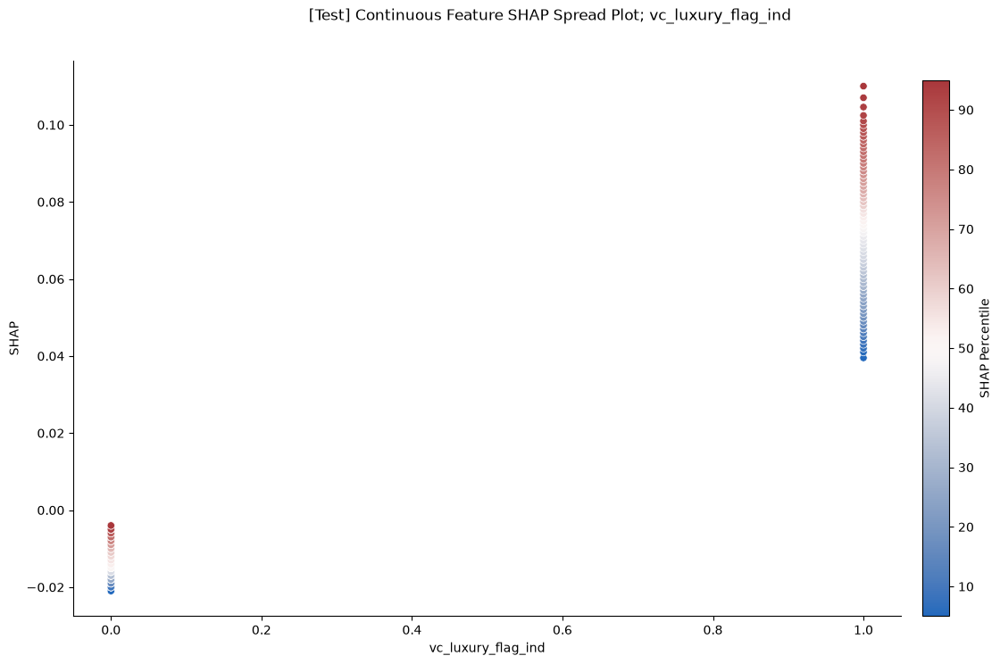


FEATURE: vc_passive_collision_avoidance_system_raw_0


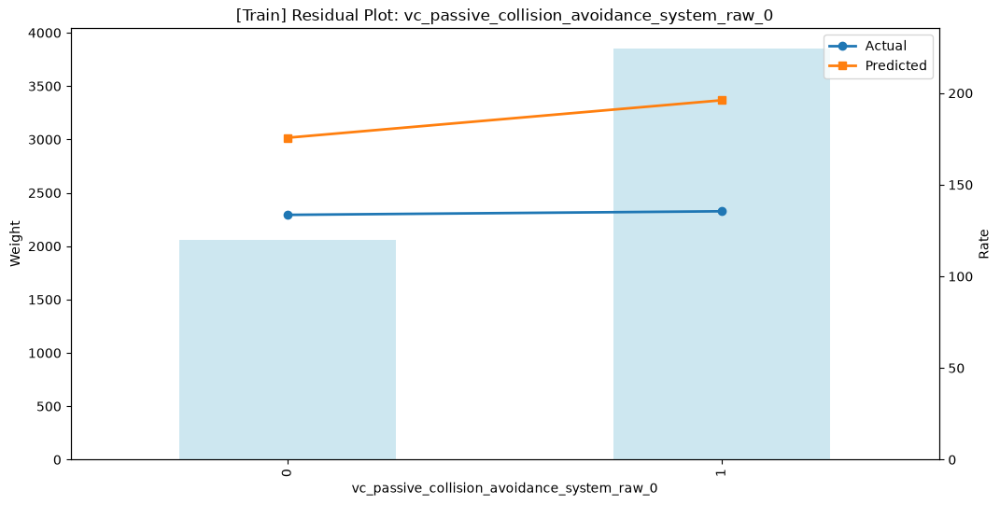

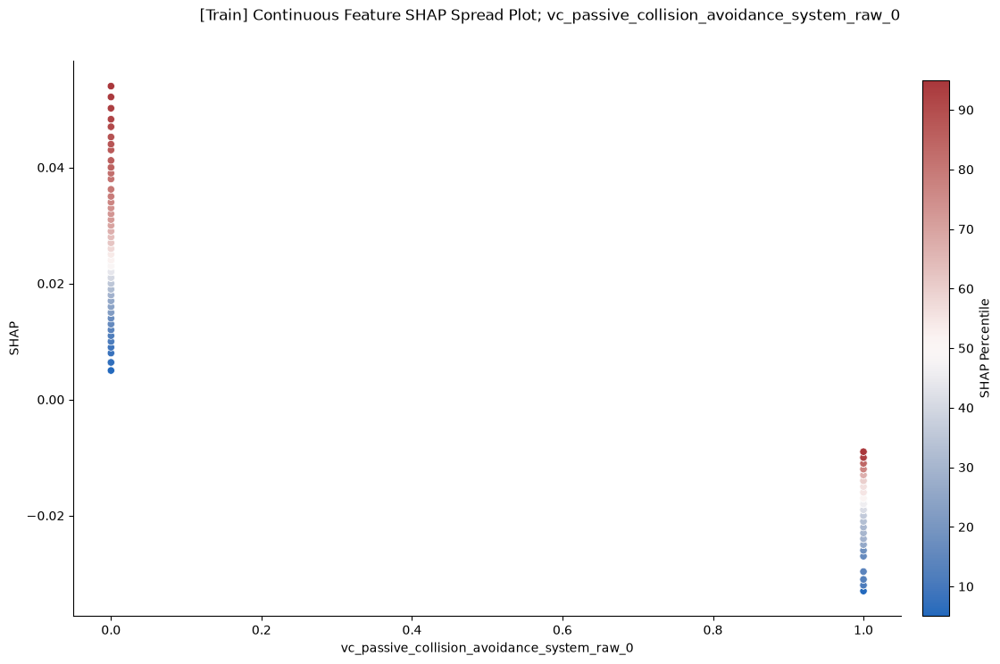

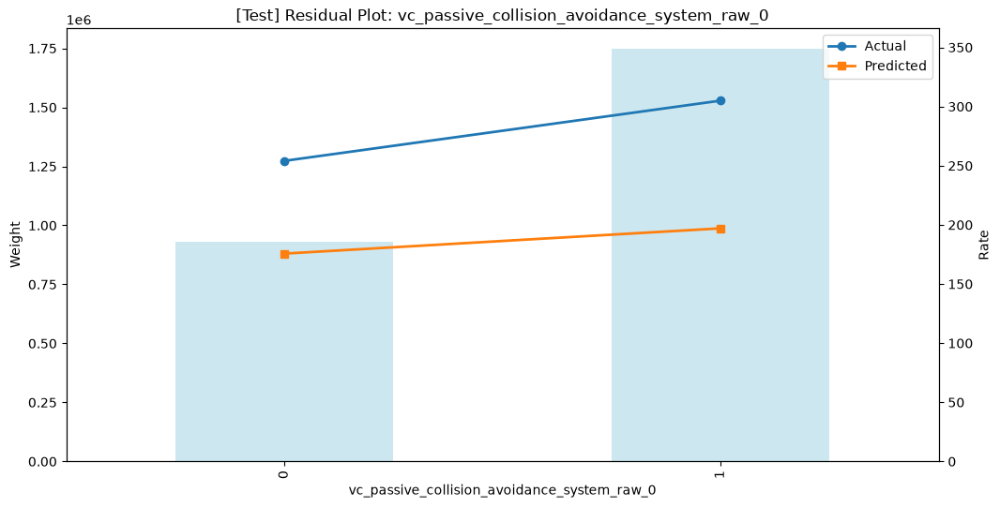

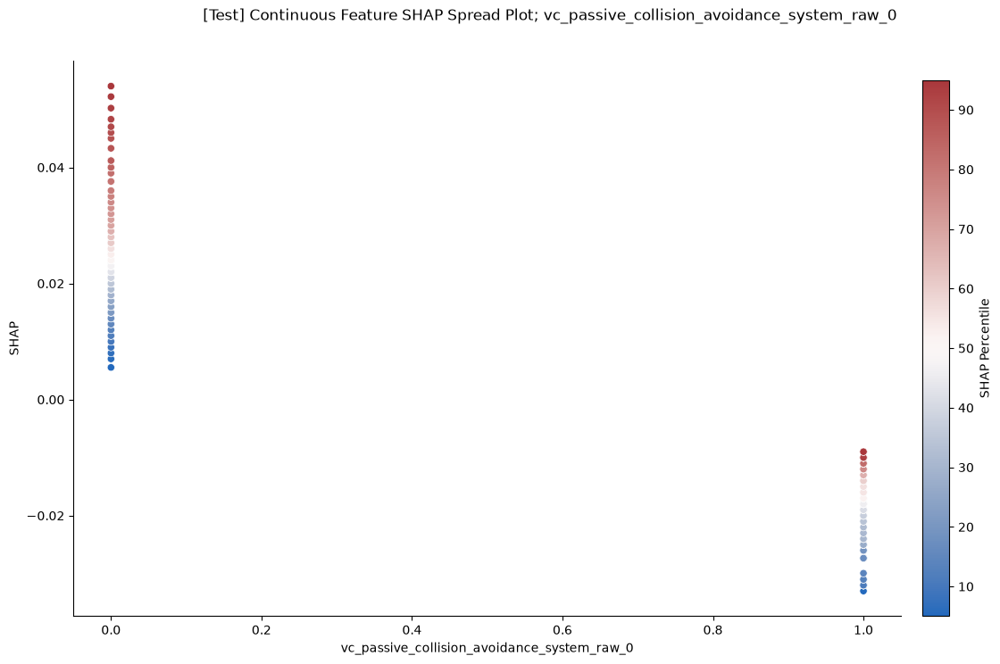


FEATURE: owt_leasepers_ind


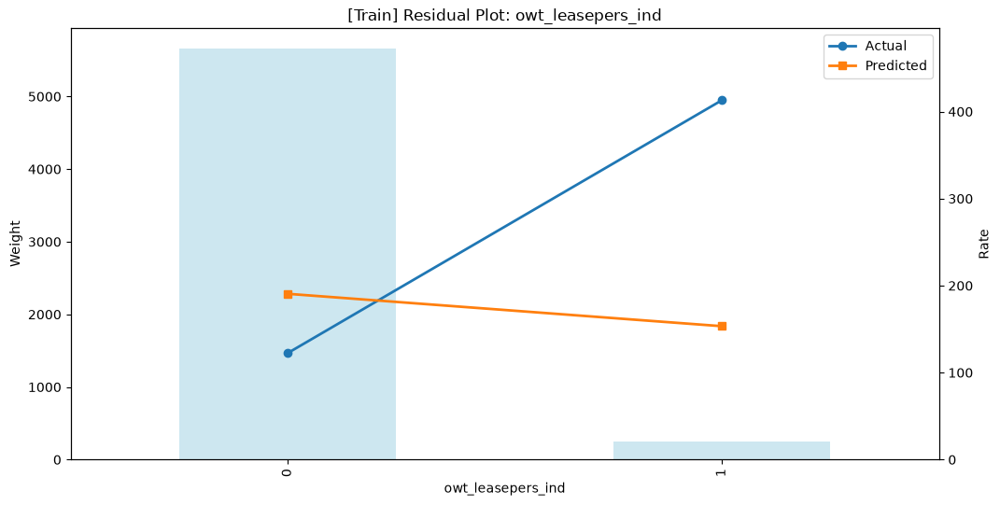

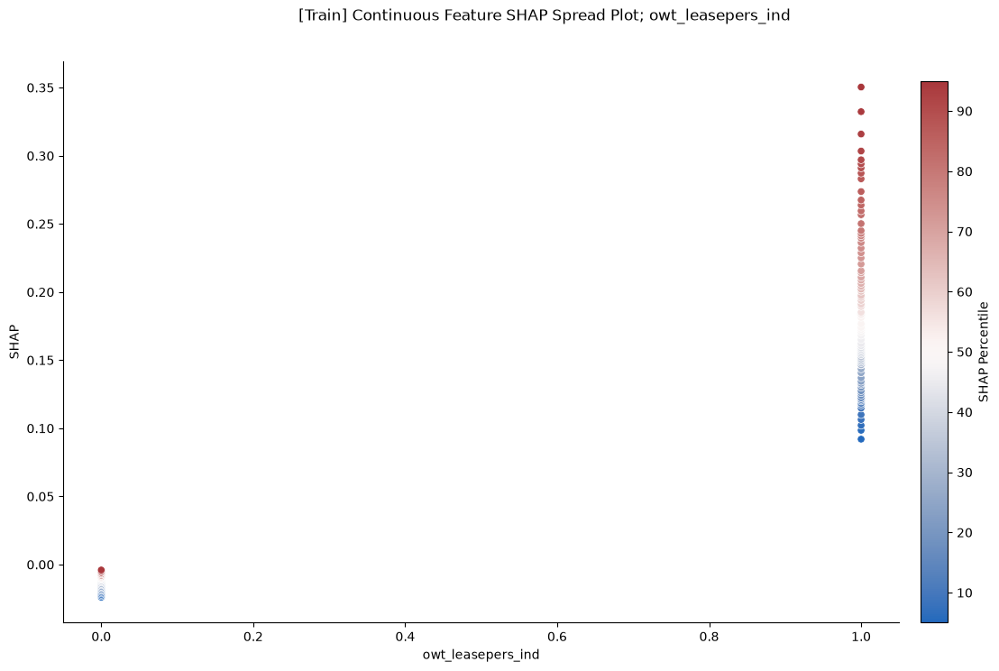

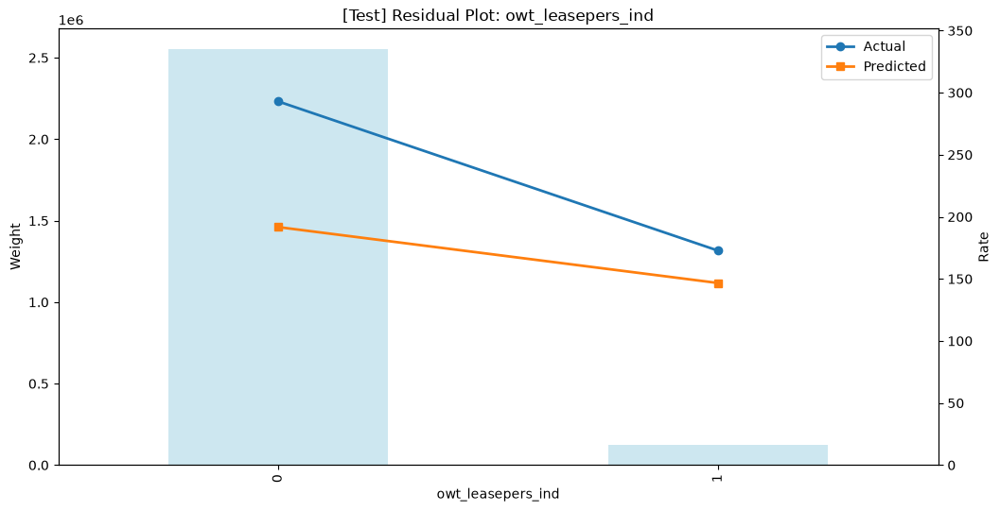

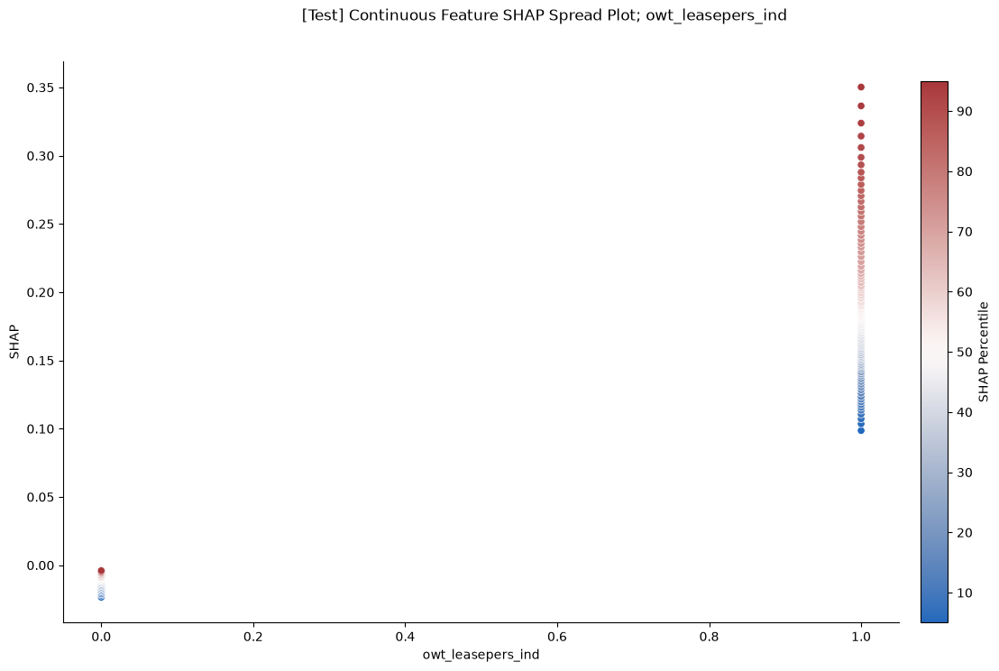


FEATURE: vc_auto_dimming_side_mirrors_raw


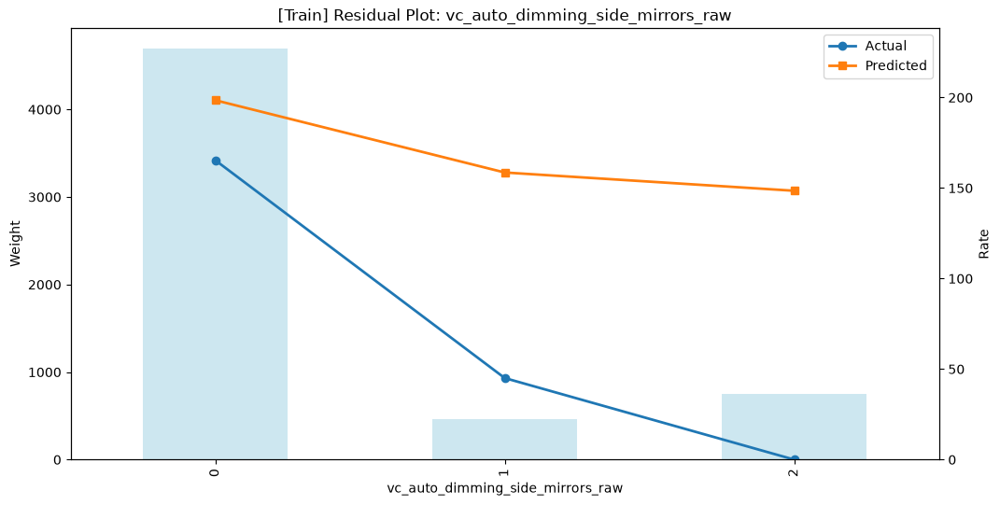

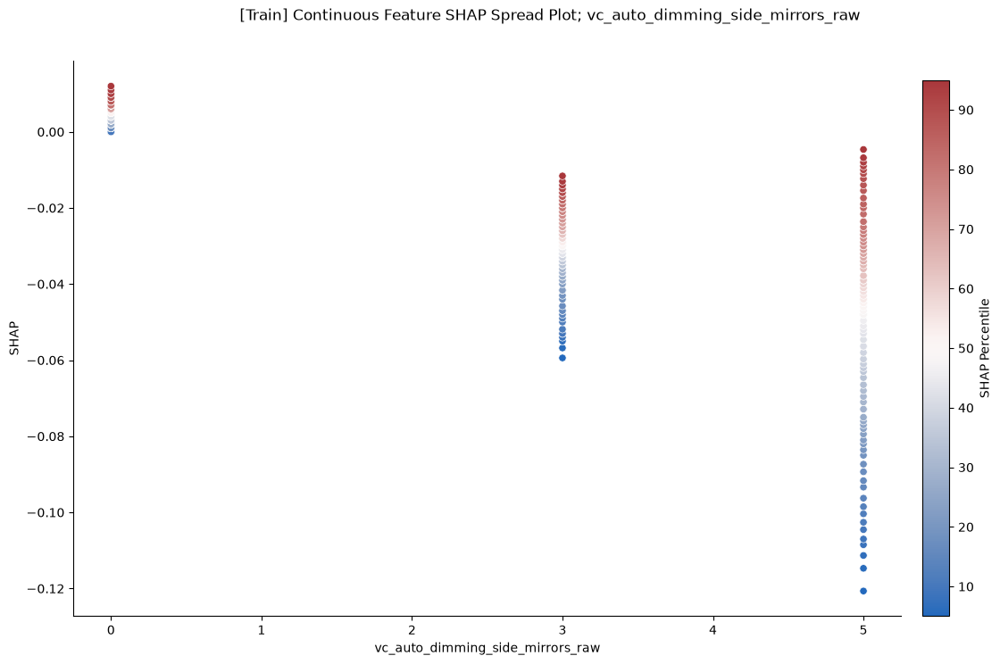

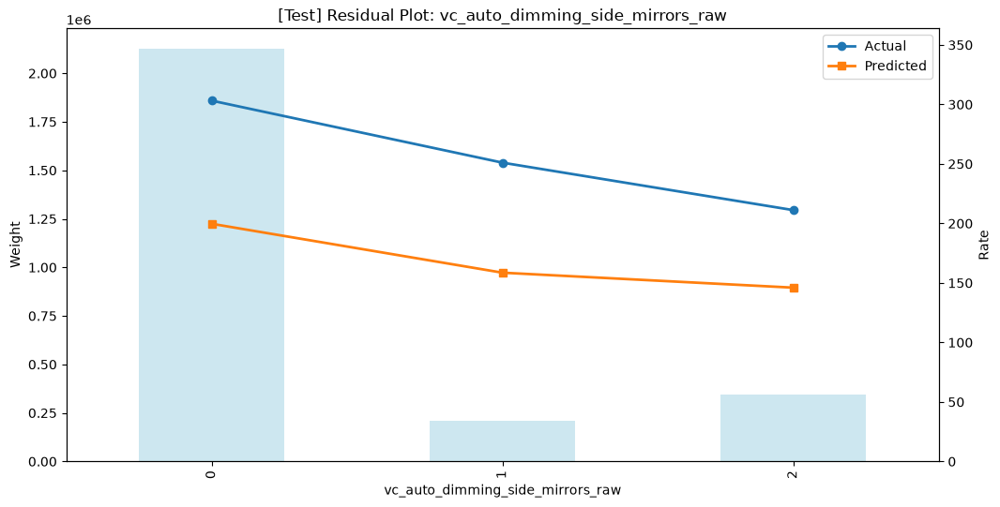

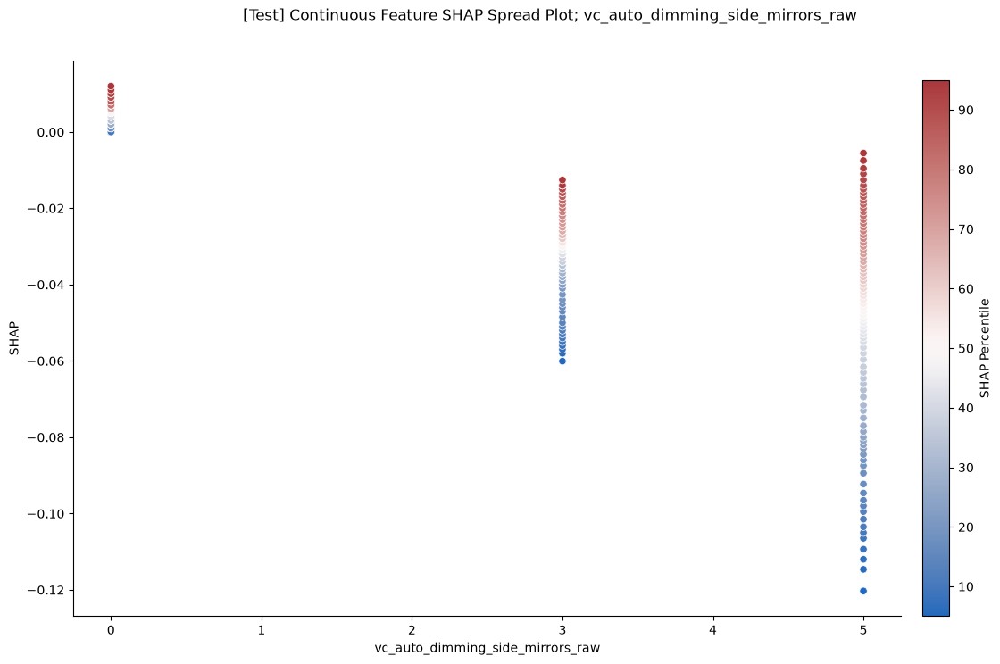


FEATURE: vc_transmission_type_automatic_ind


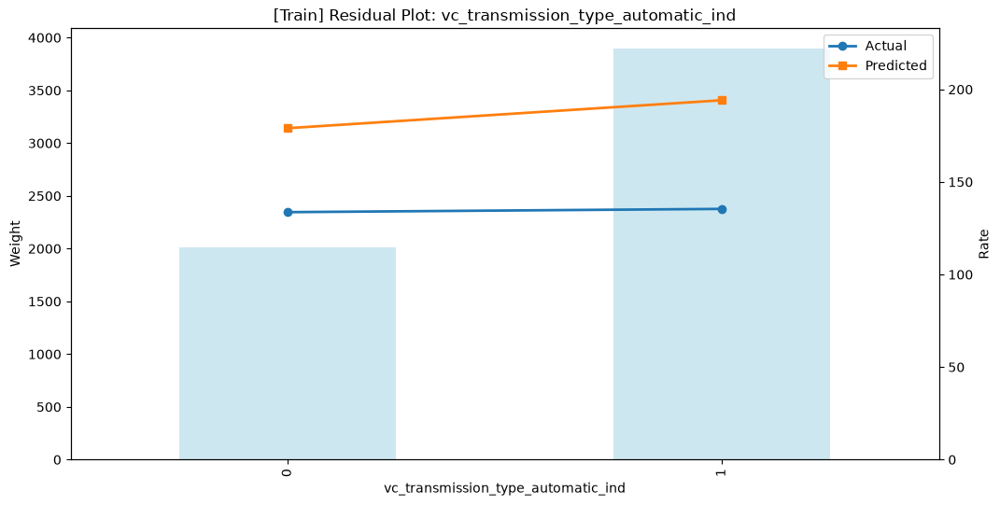

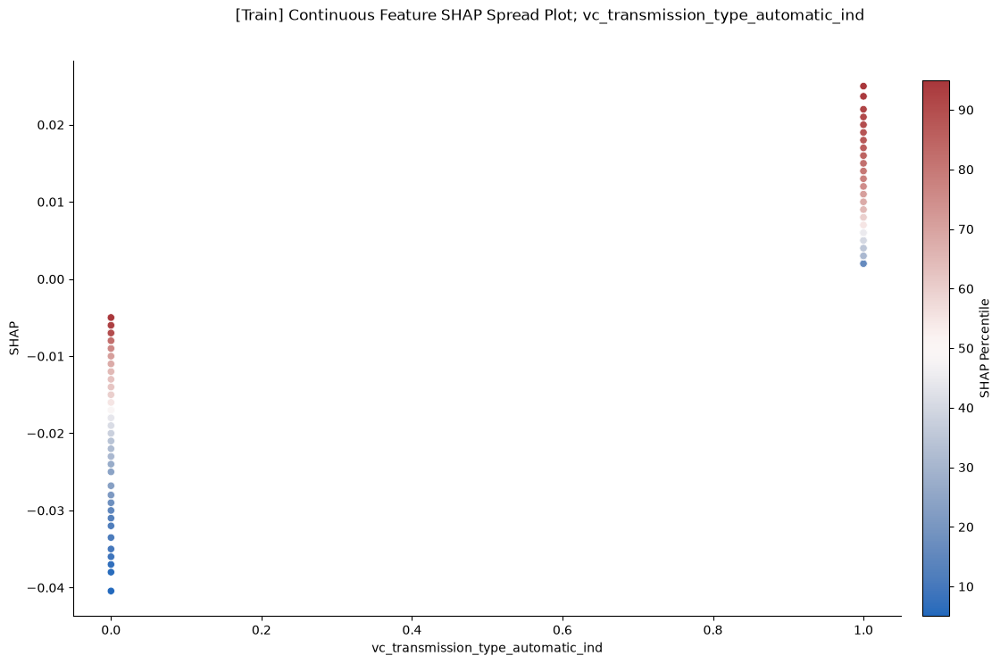

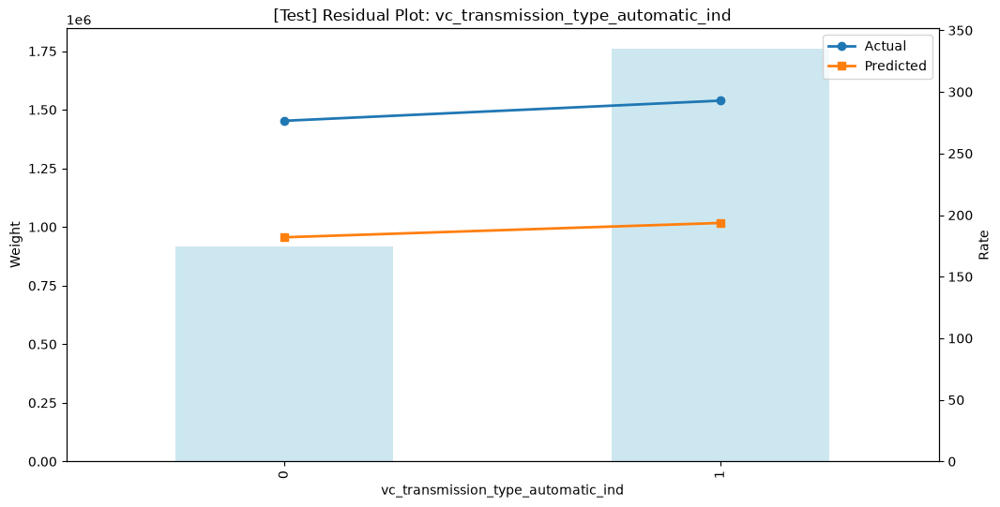

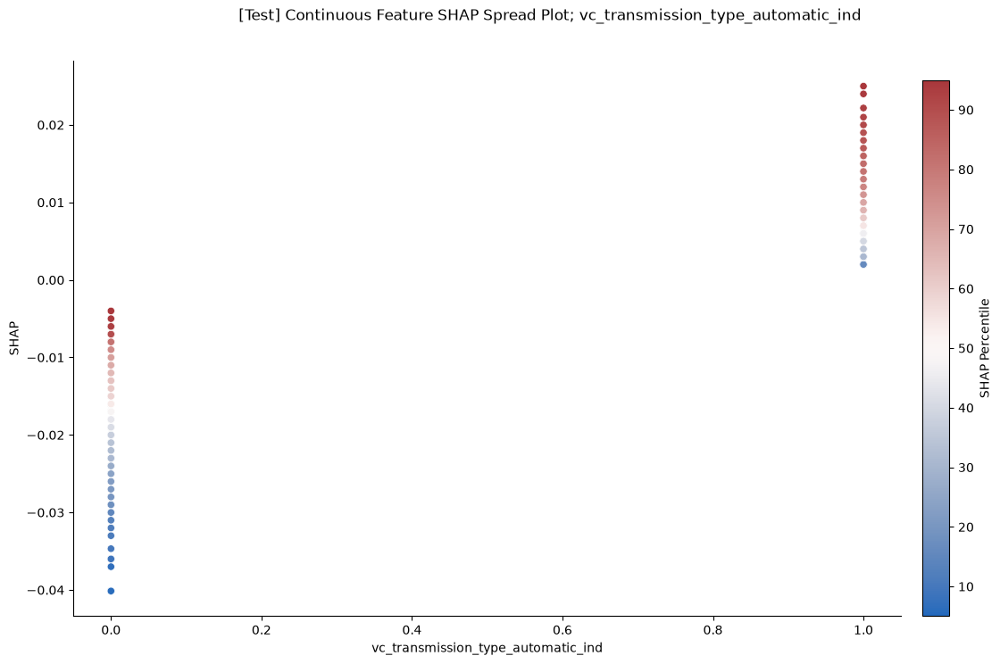


FEATURE: vc_backup_camera_raw_0


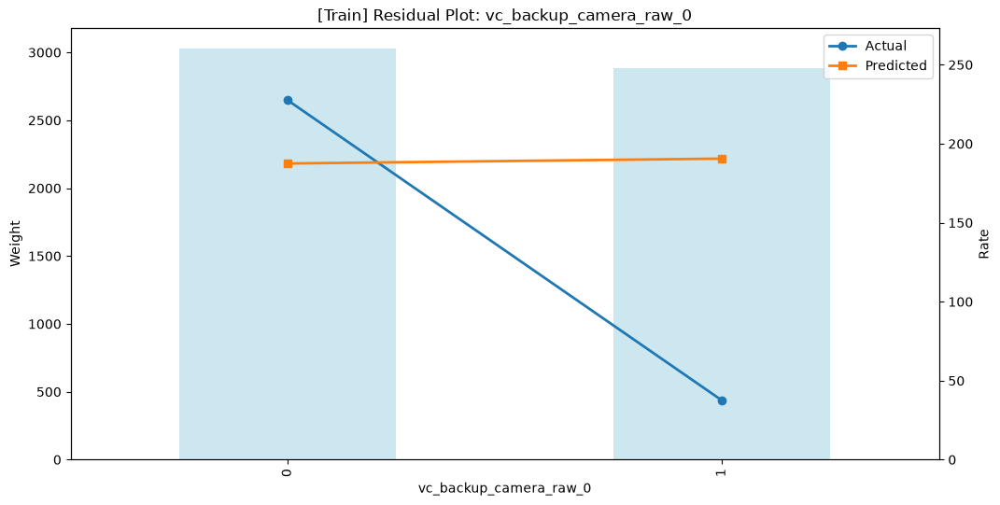

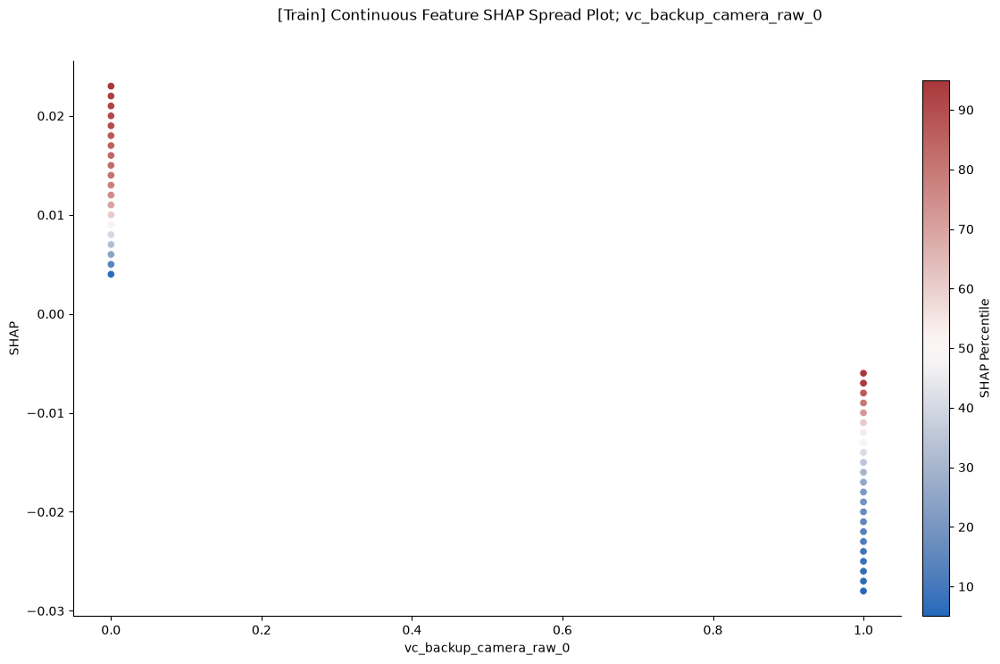

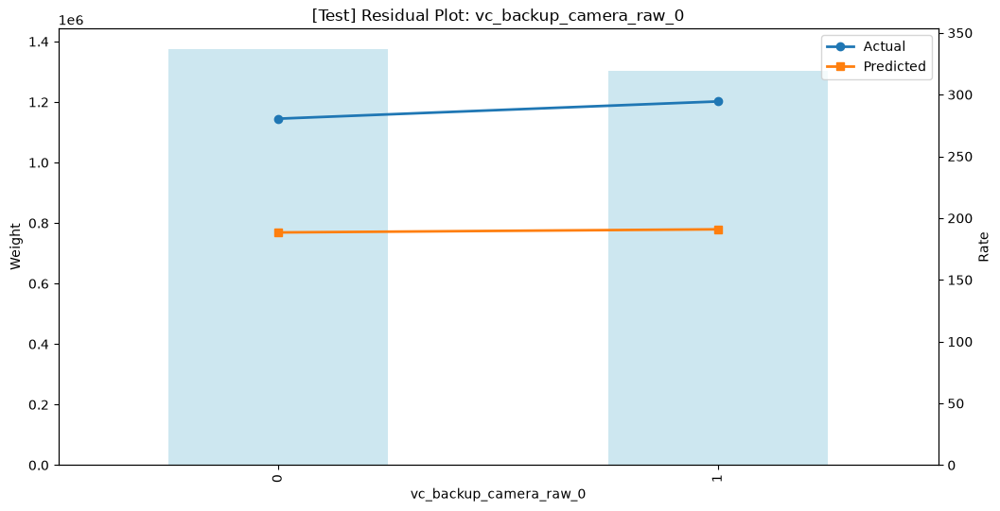

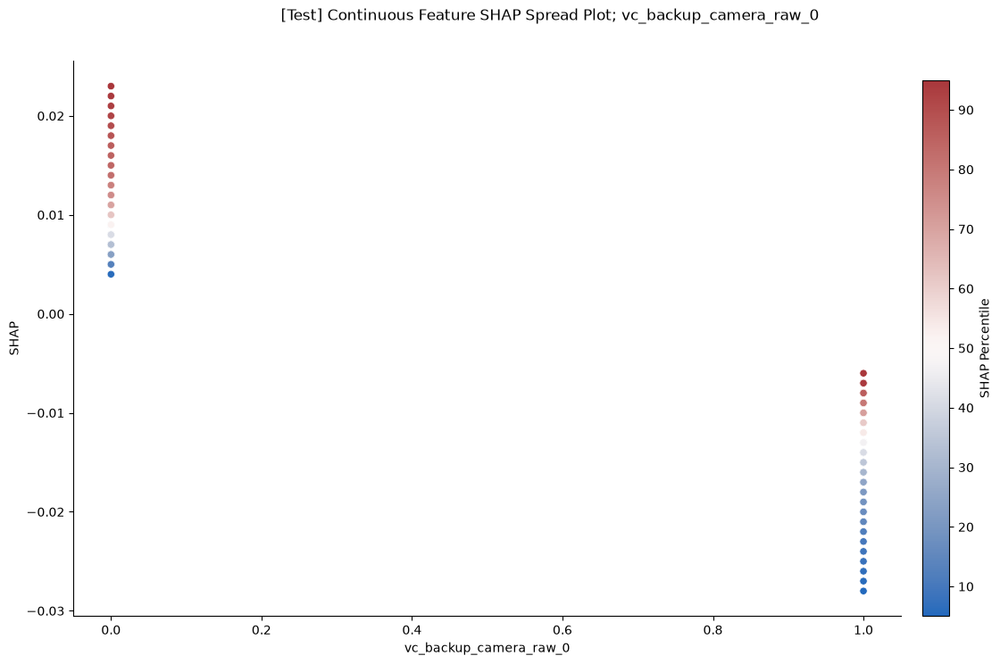


FEATURE: vc_premium_audio_raw


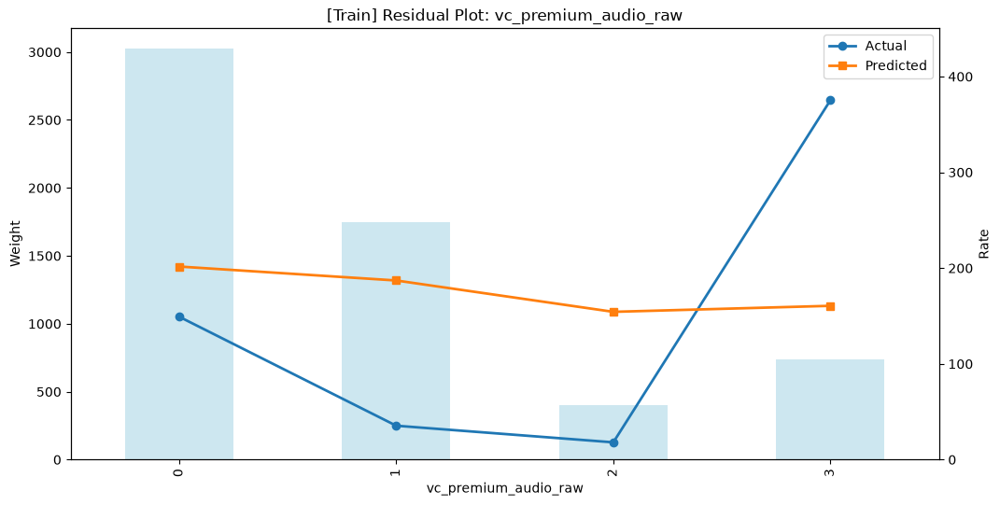

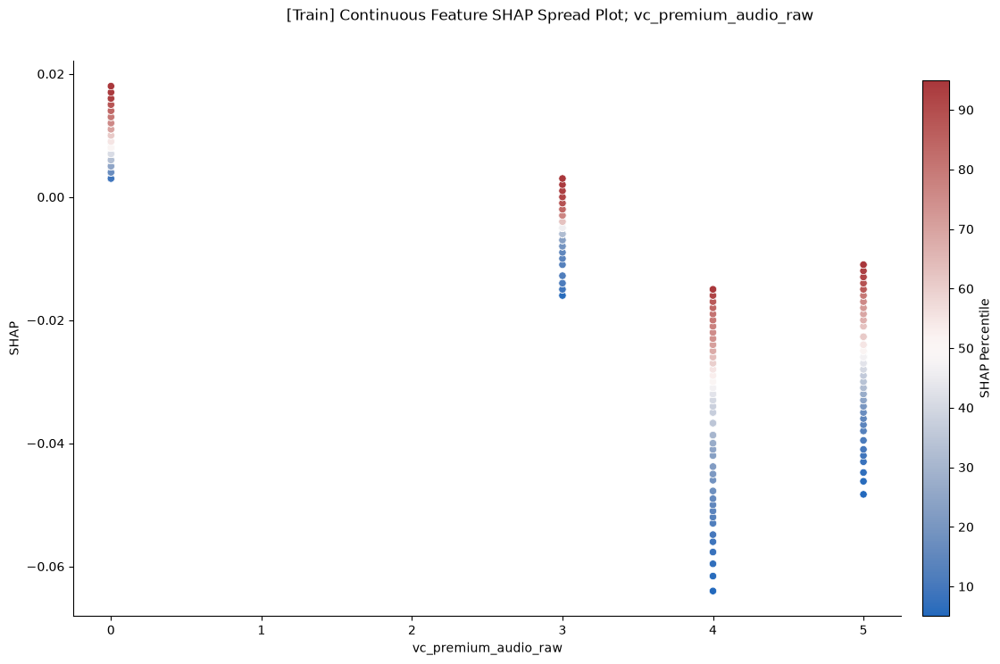

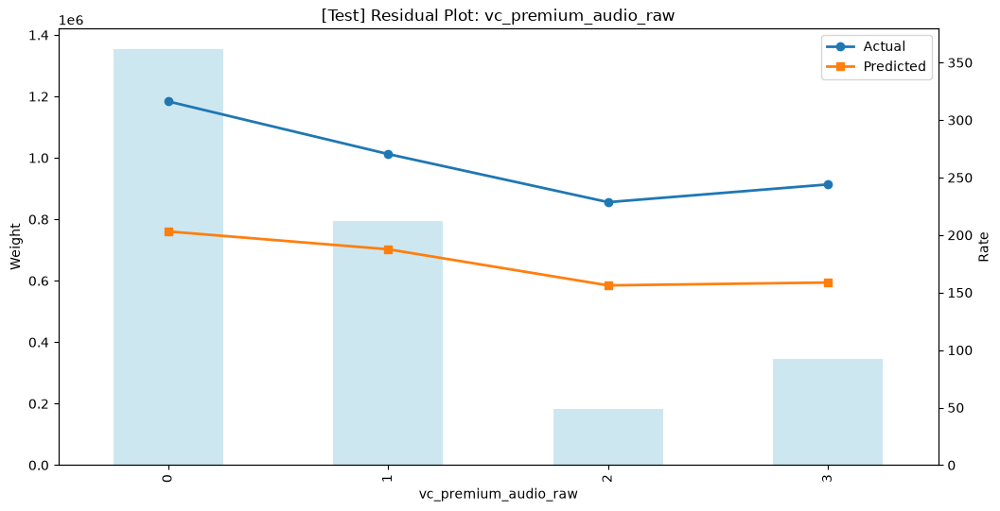

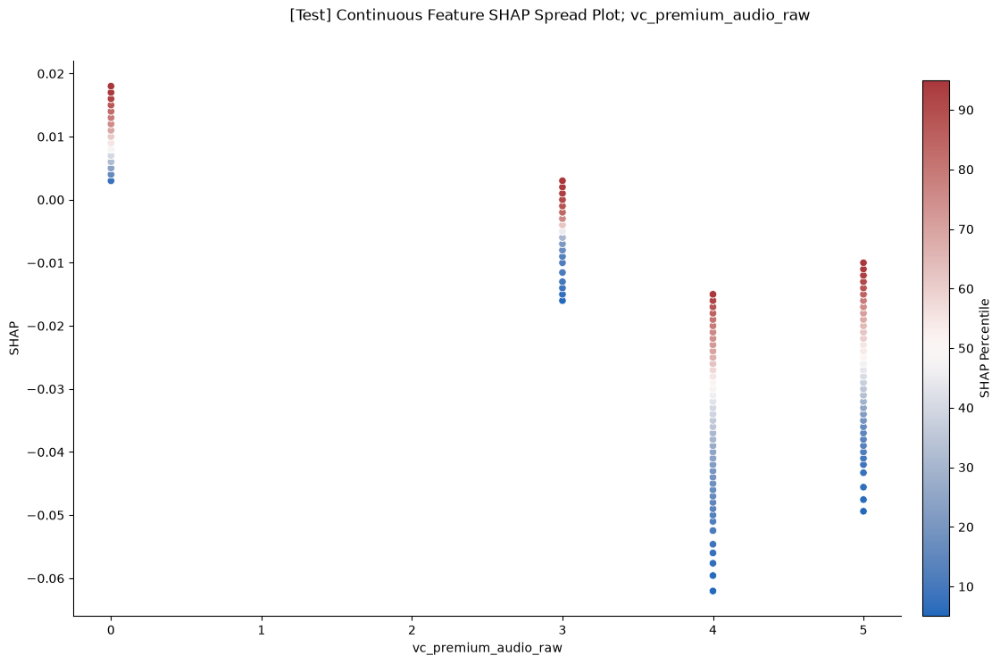


FEATURE: vc_variable_power_steering_raw


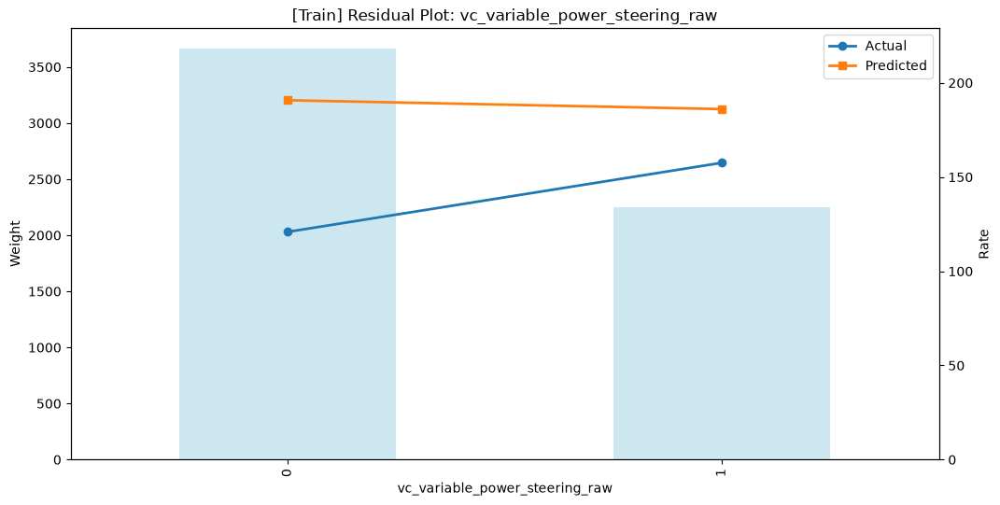

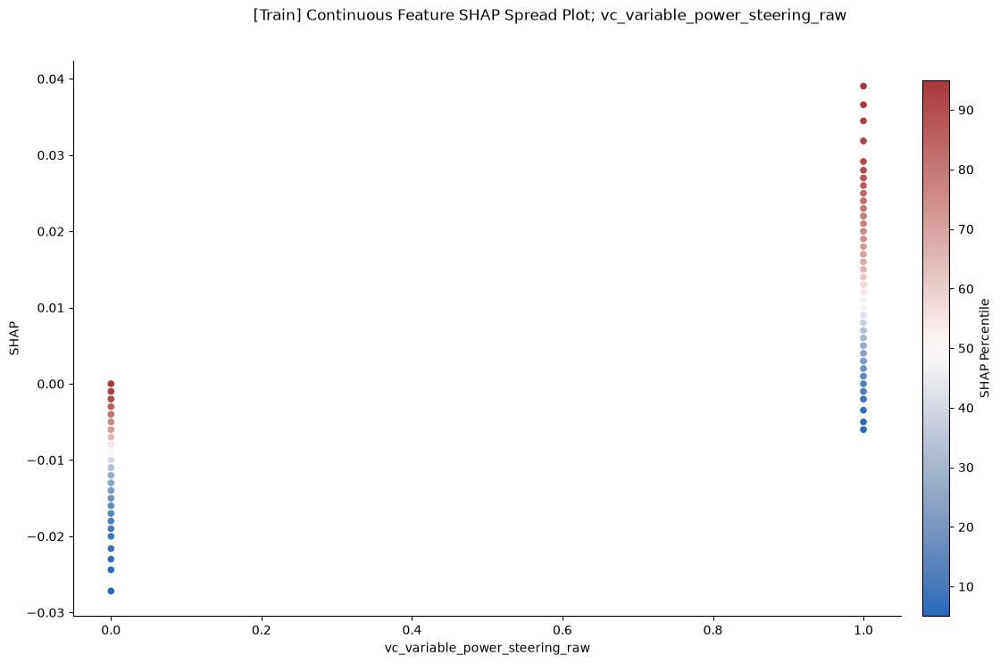

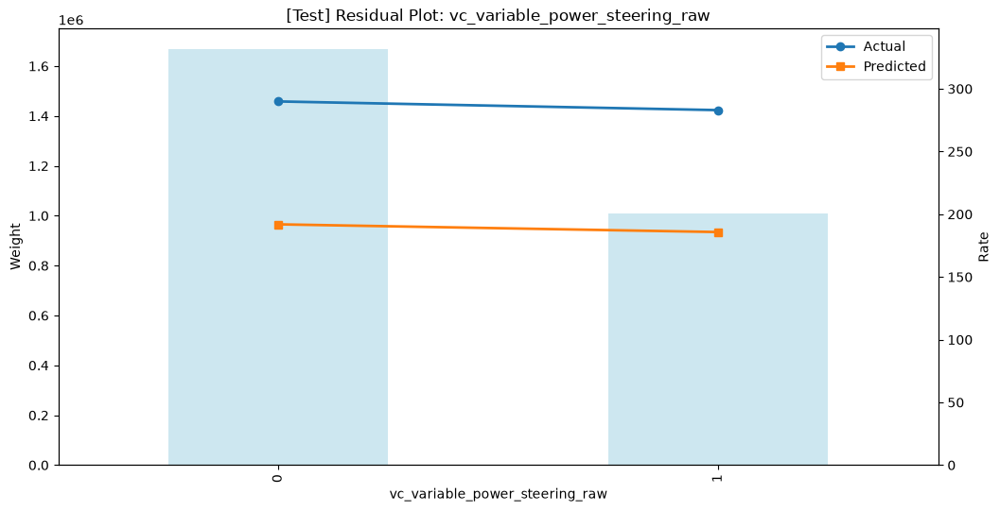

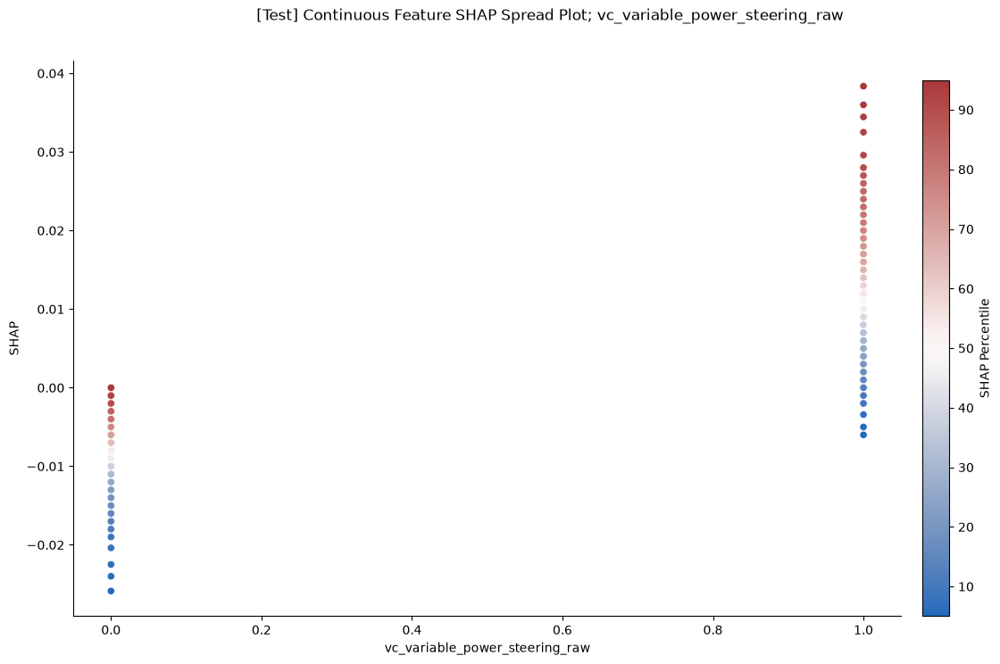


FEATURE: vc_drive_type_awd_ind


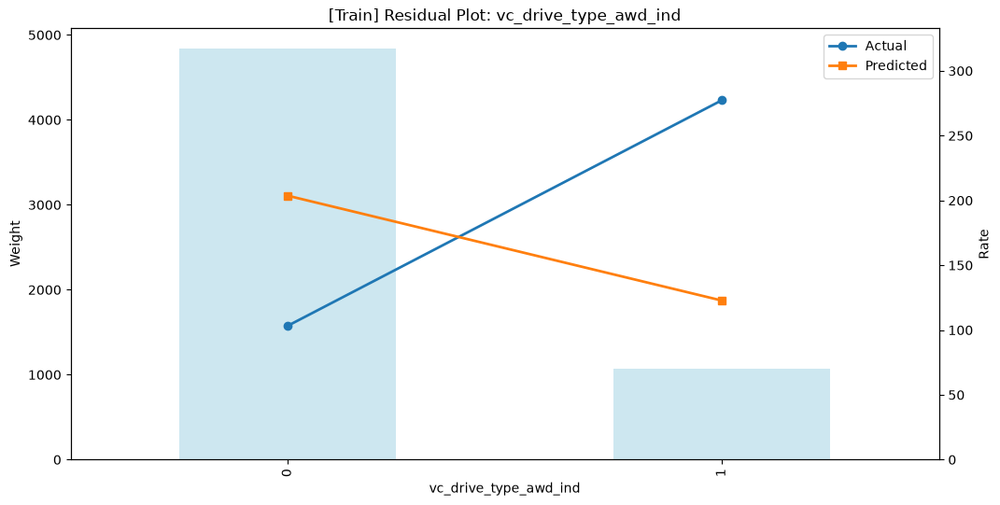

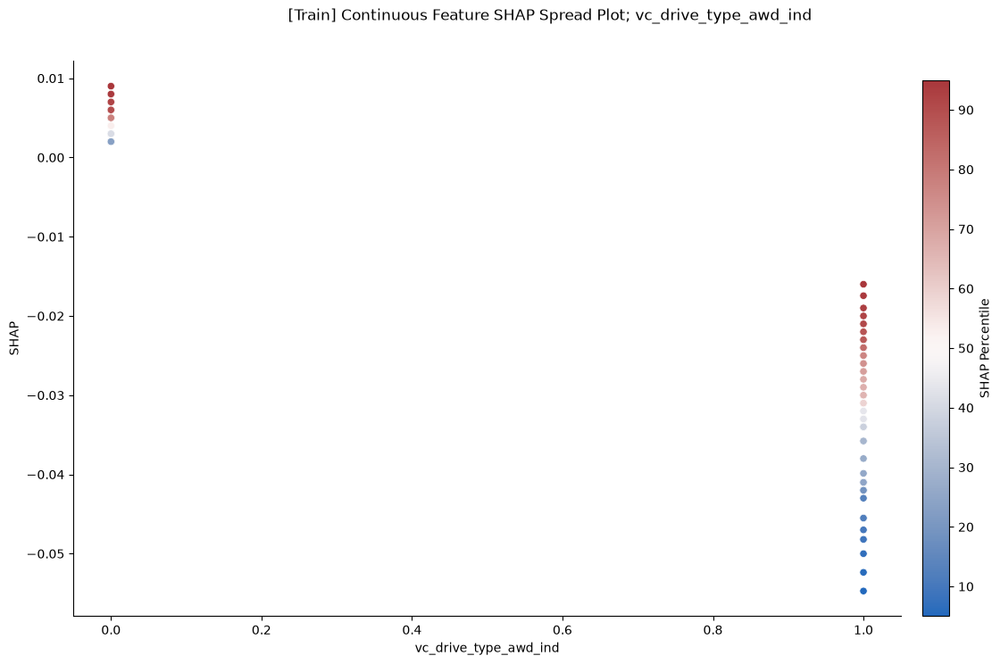

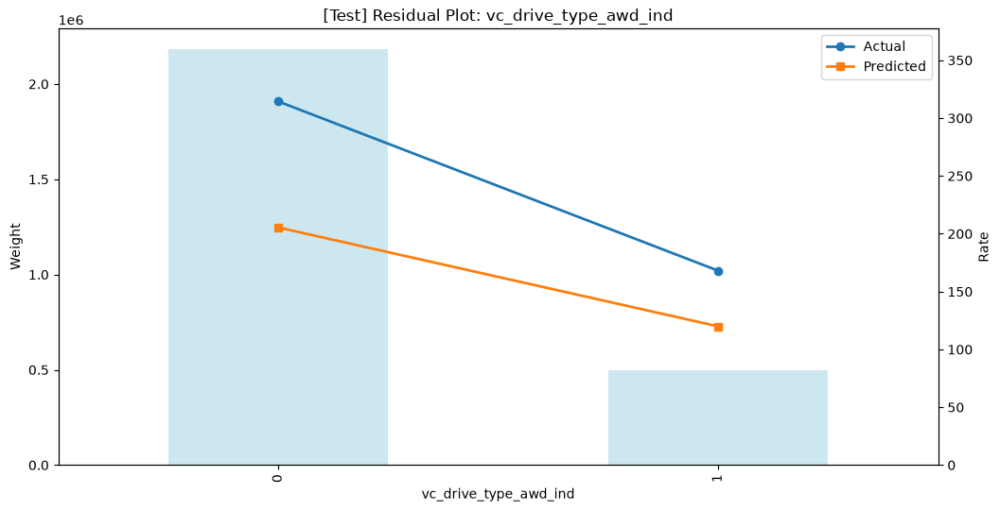

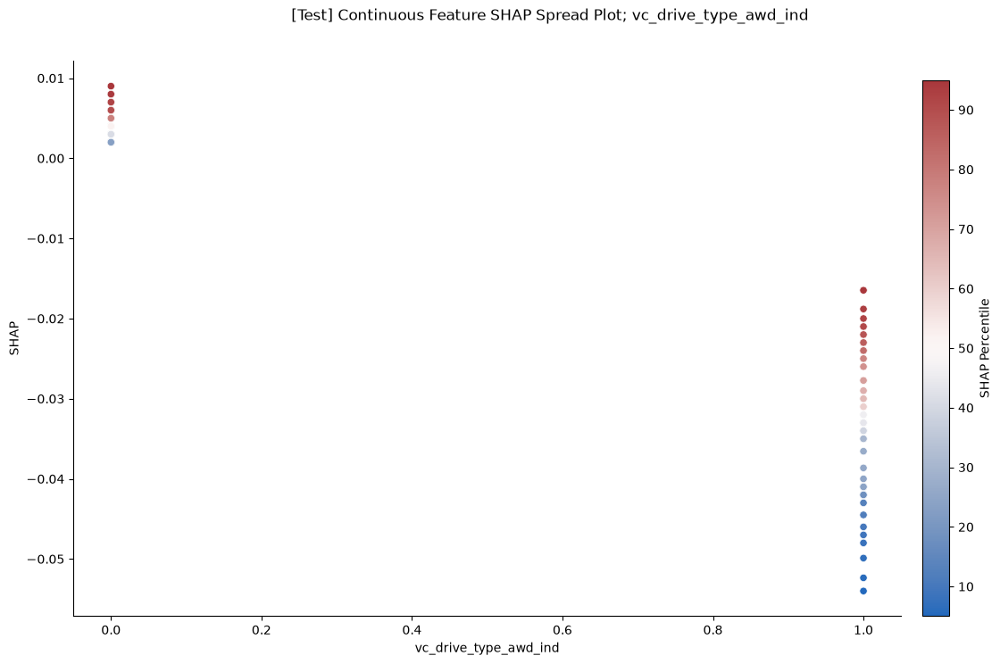


FEATURE: vc_adaptive_cruise_control_raw_0


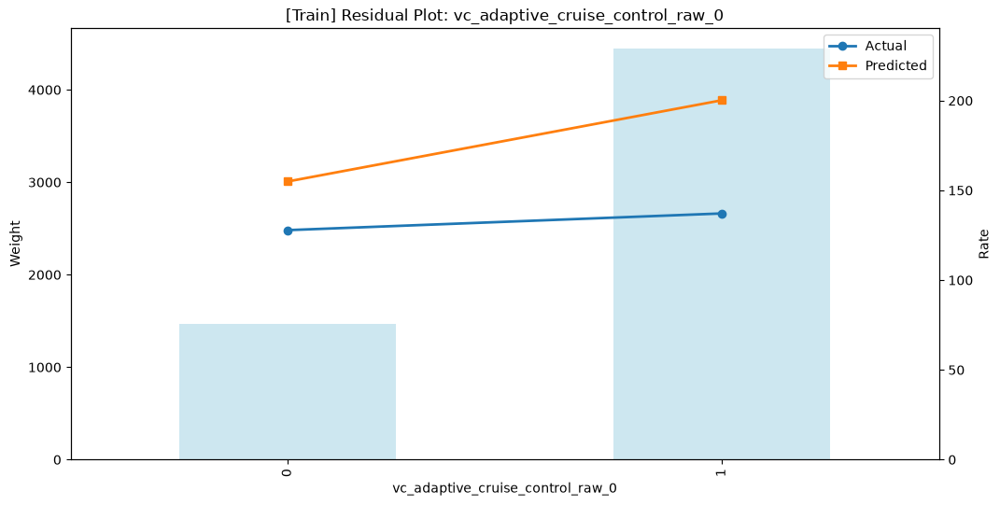

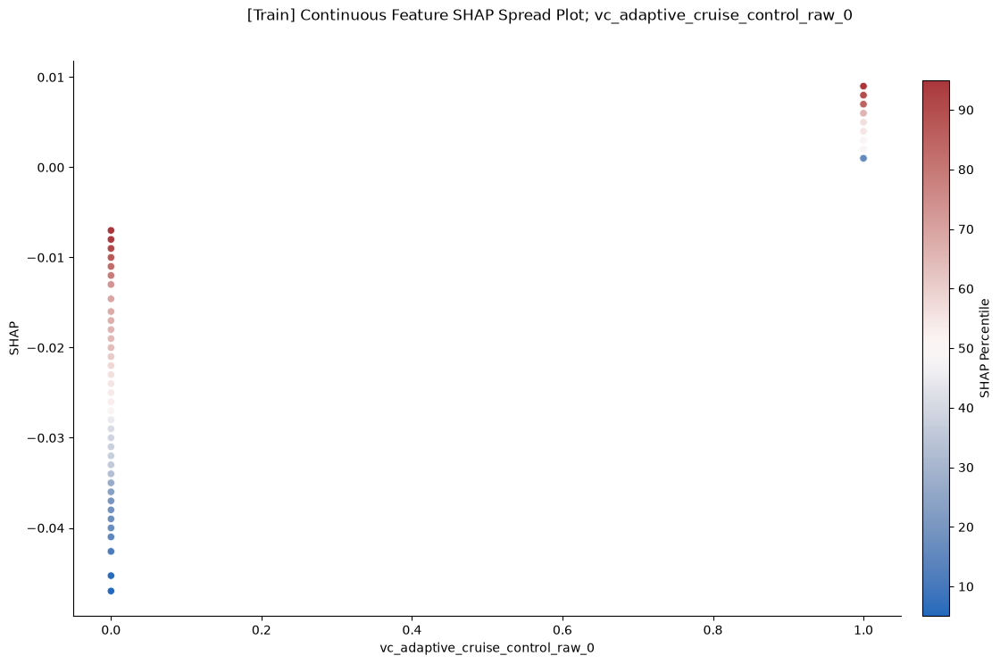

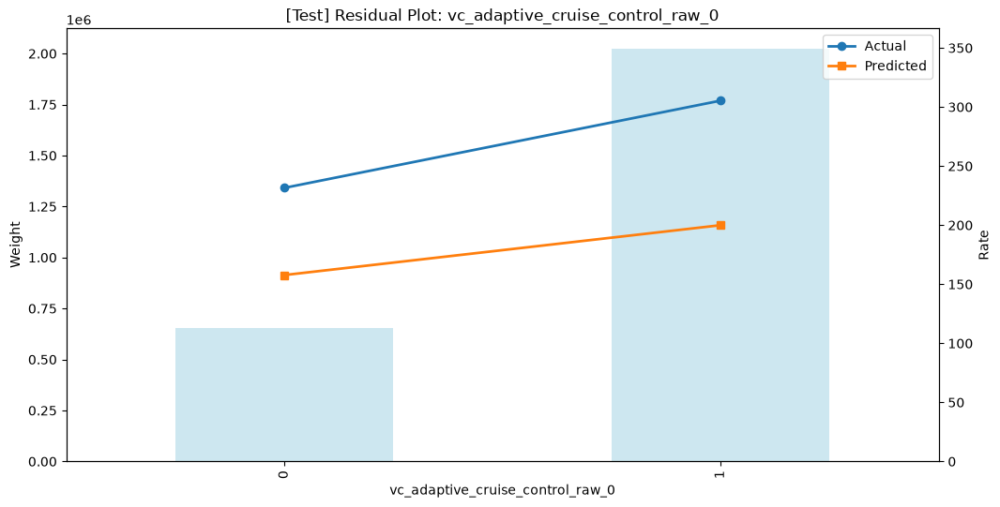

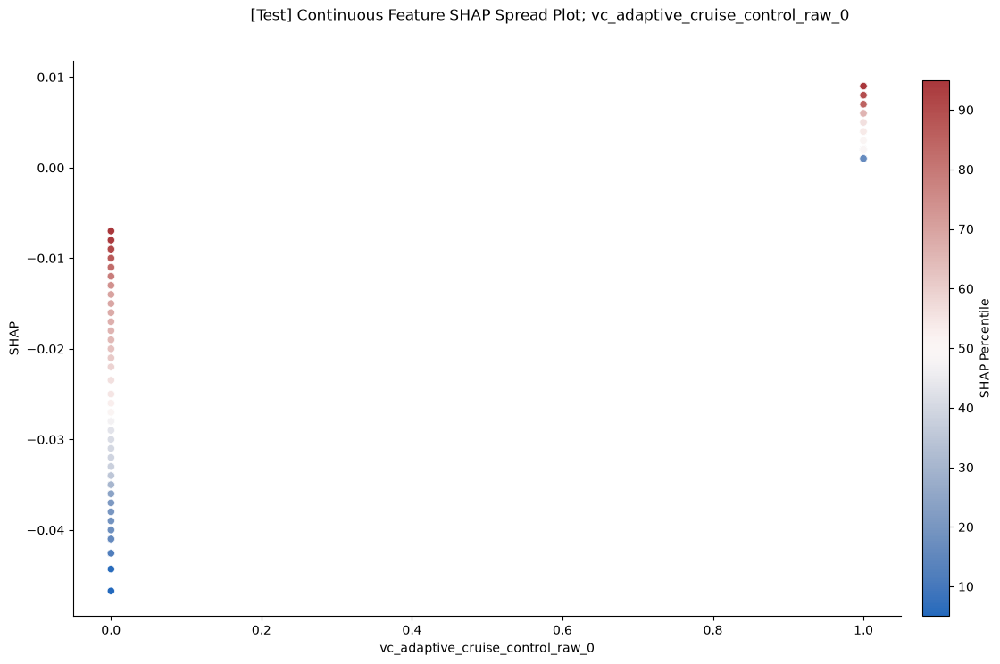


FEATURE: vc_satellite_radio_raw


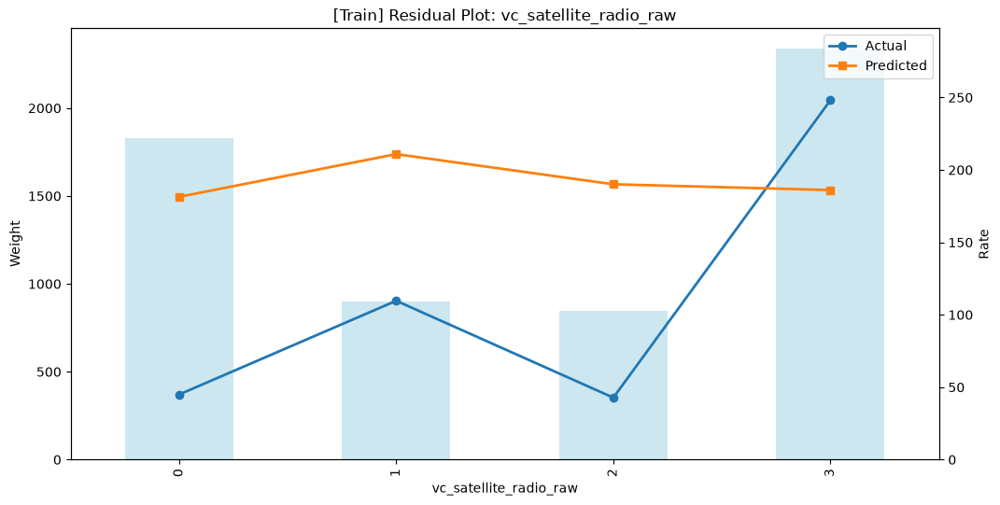

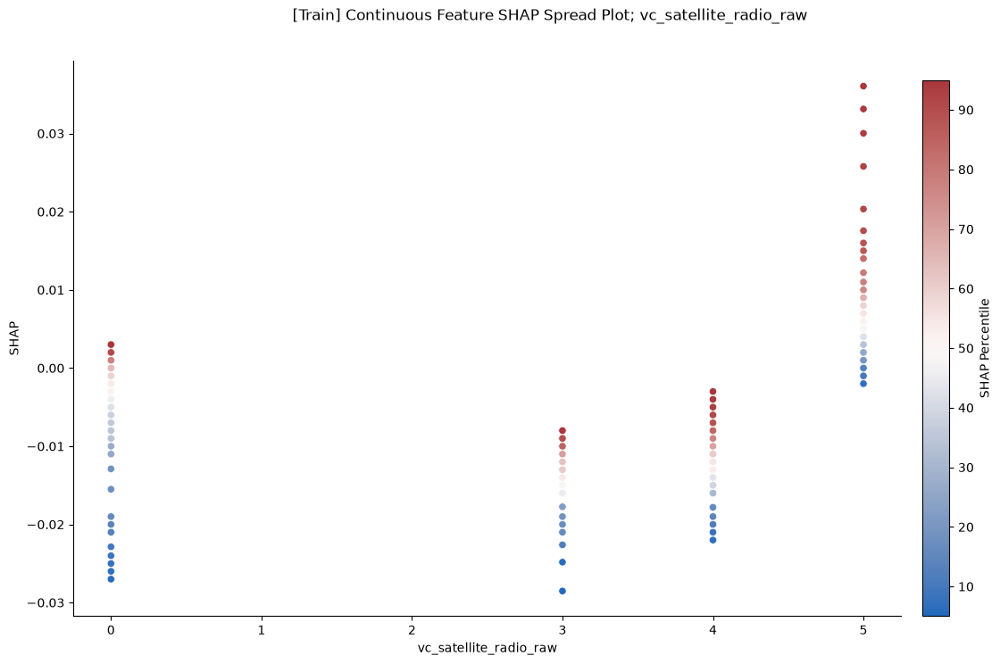

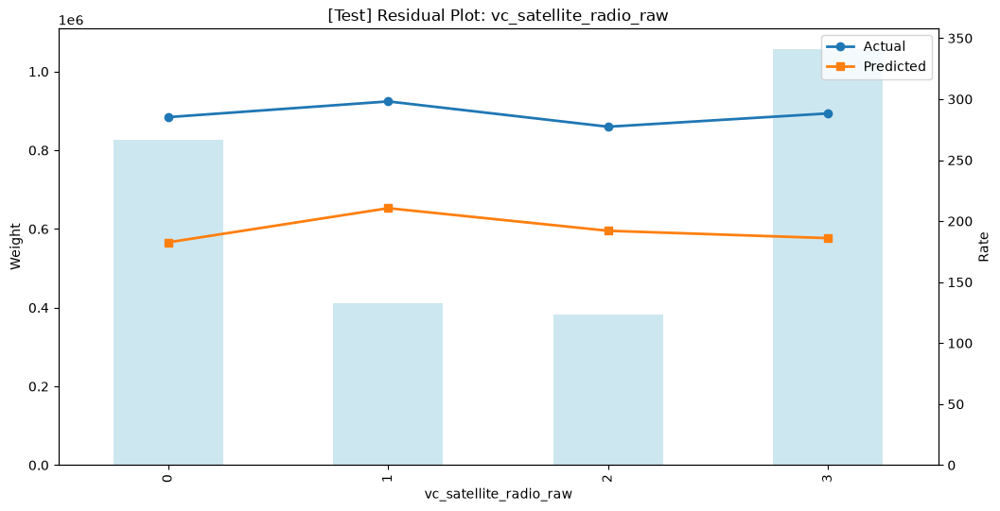

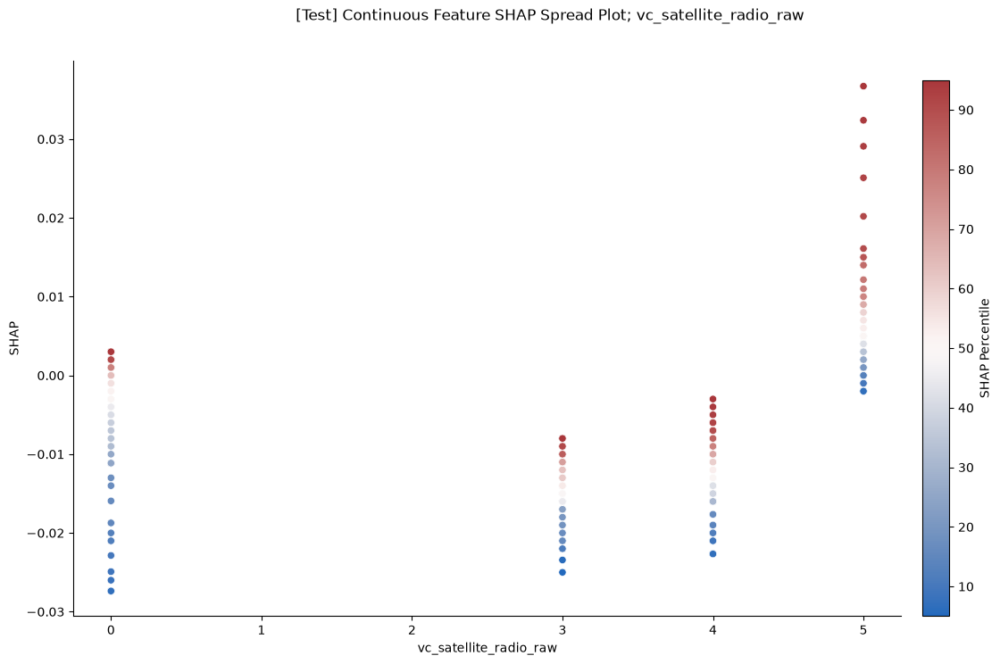


FEATURE: vc_sunroof_raw_0


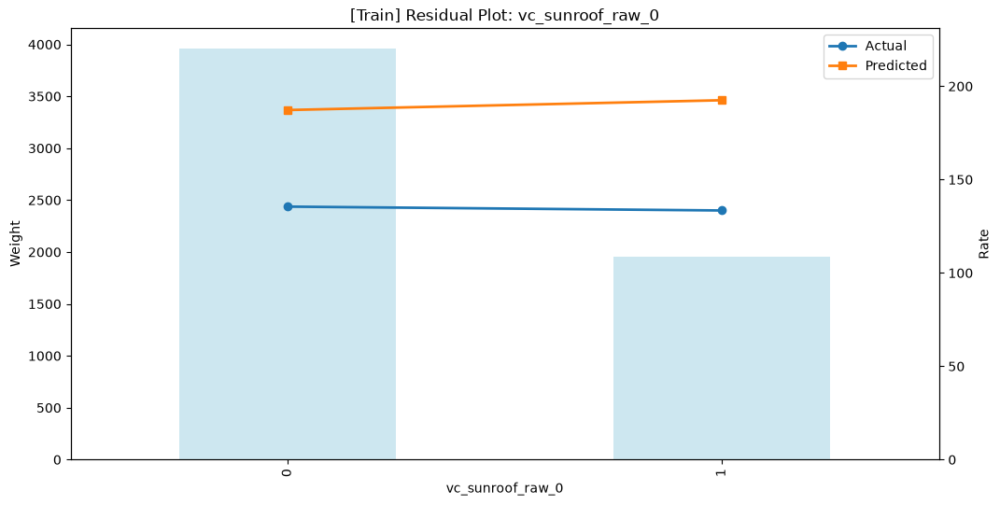

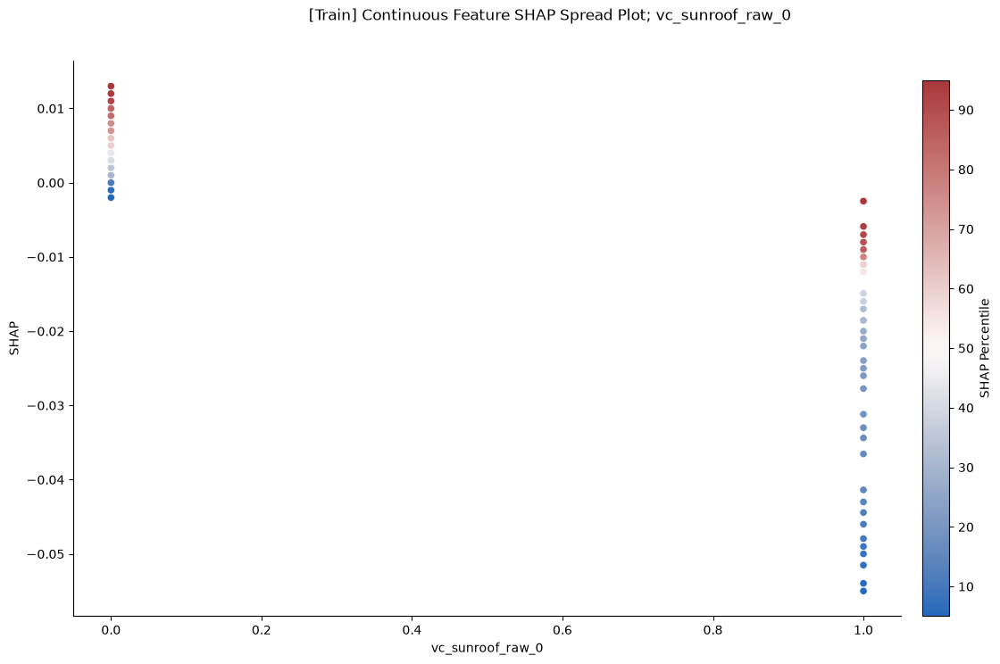

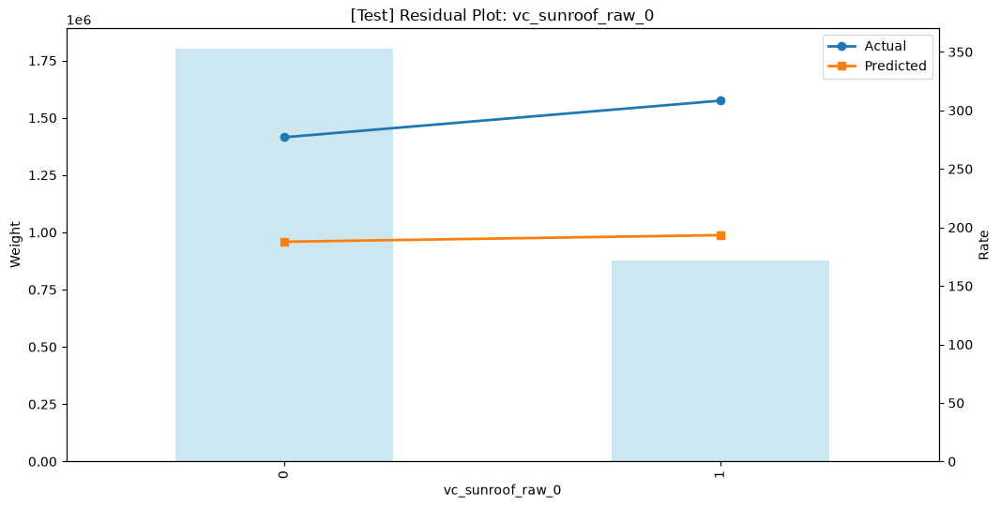

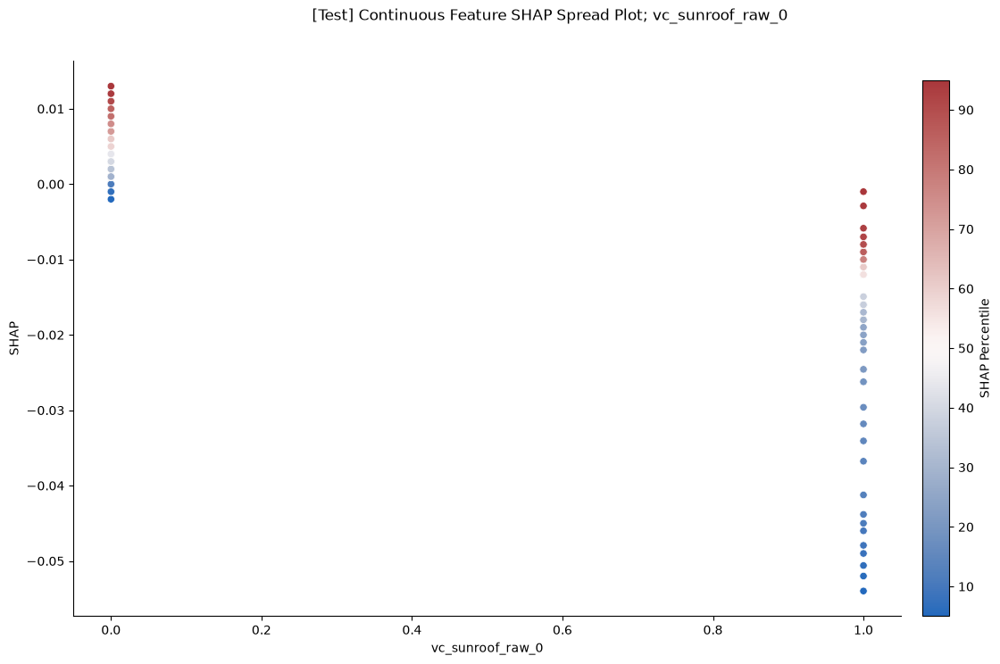


FEATURE: vc_surround_sound_raw_3


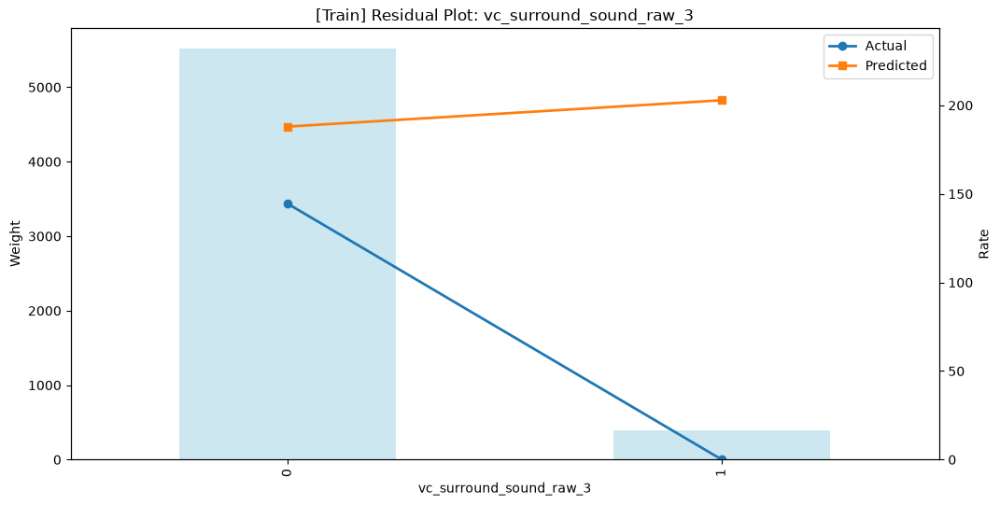

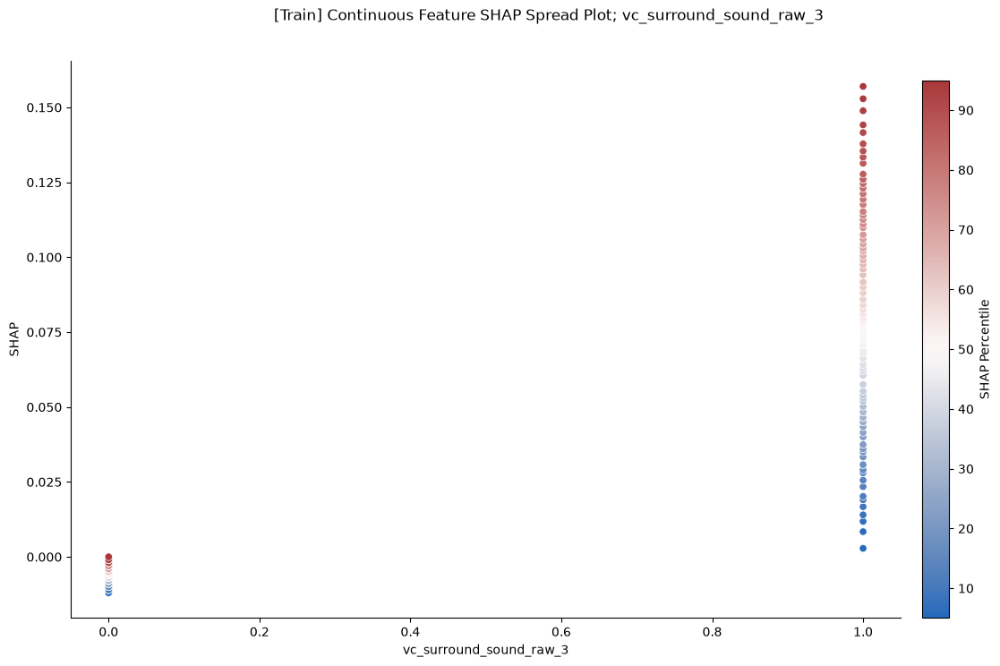

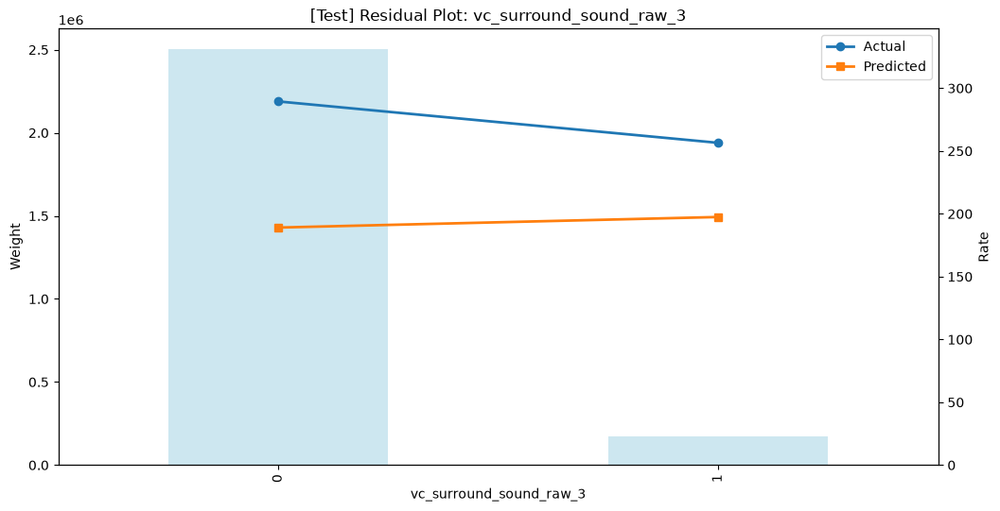

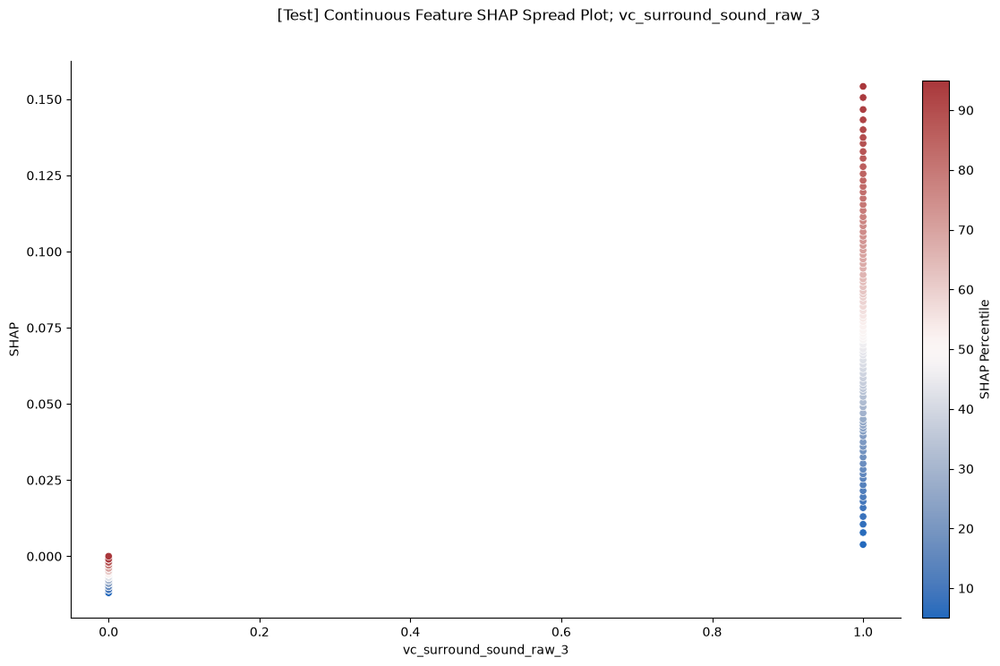


FEATURE: vc_adaptive_cruise_control_raw_5


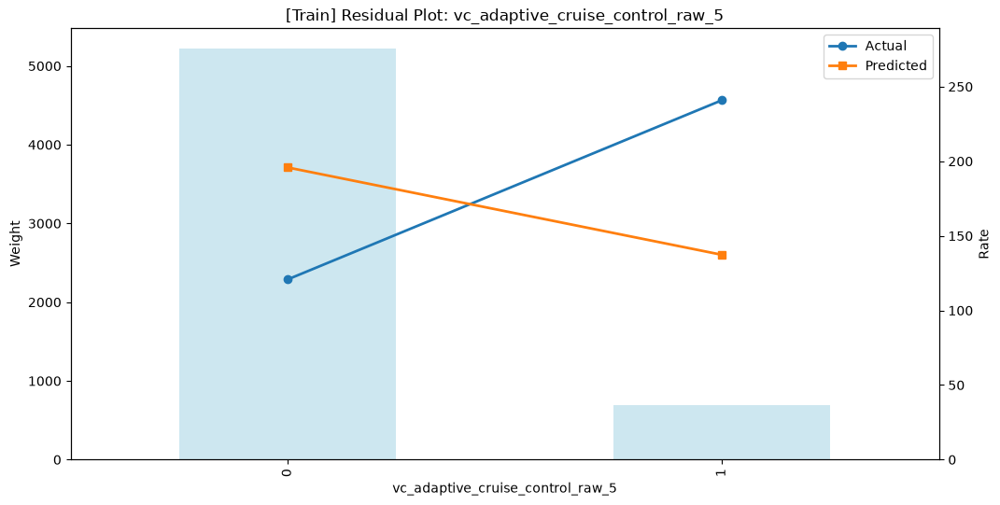

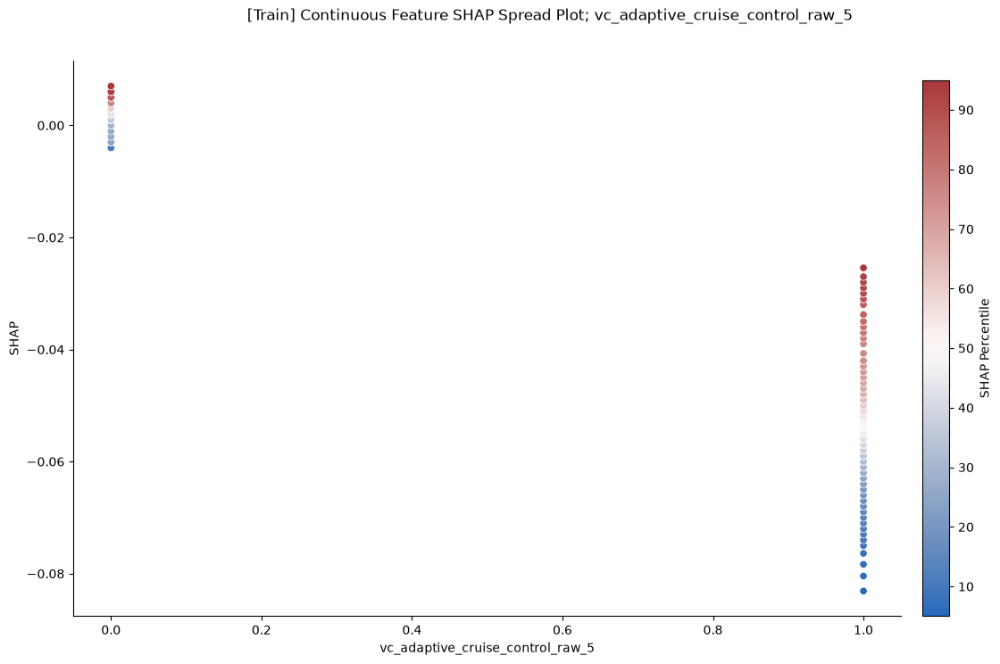

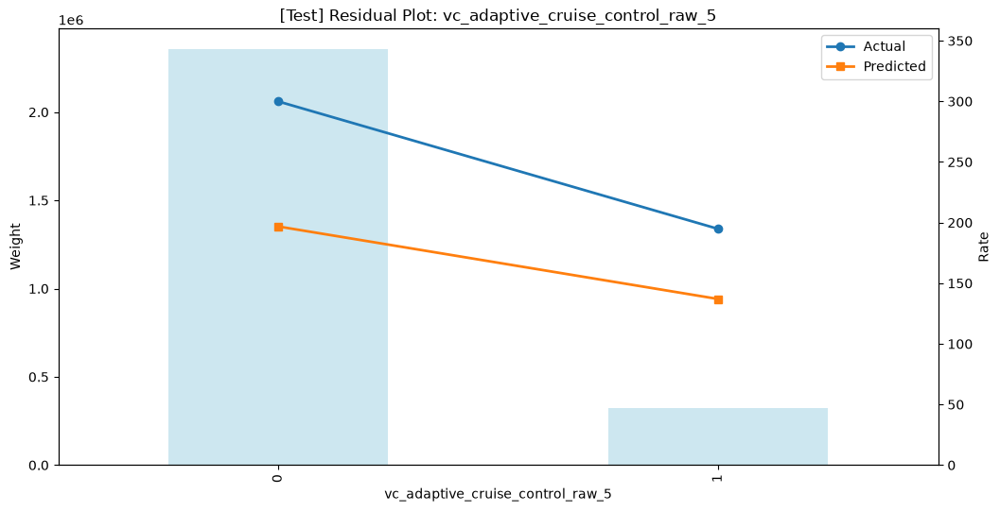

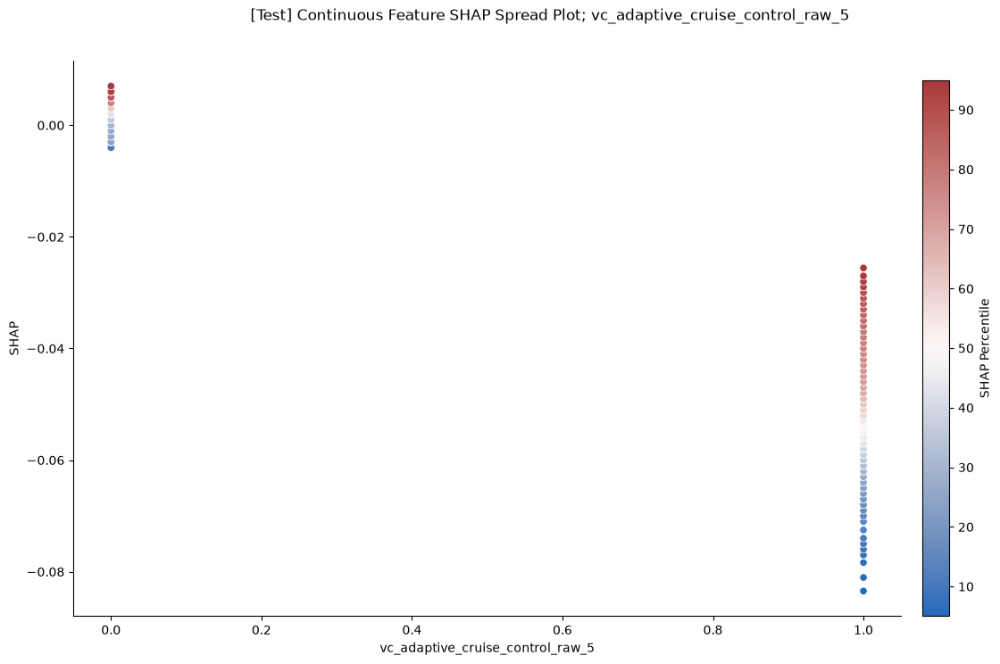


FEATURE: vc_auto_start_stop_raw_5


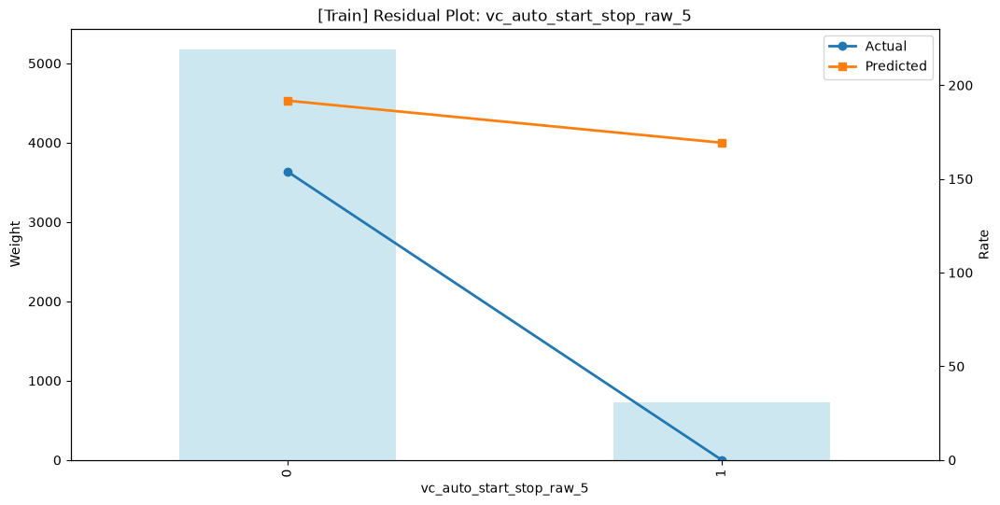

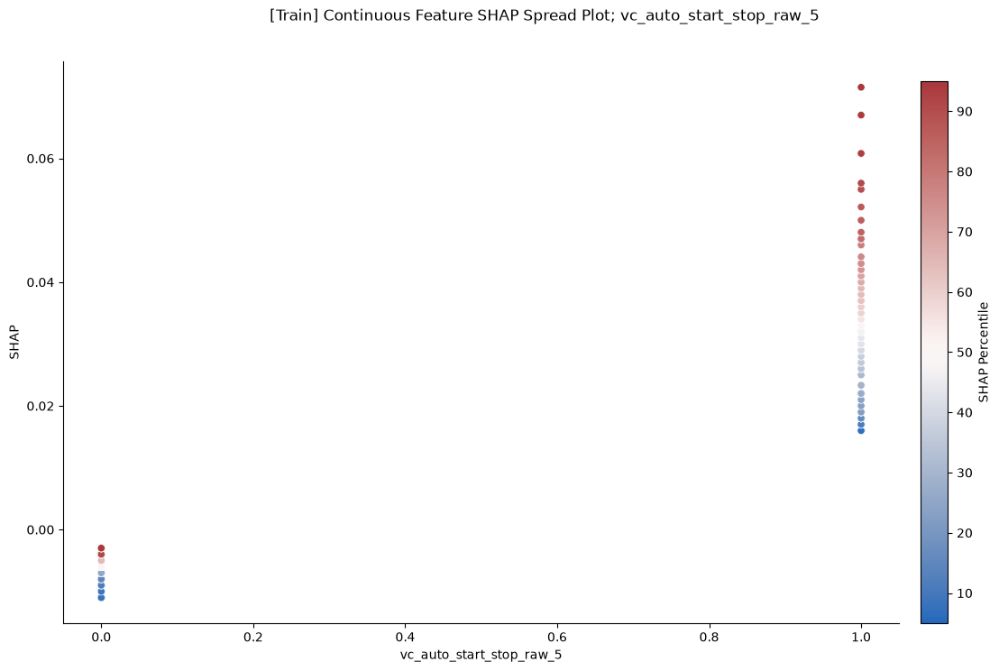

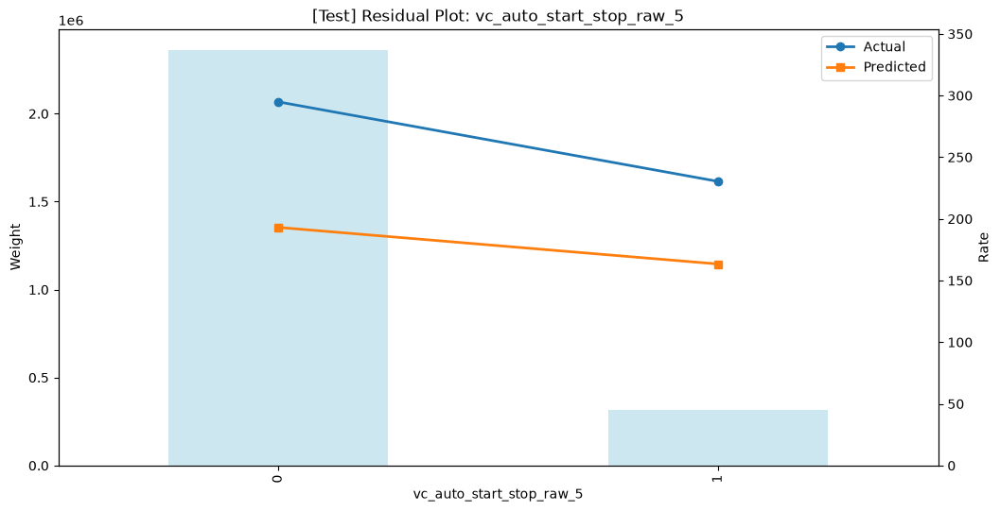

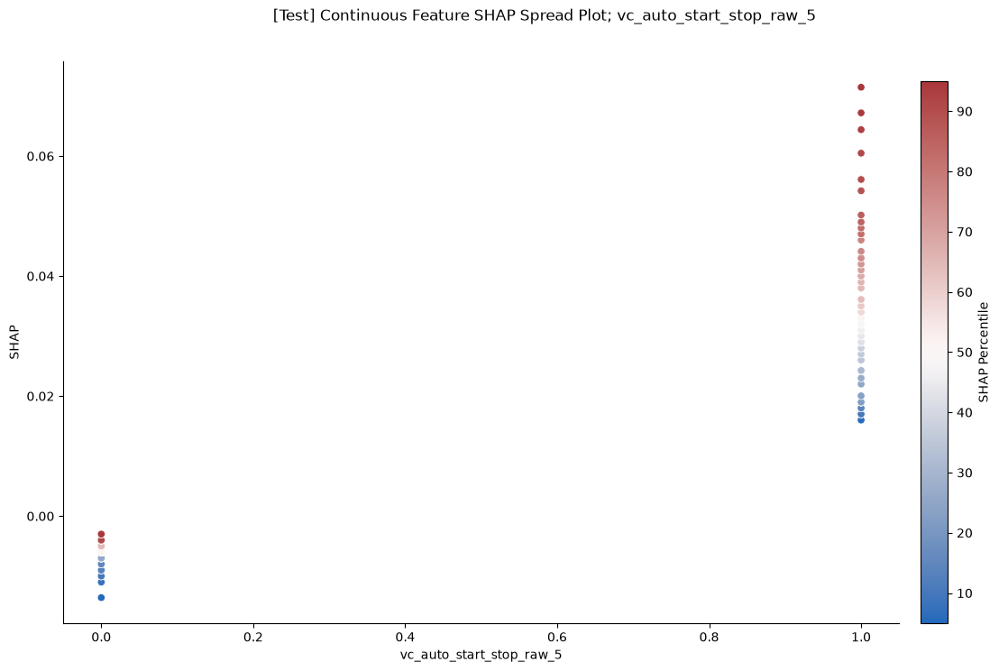


FEATURE: vc_surround_sound_raw_1


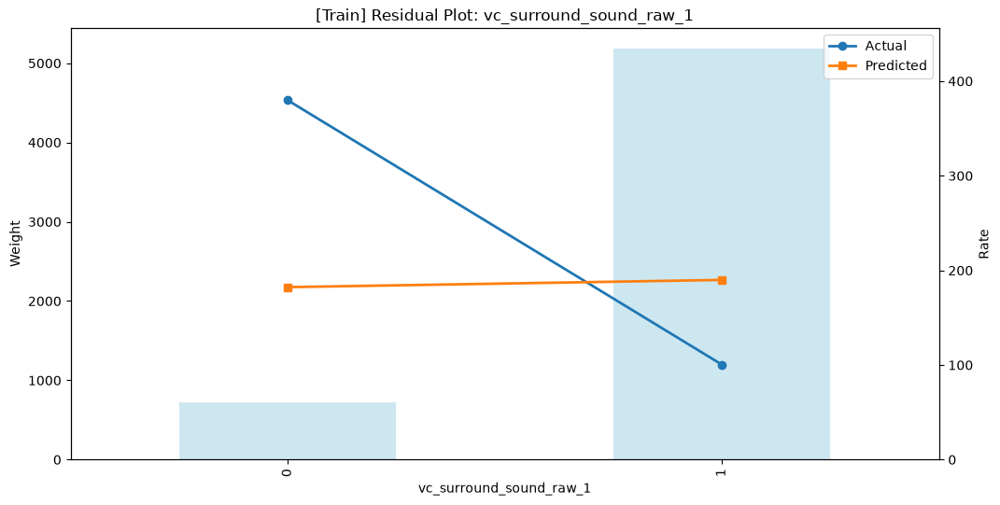

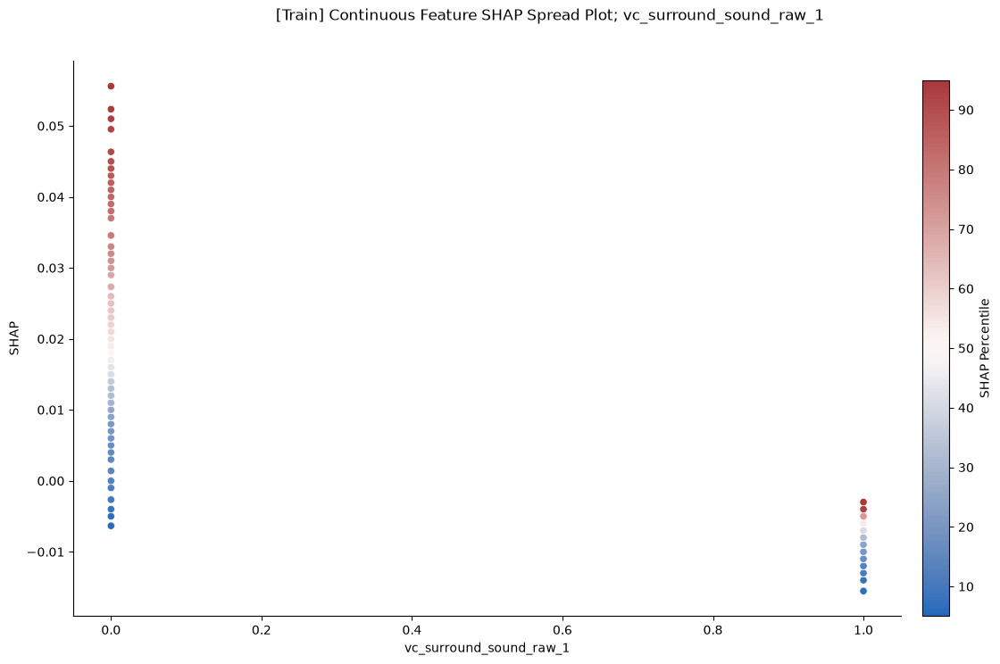

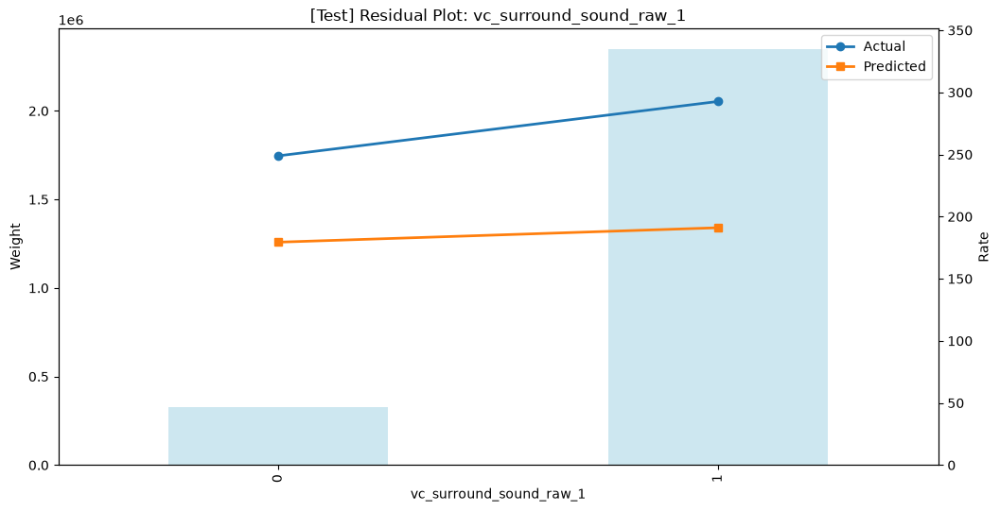

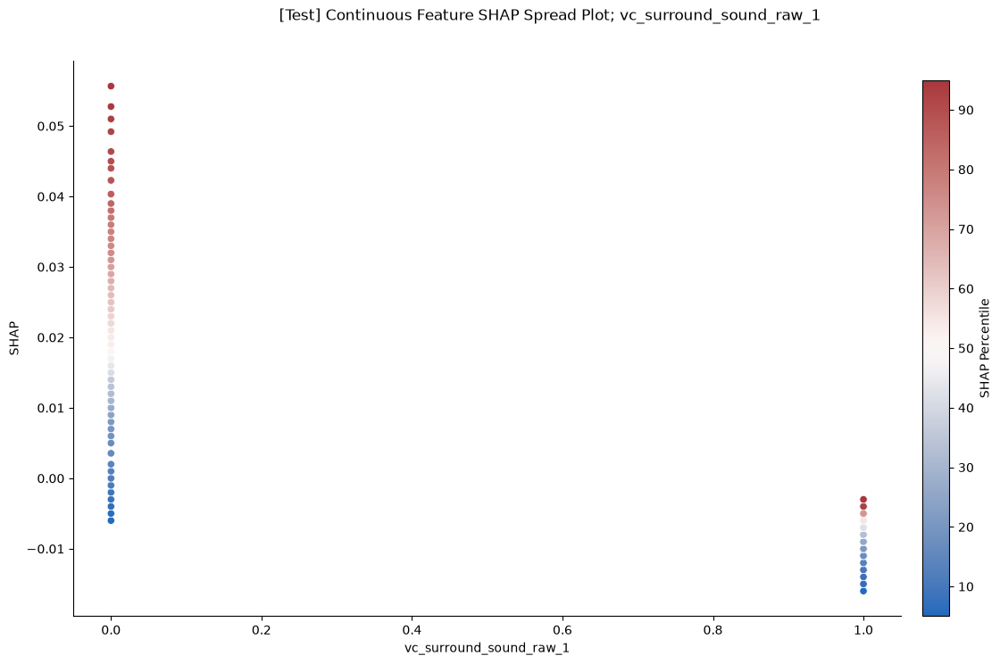


FEATURE: vc_hill_ascent_assist_raw_5


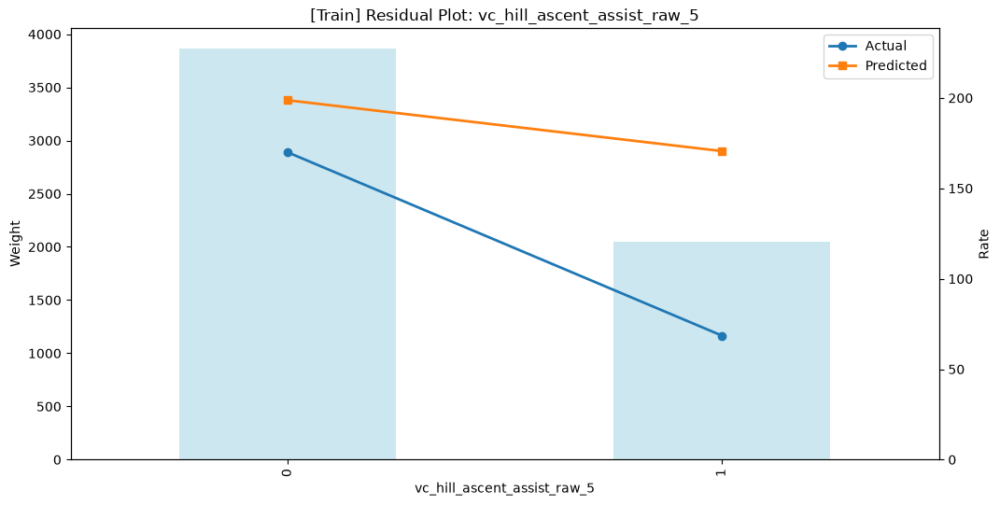

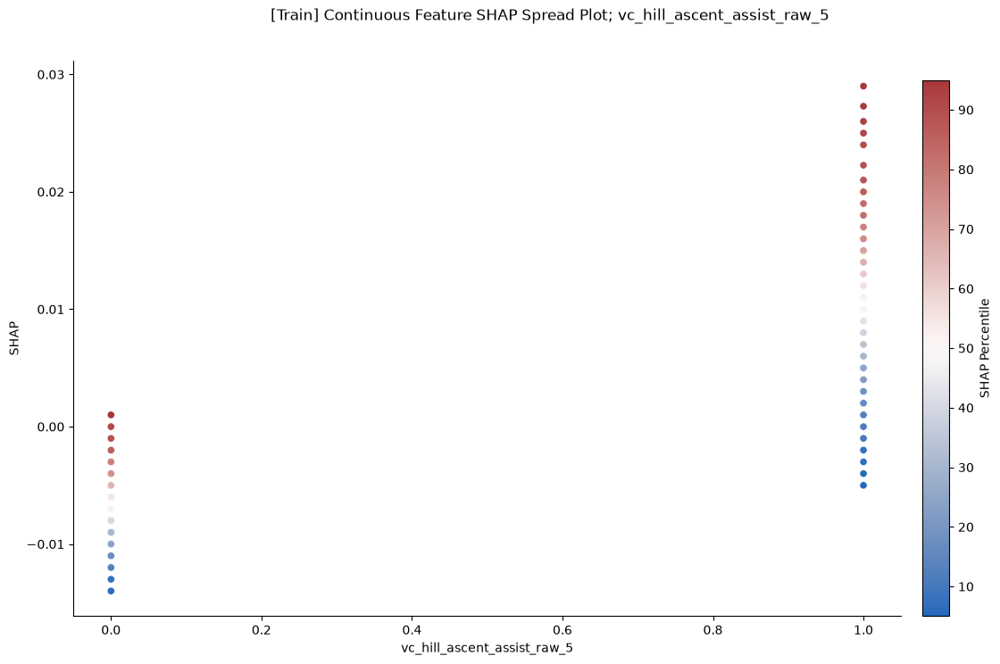

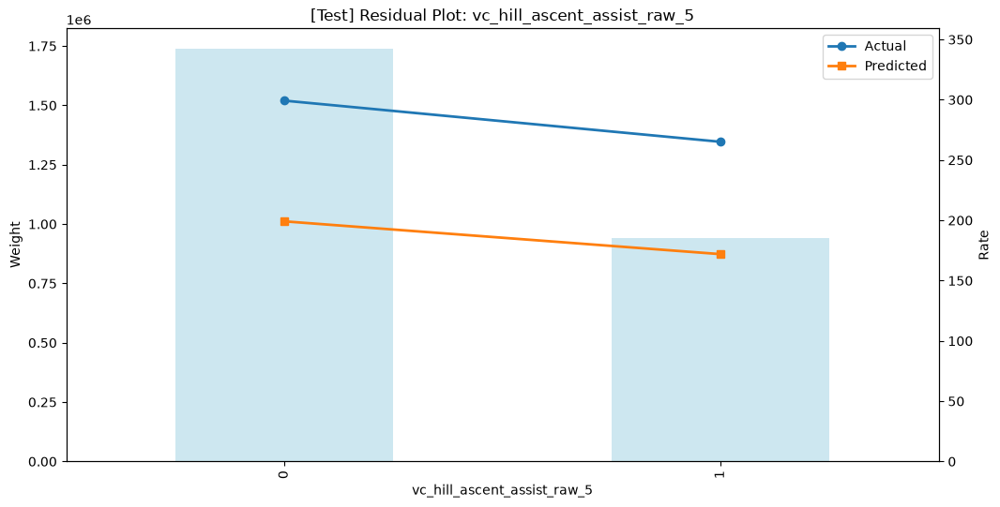

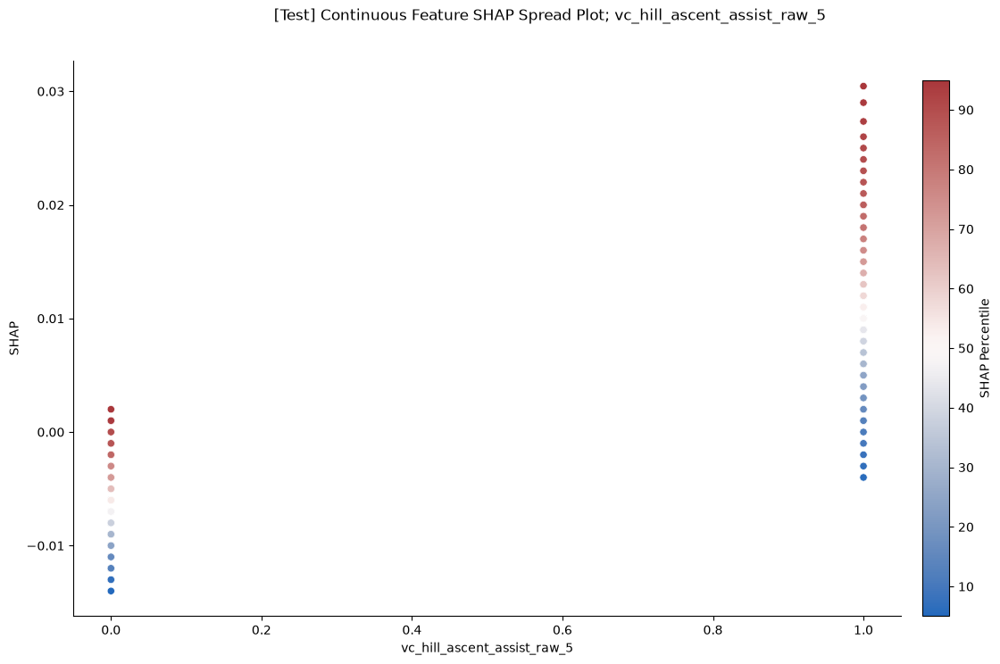


FEATURE: vc_touch_screen_raw_5


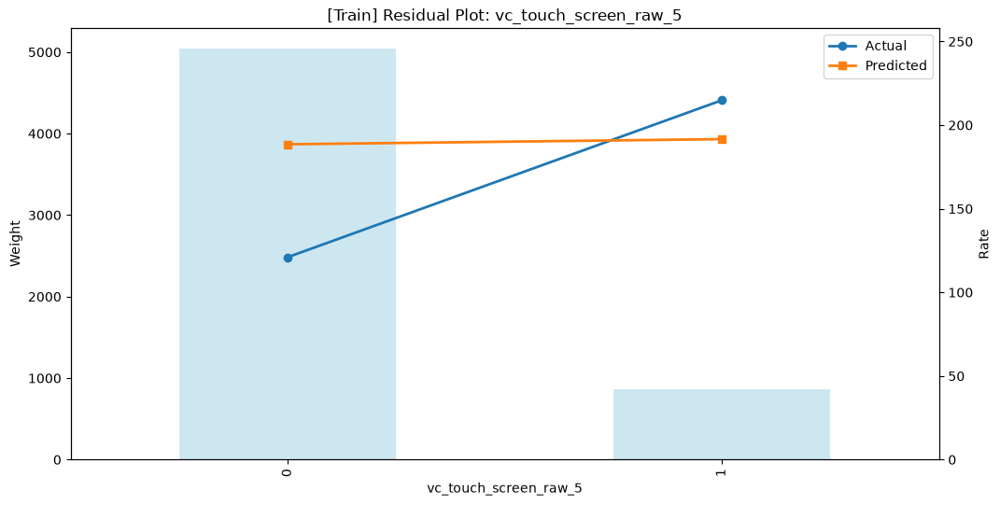

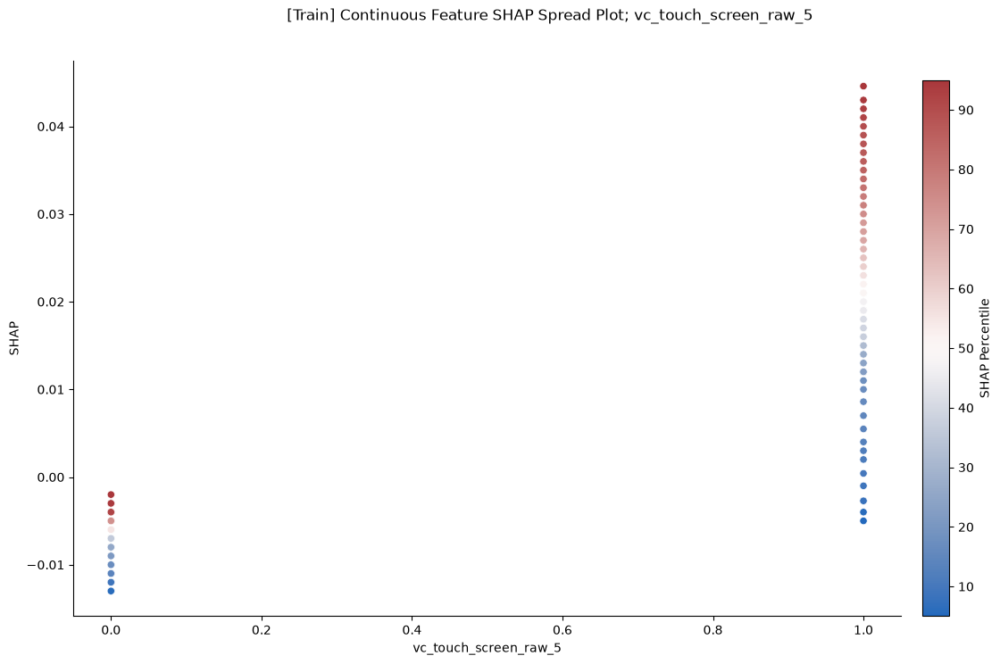

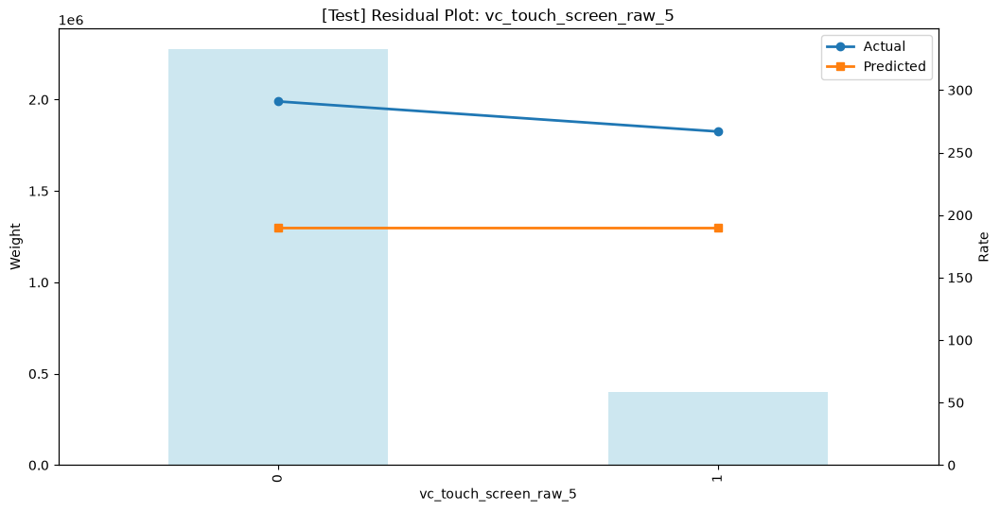

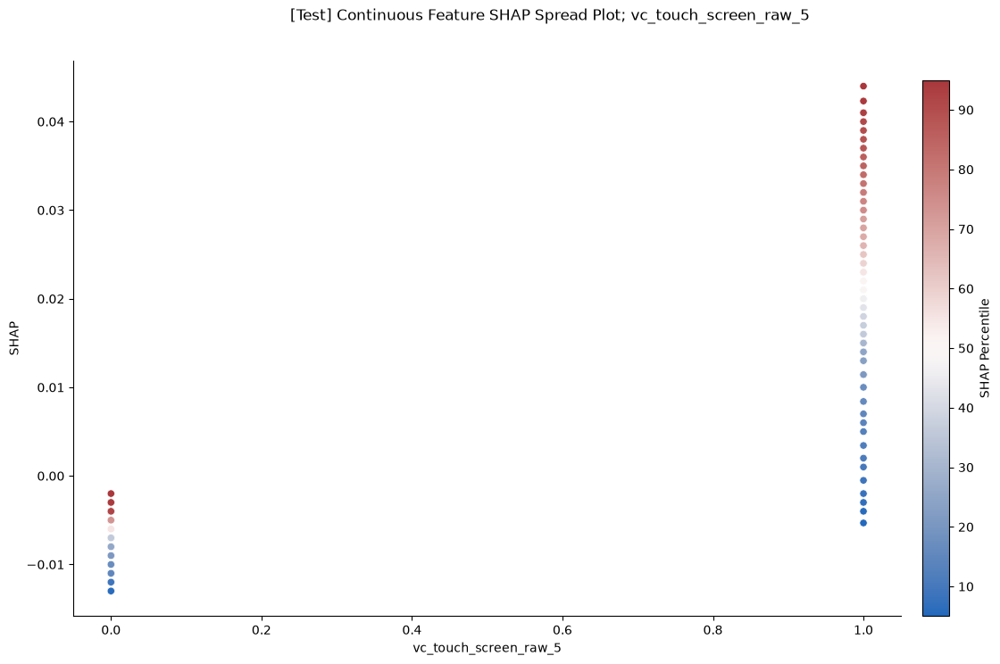


FEATURE: vc_speed_sensitive_volume_raw


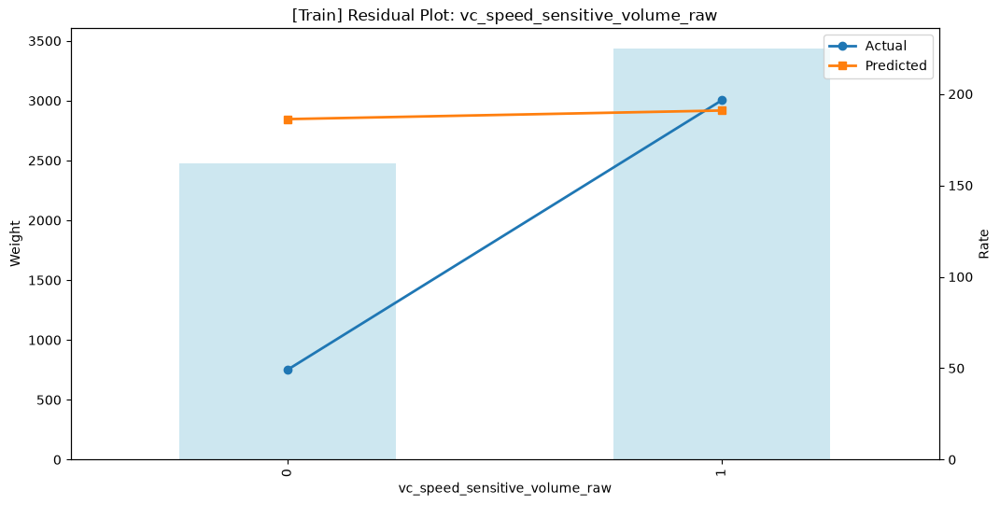

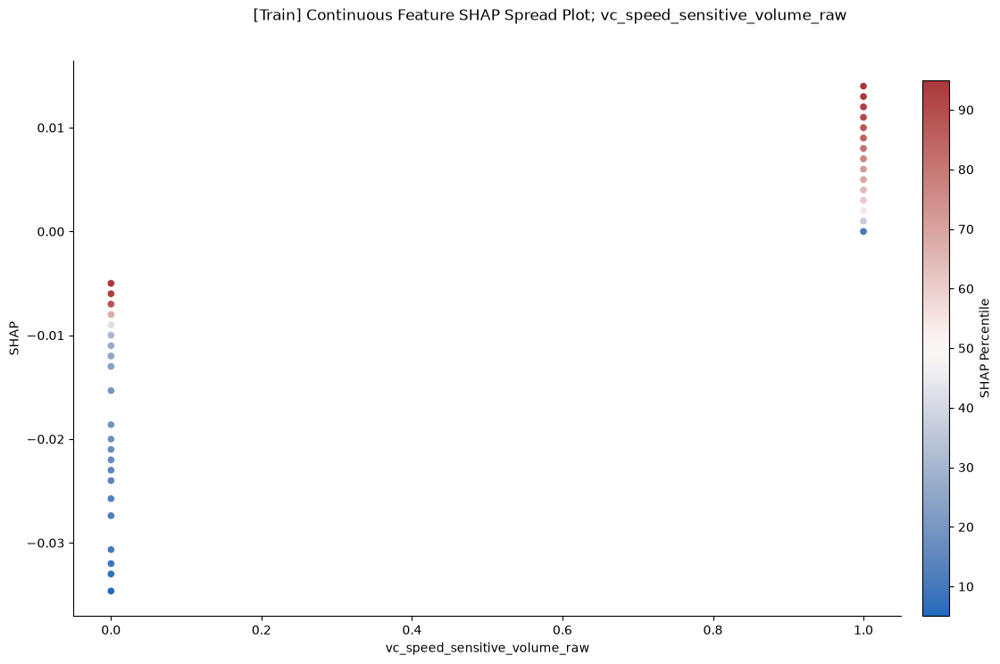

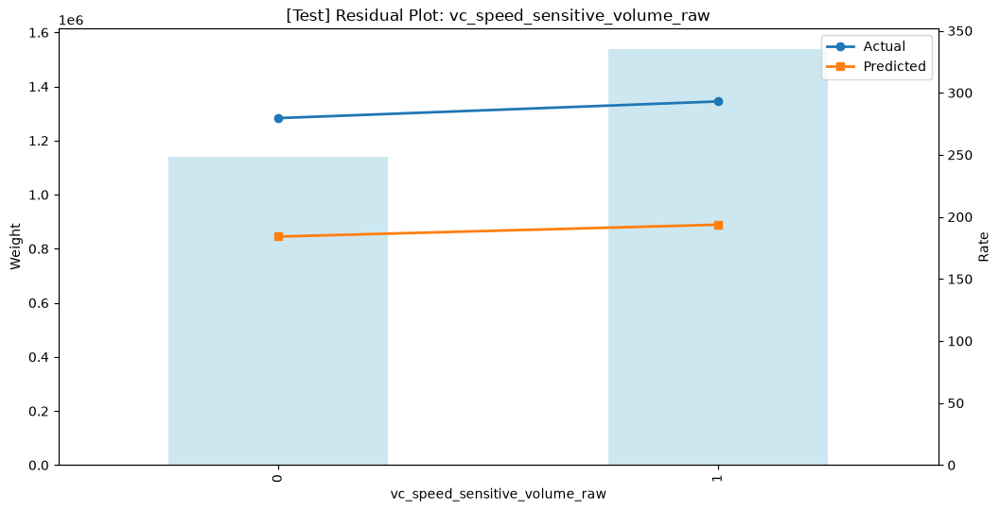

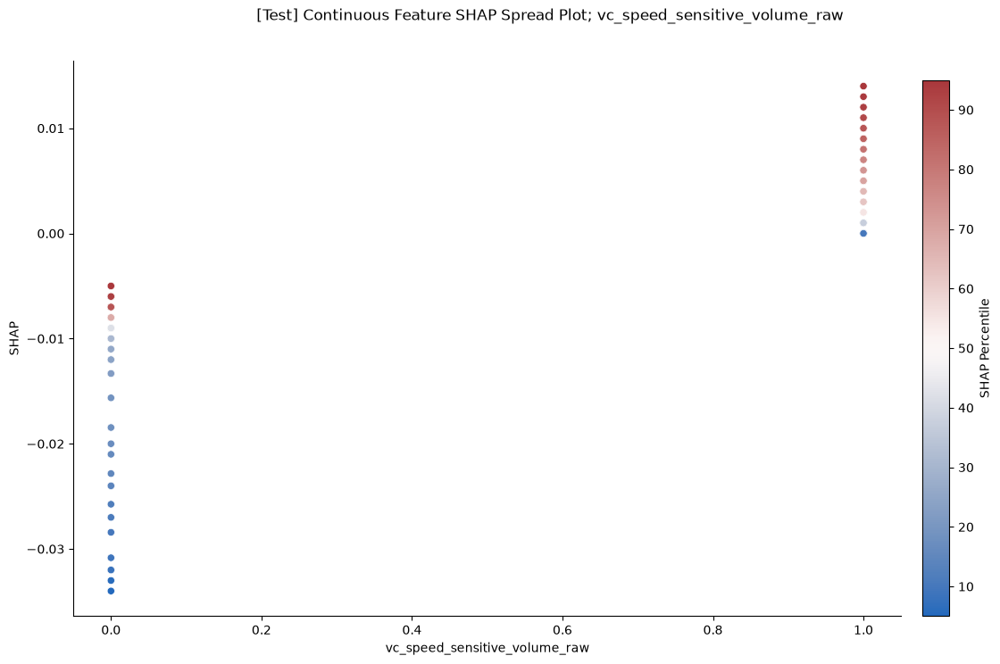


FEATURE: vc_heated_steering_wheel_raw


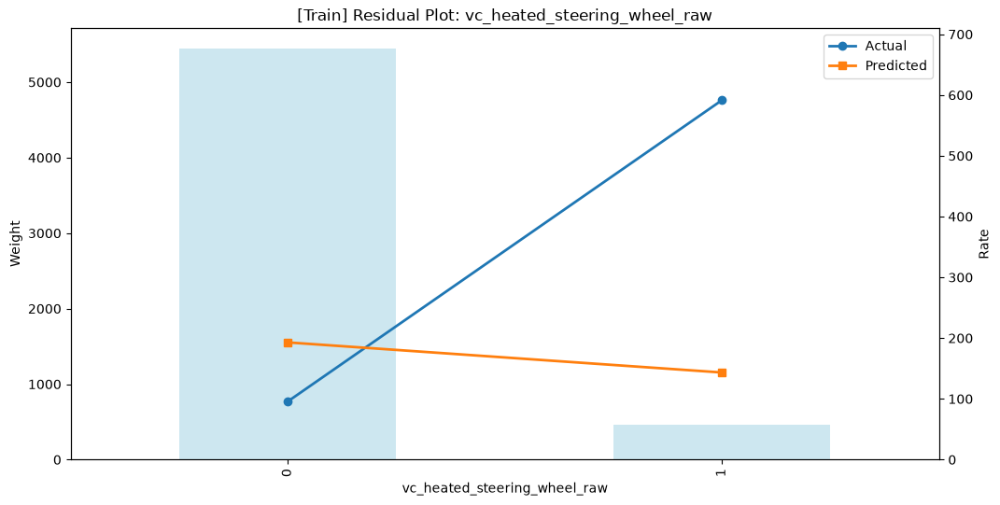

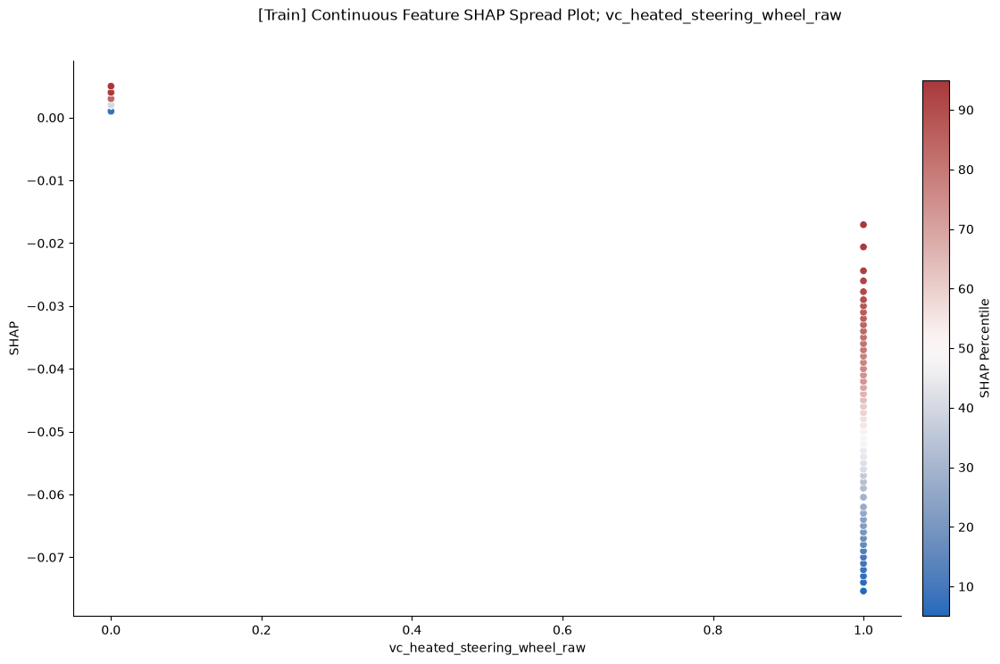

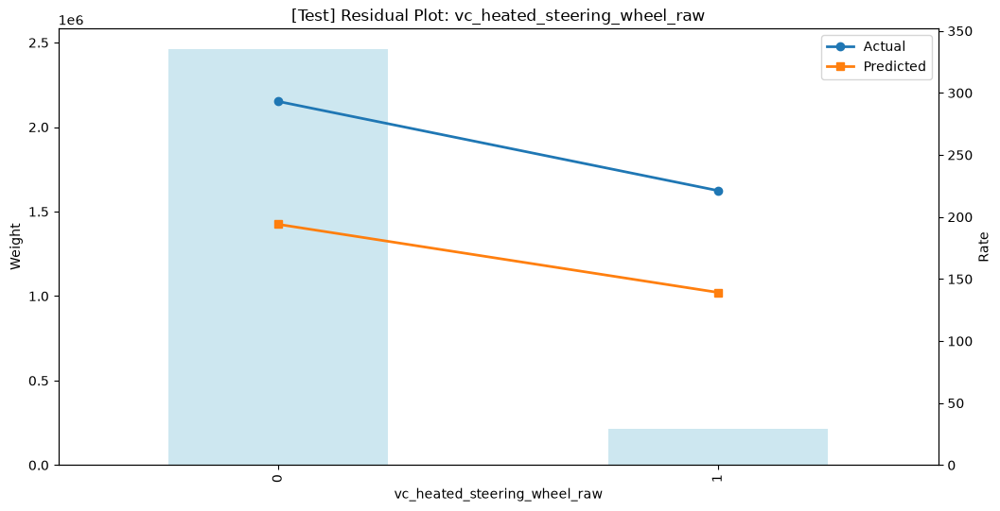

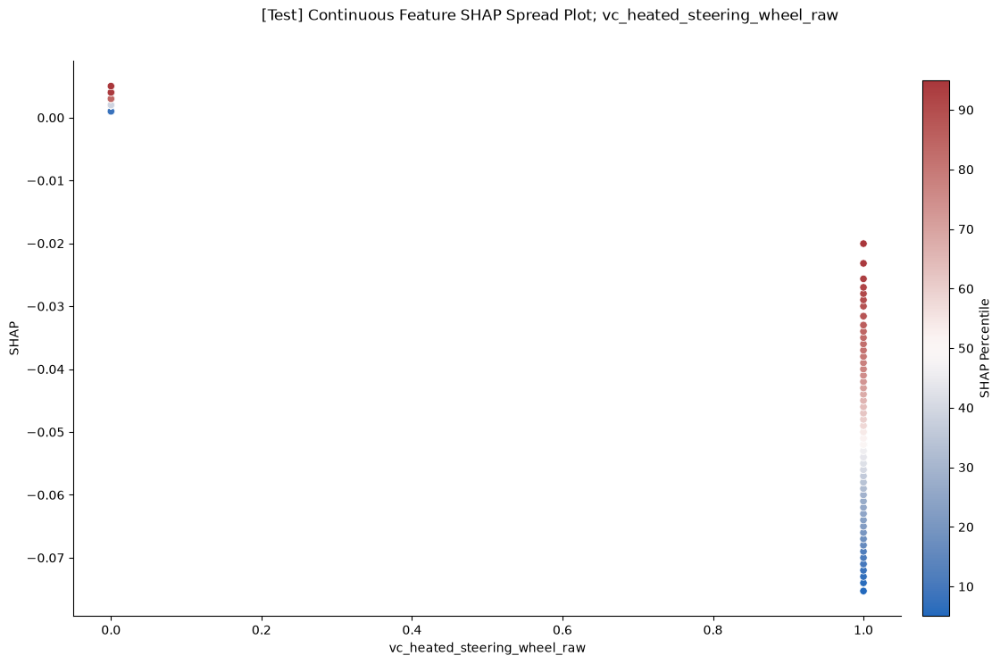


FEATURE: vc_tinted_windows_raw_5


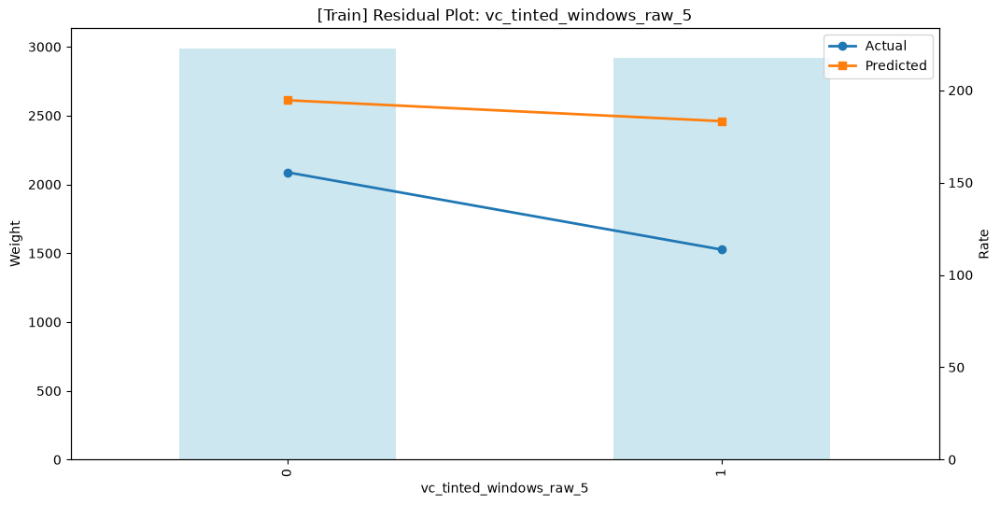

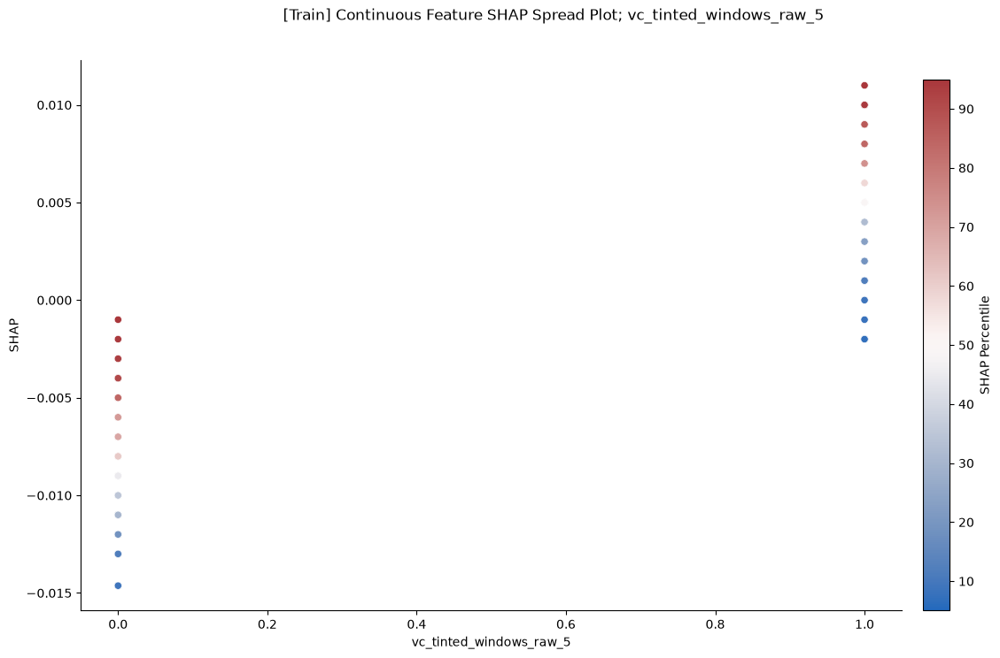

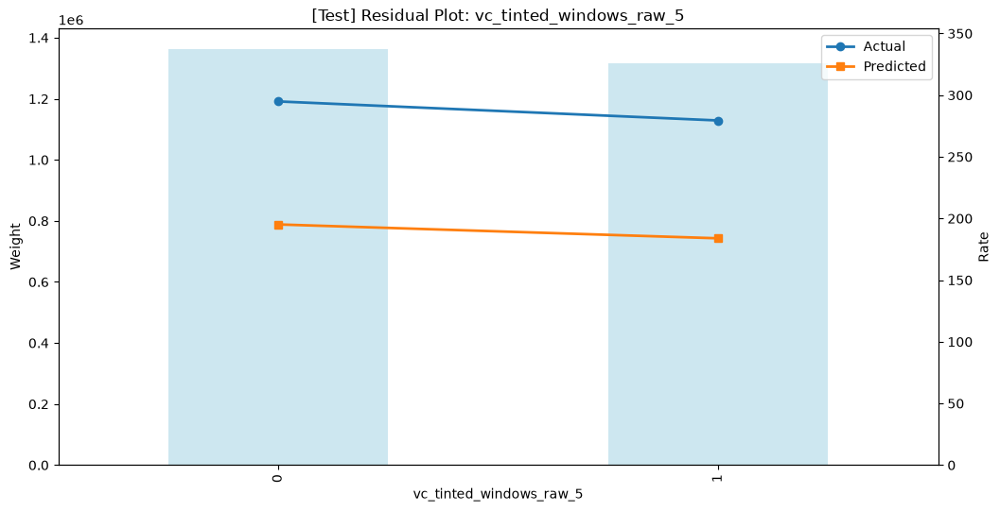

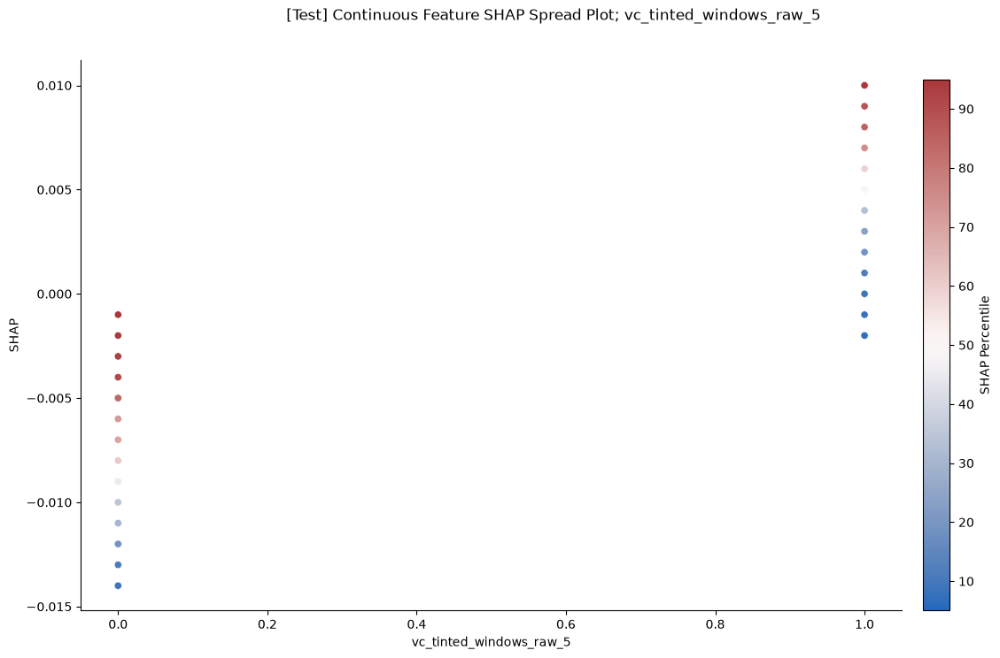


FEATURE: vc_power_sunroof_raw_3


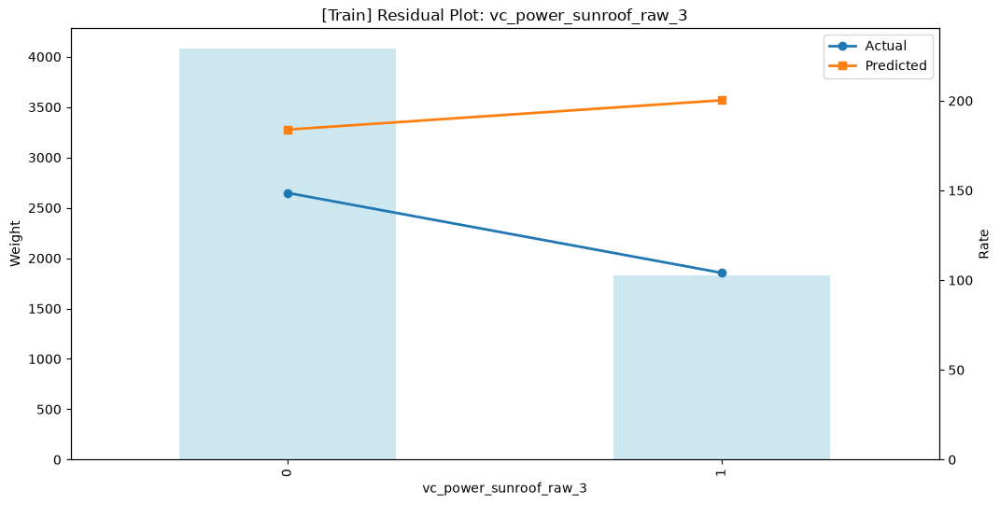

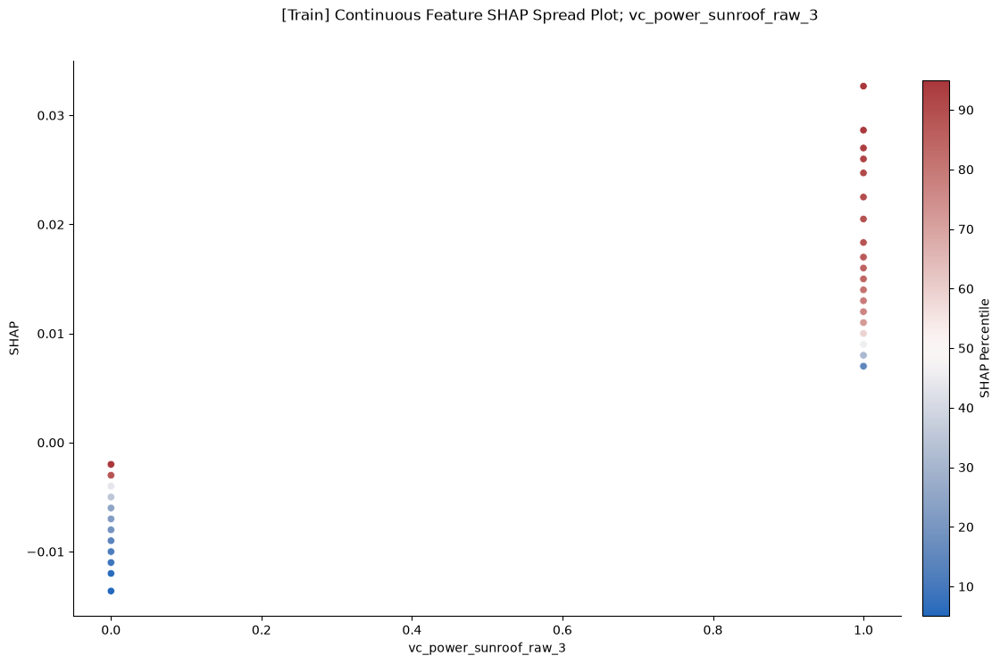

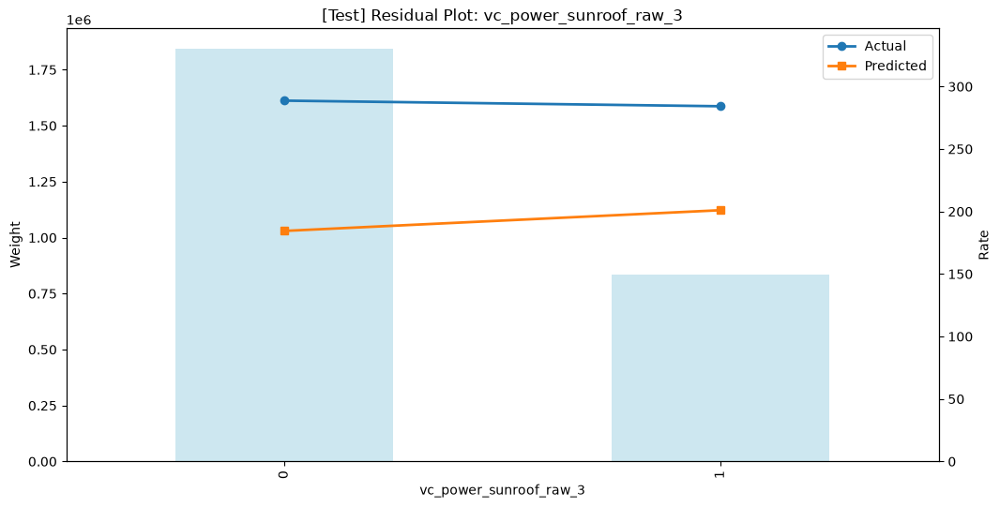

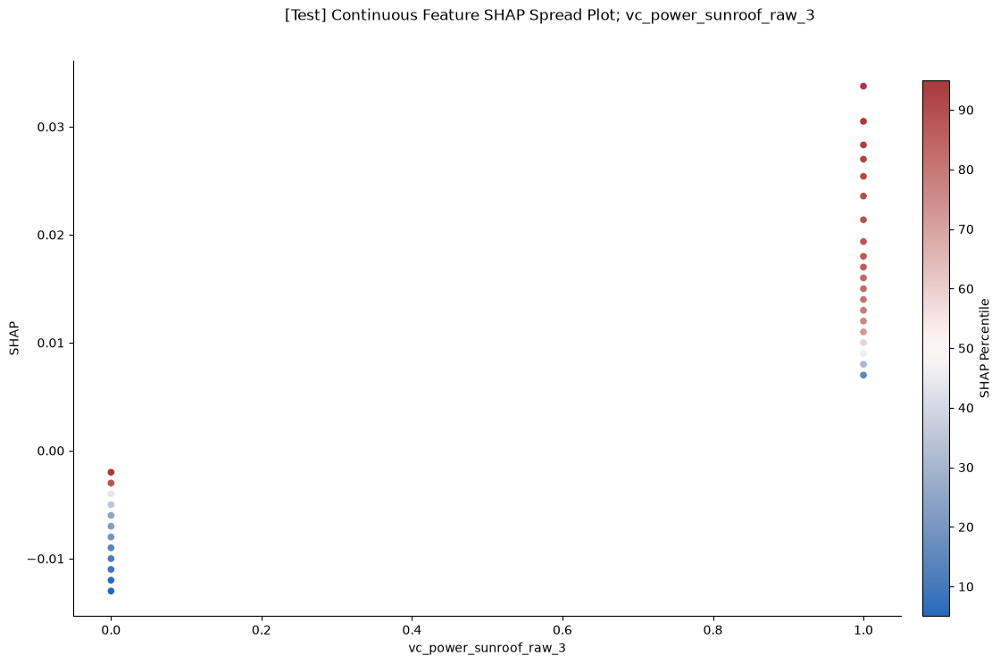


FEATURE: vc_lane_keeping_assistance_raw


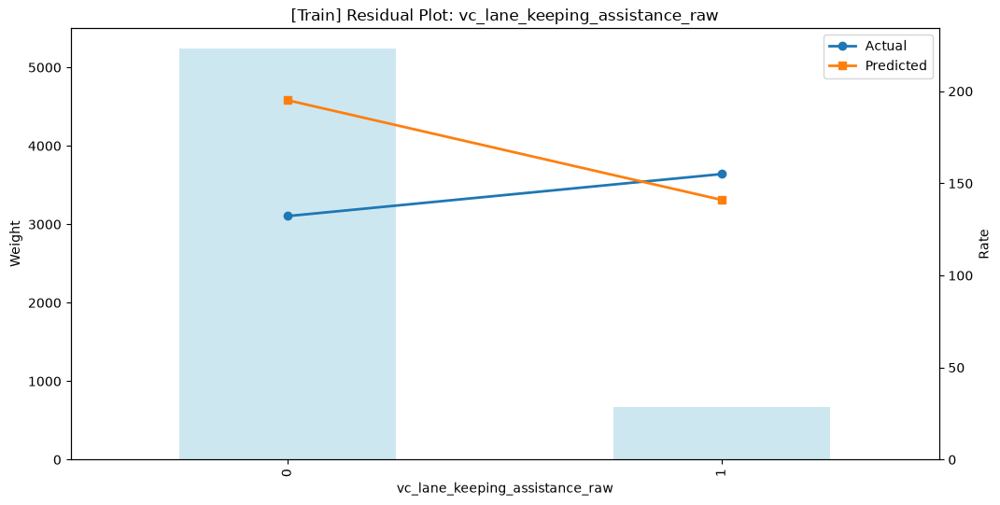

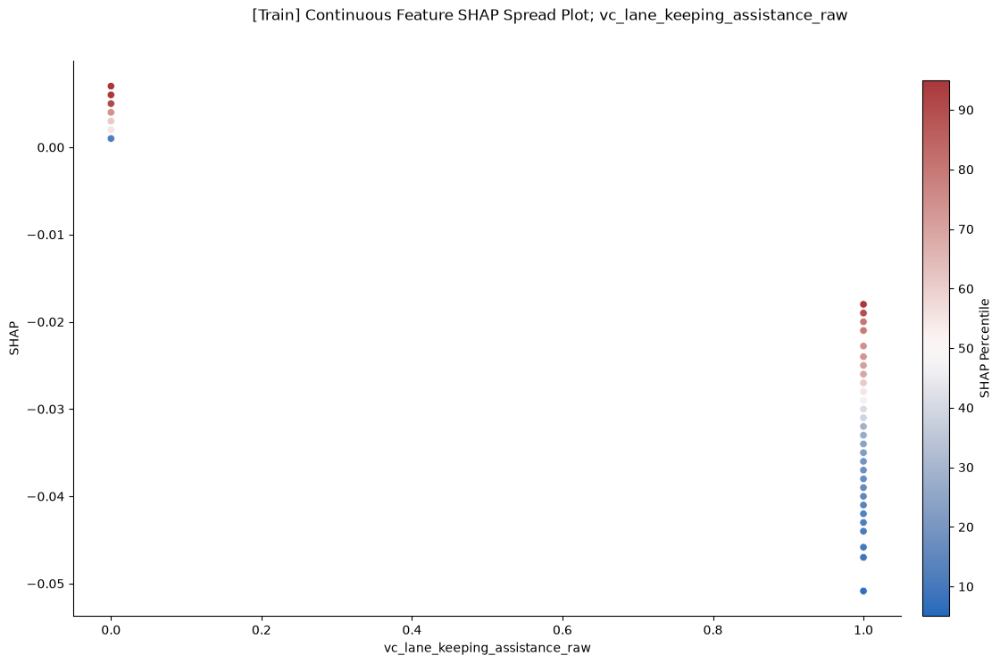

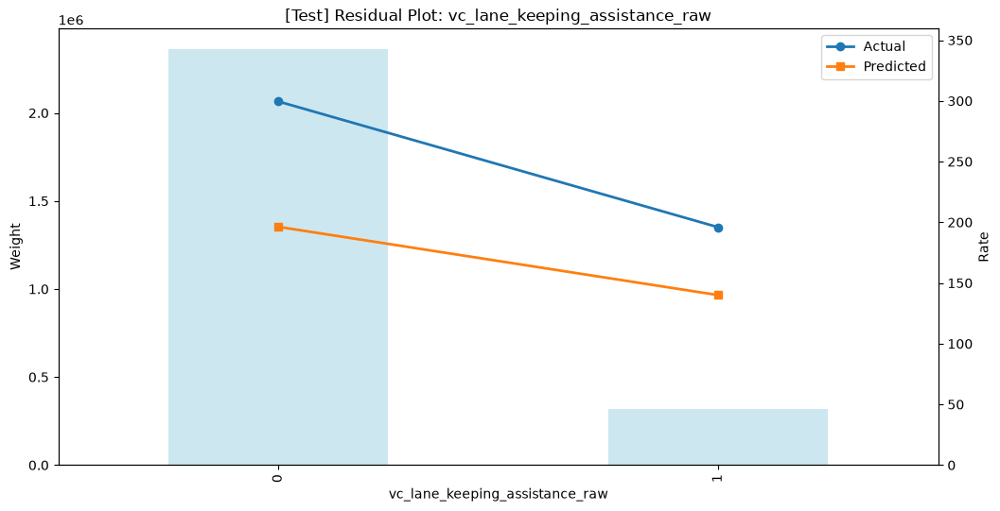

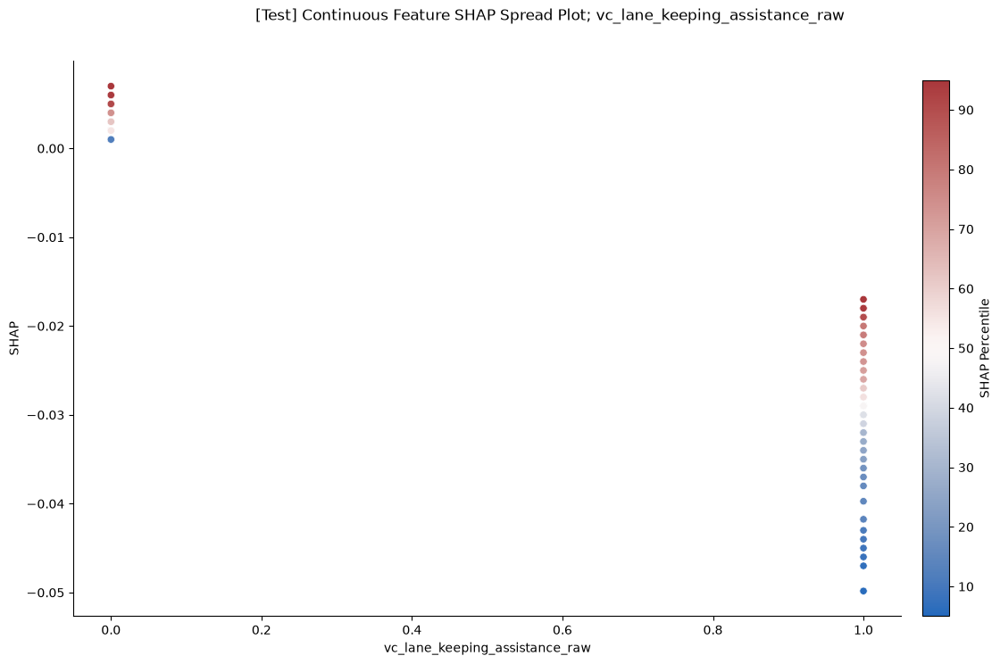


FEATURE: vc_electronic_braking_system_raw_0


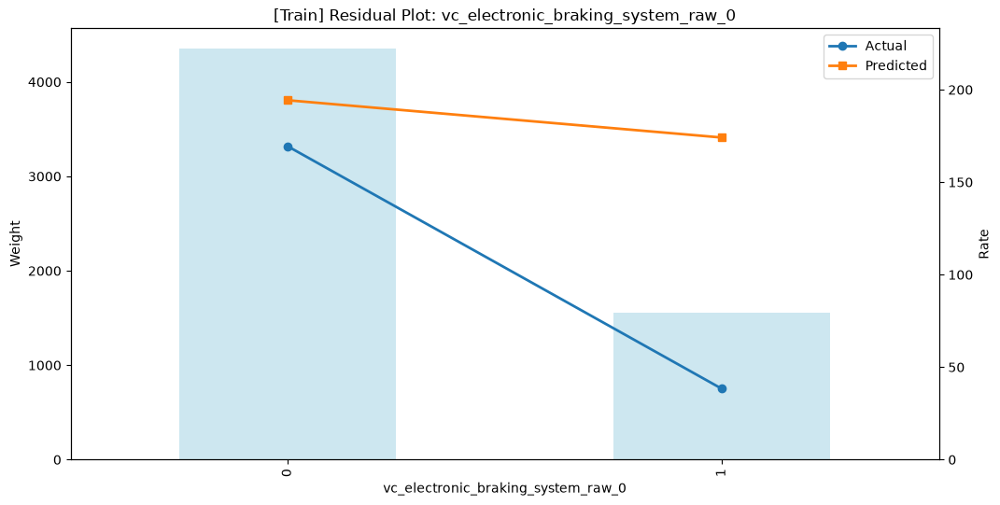

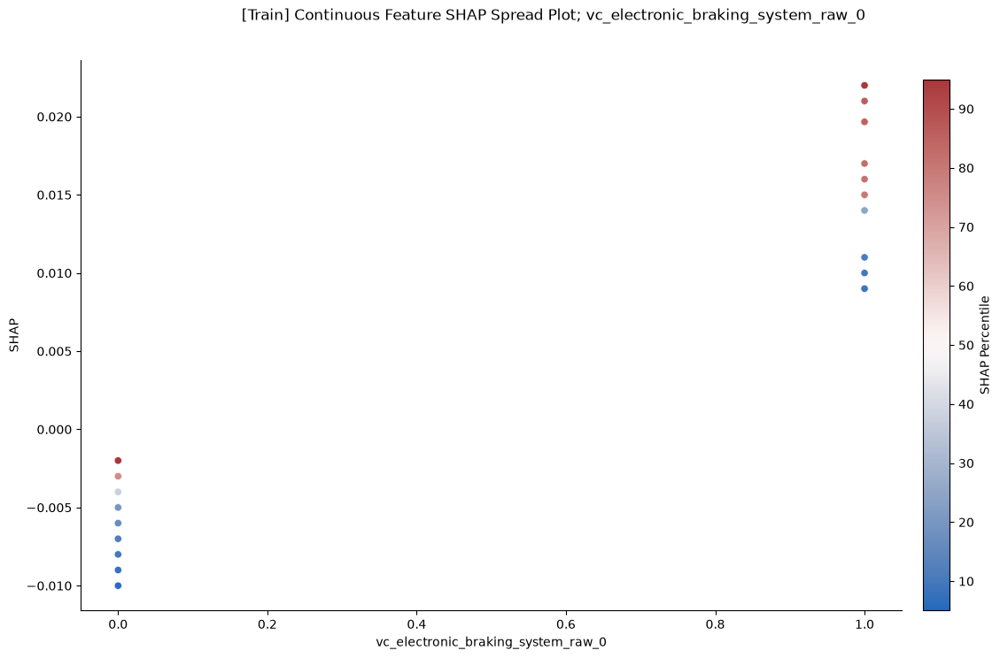

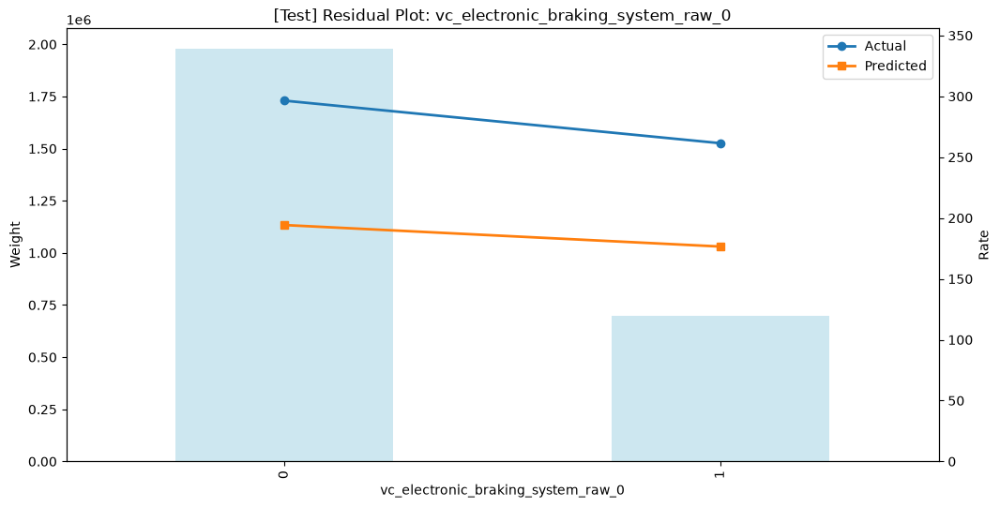

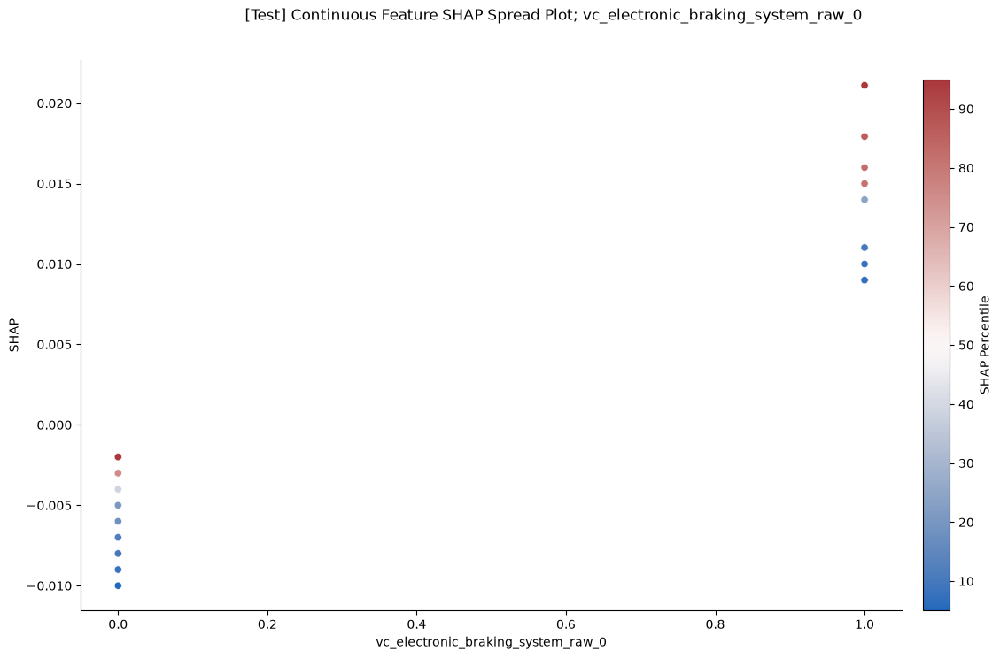


FEATURE: vc_drive_type_rwd_ind


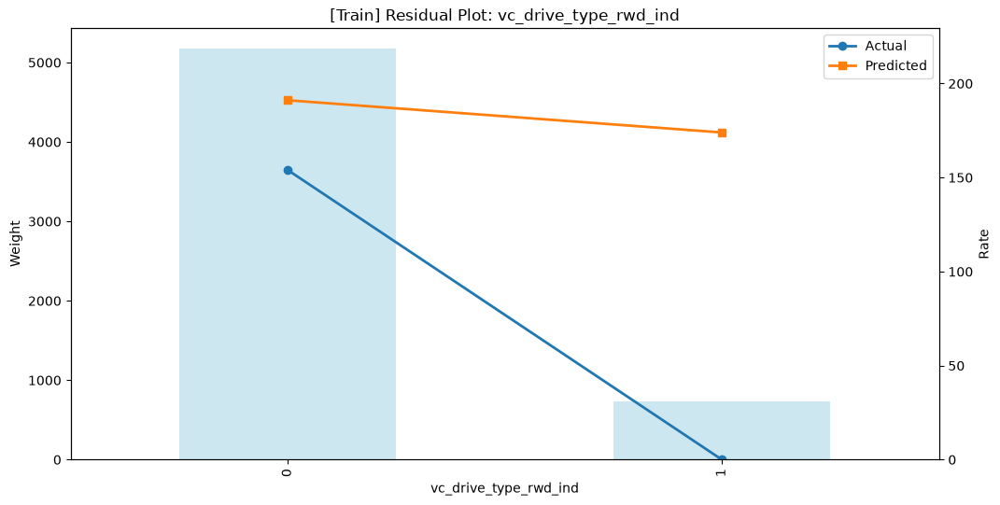

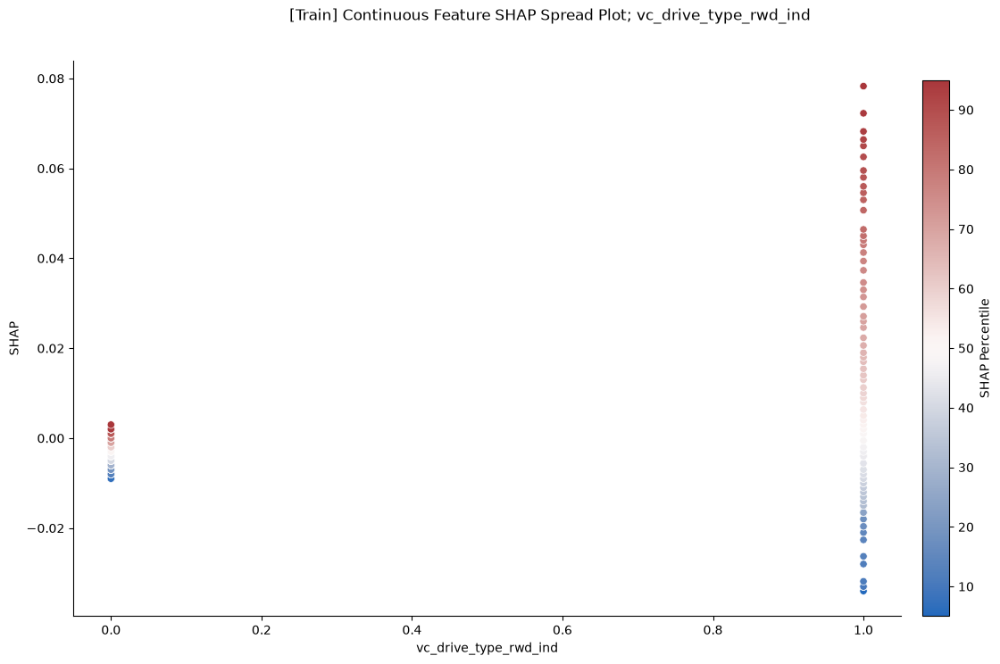

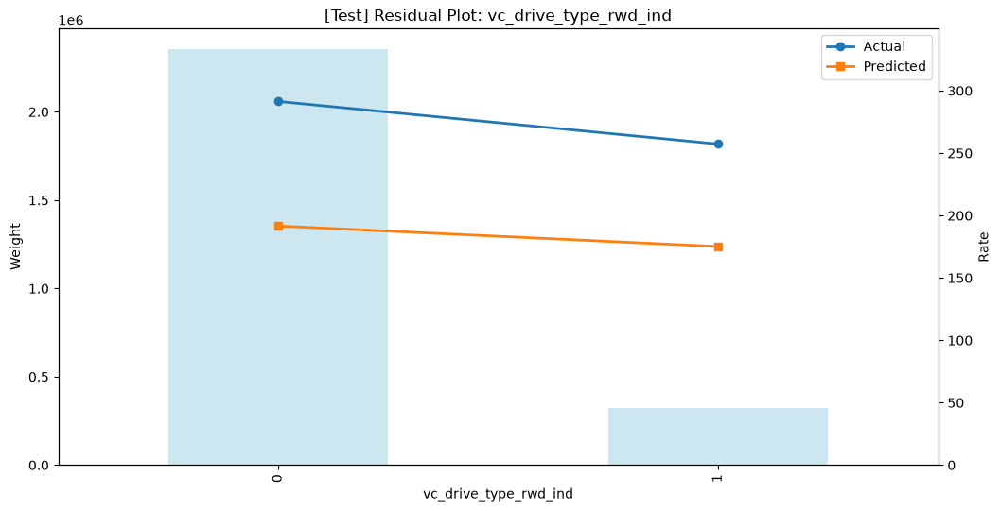

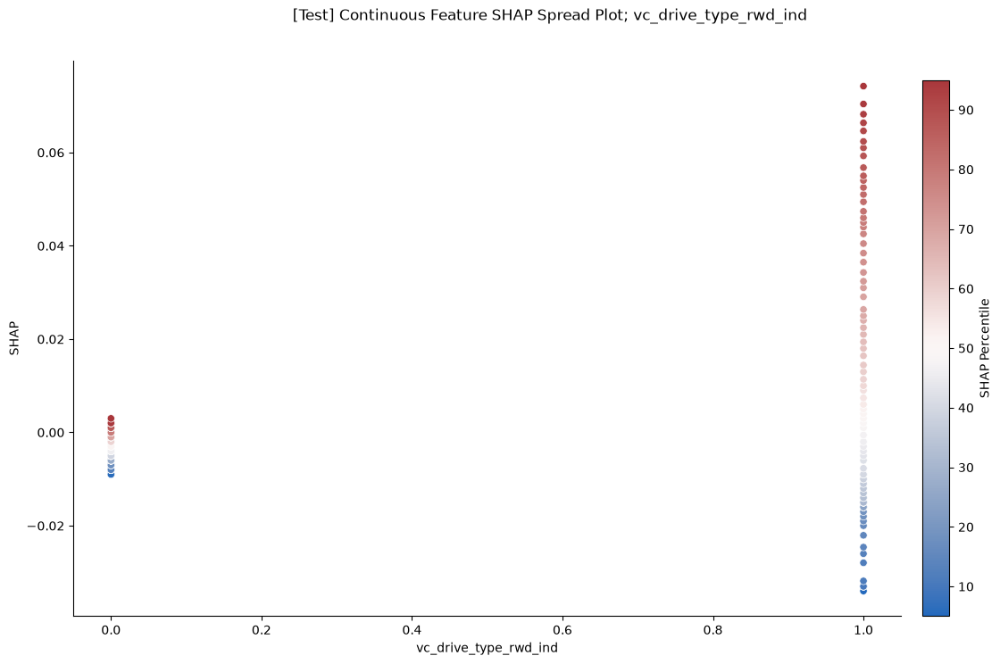


FEATURE: vc_camera_raw_0


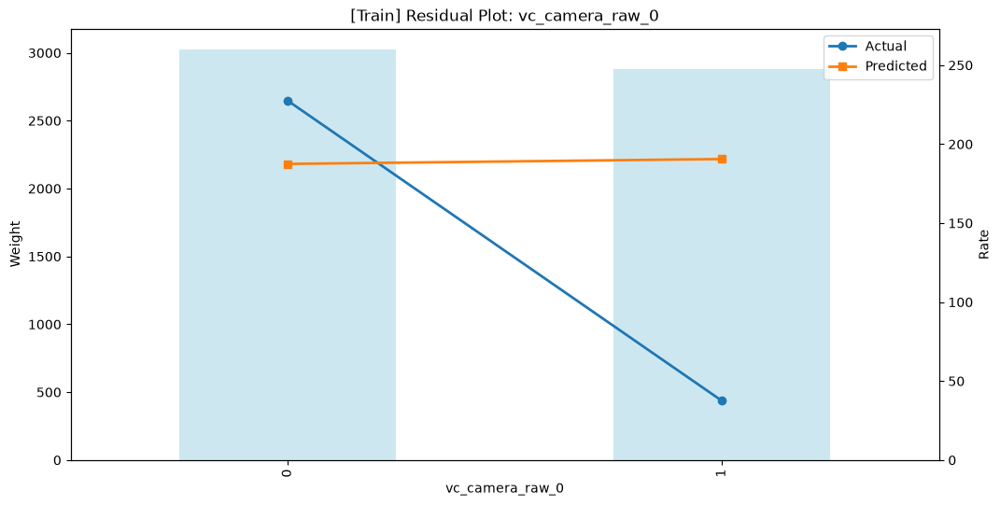

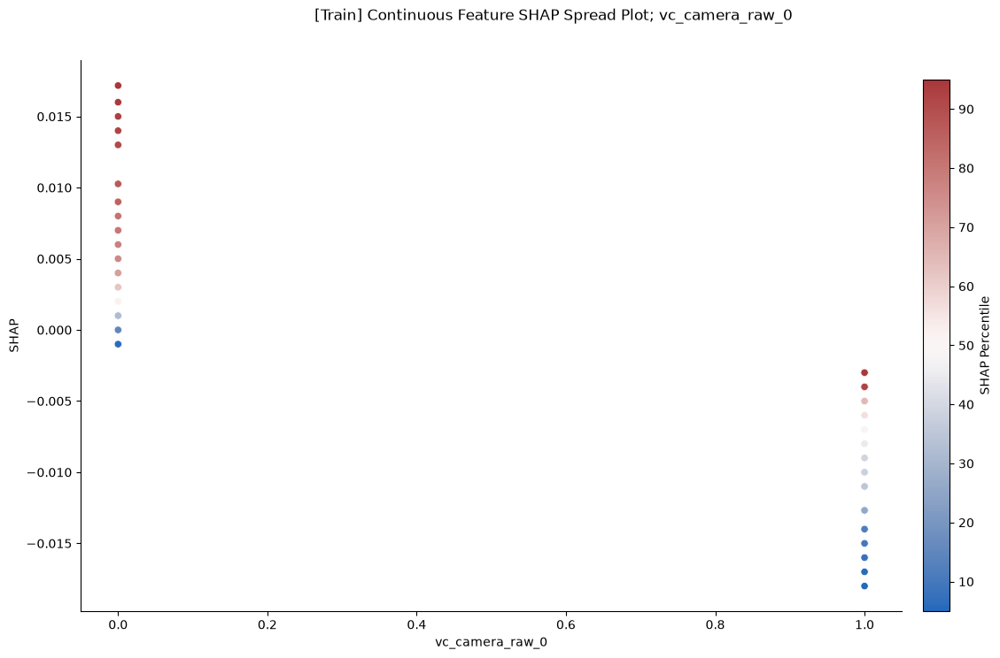

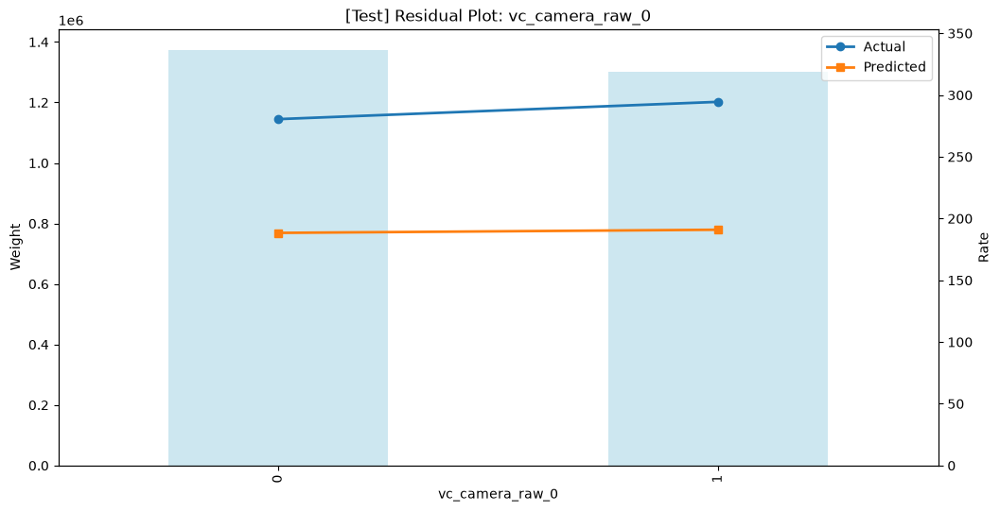

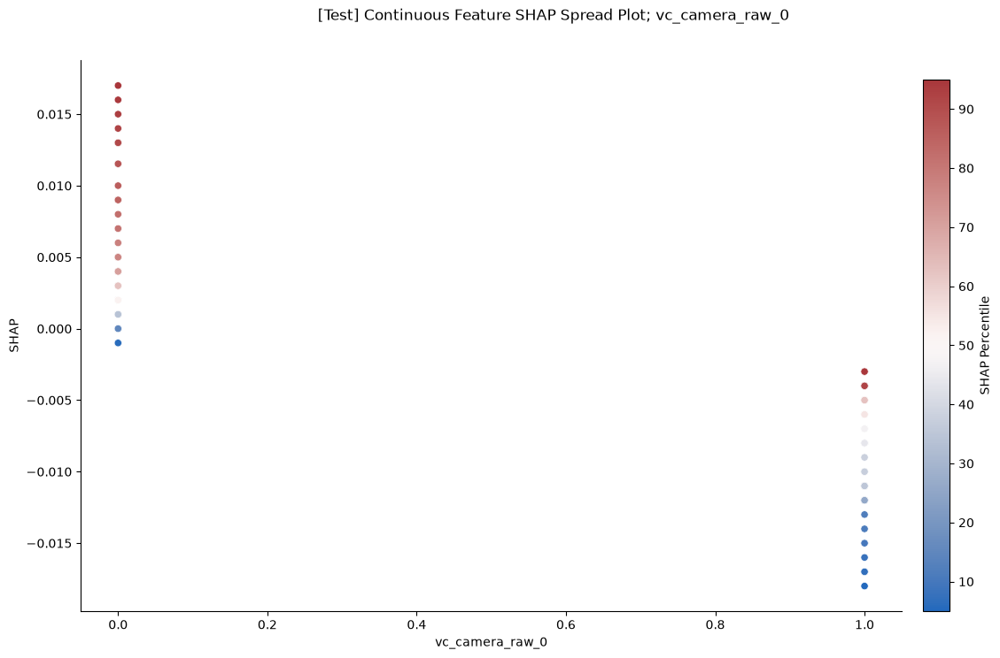


FEATURE: vc_remote_engine_start_raw_0


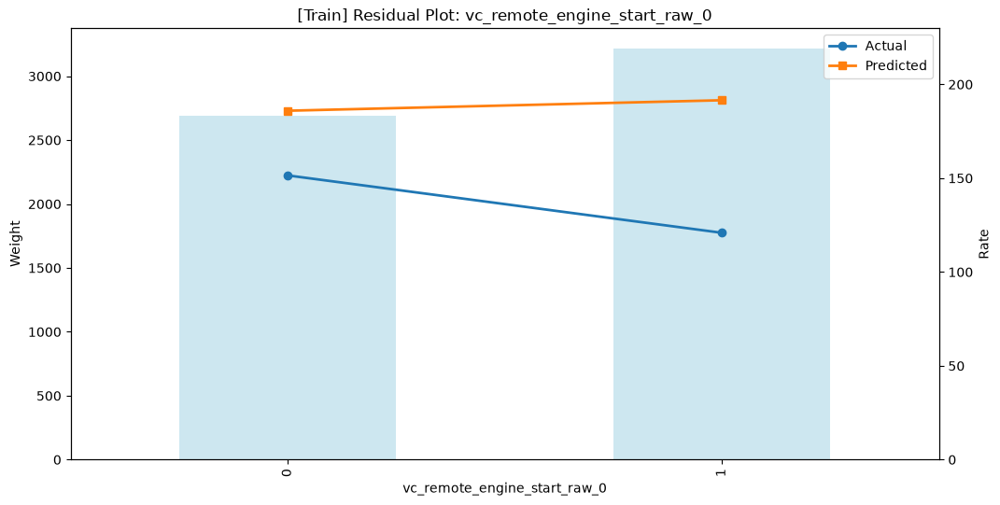

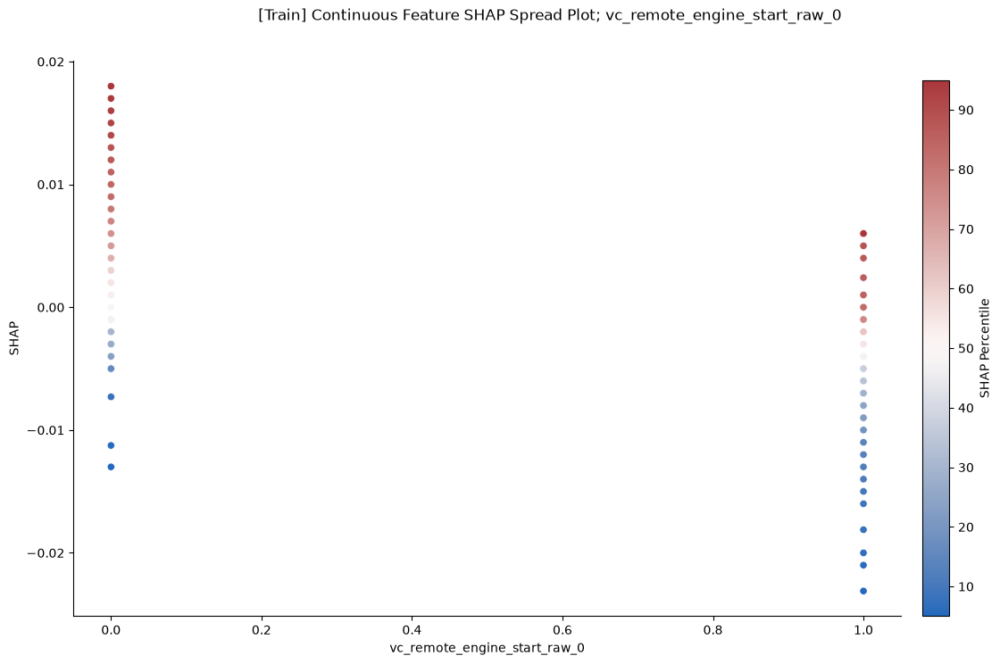

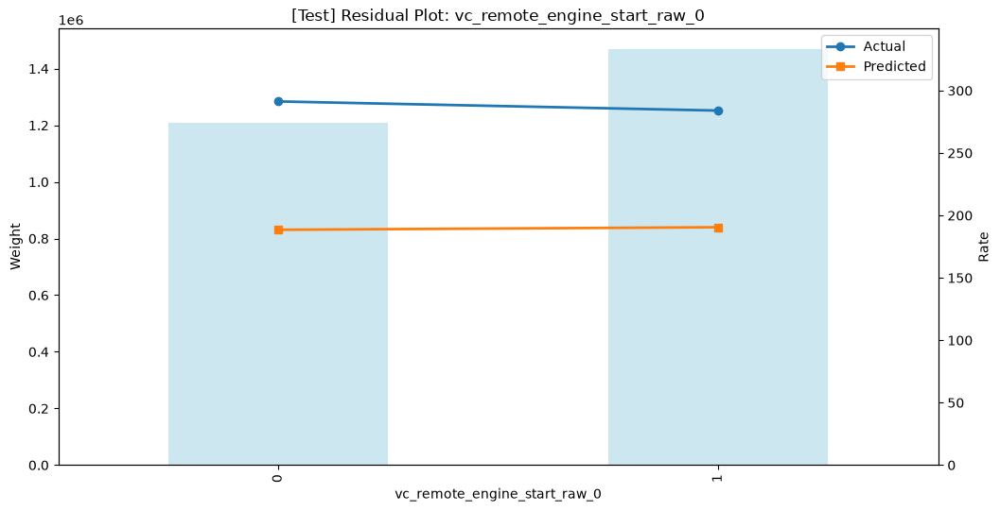

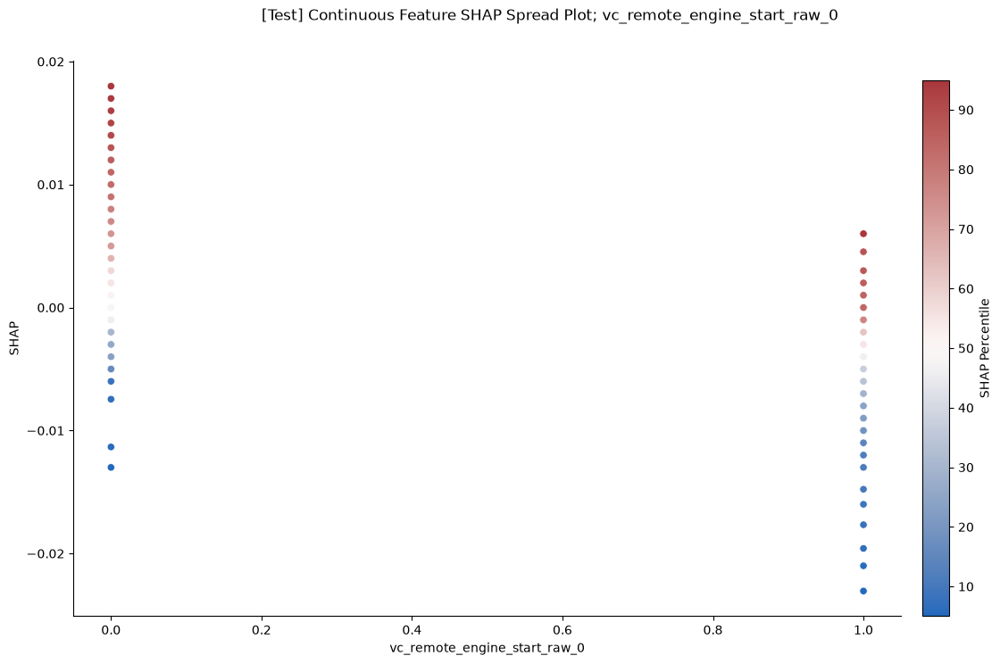


FEATURE: vc_power_sunroof_raw_5


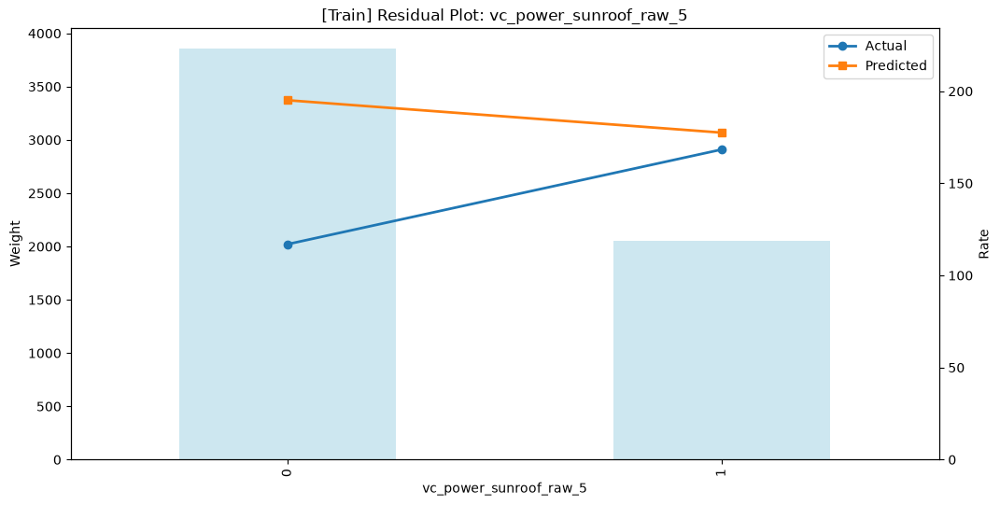

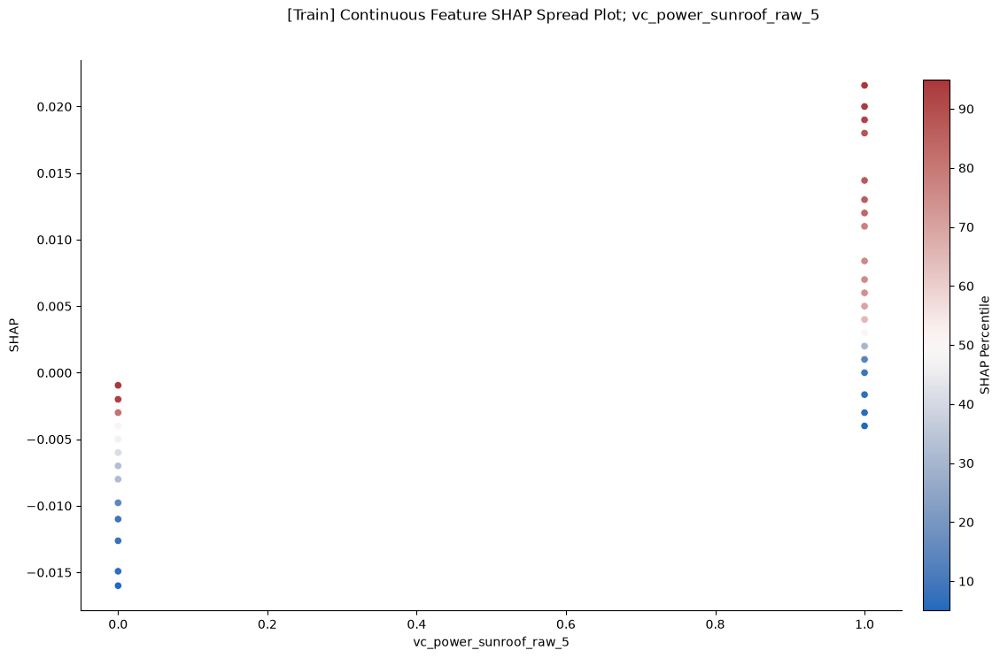

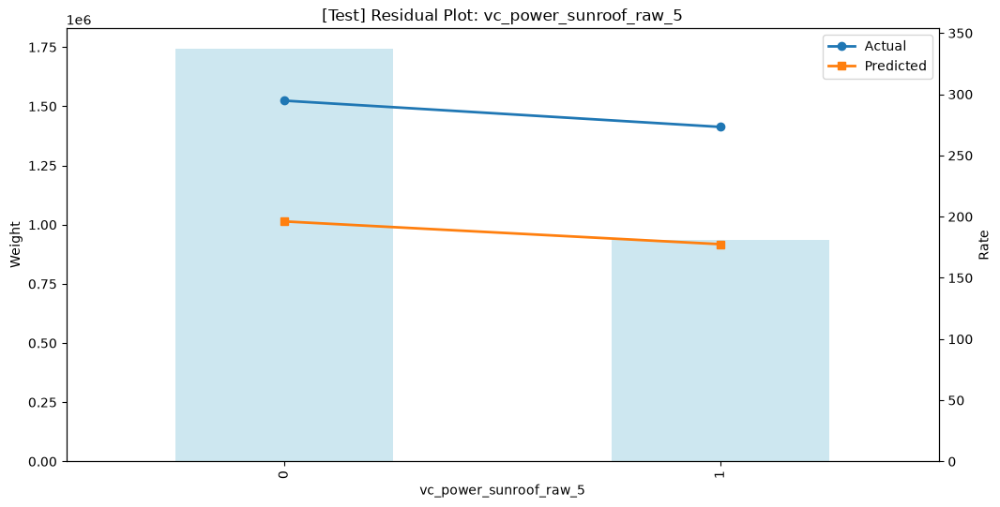

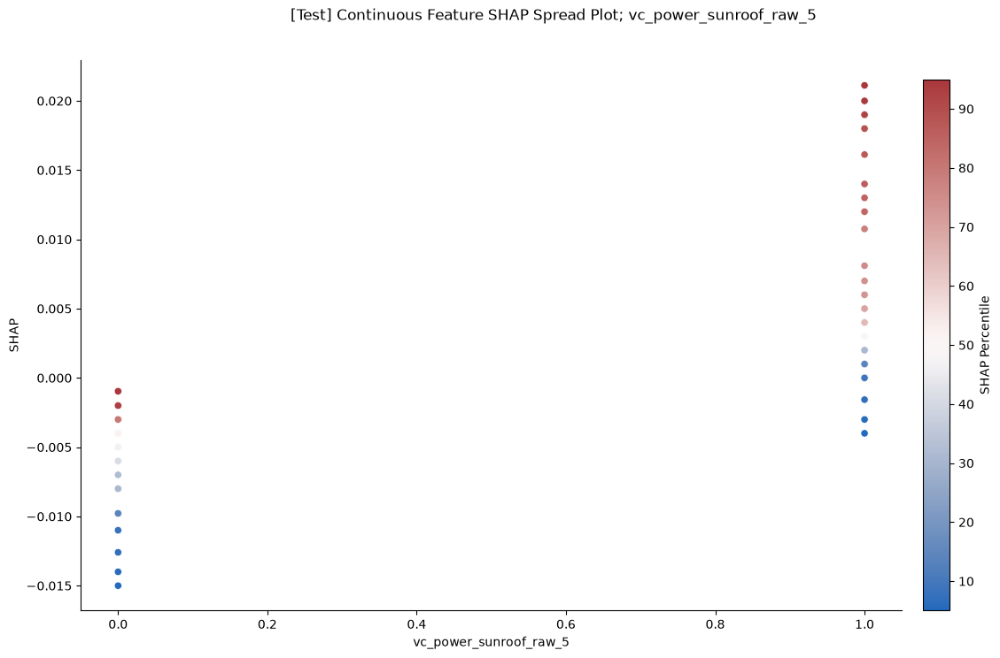


FEATURE: vc_taillights_led_raw


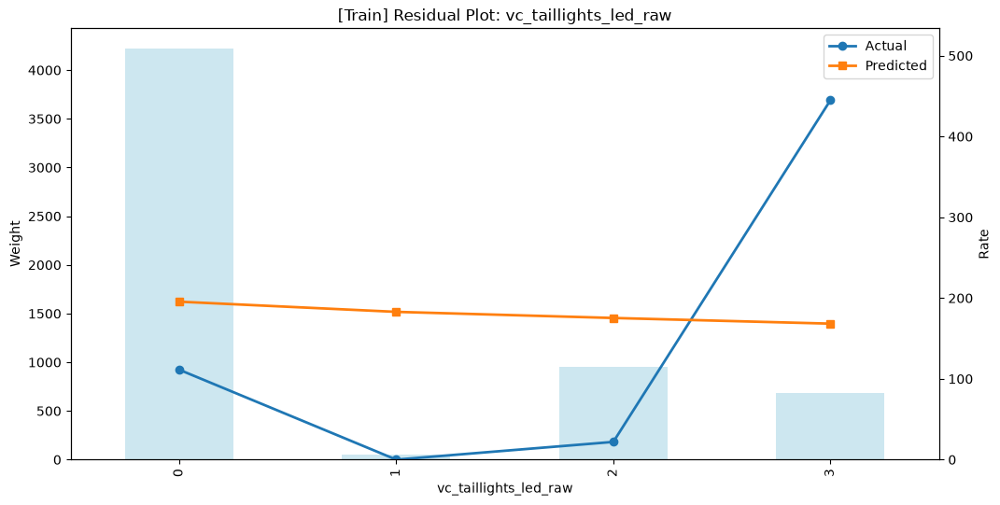

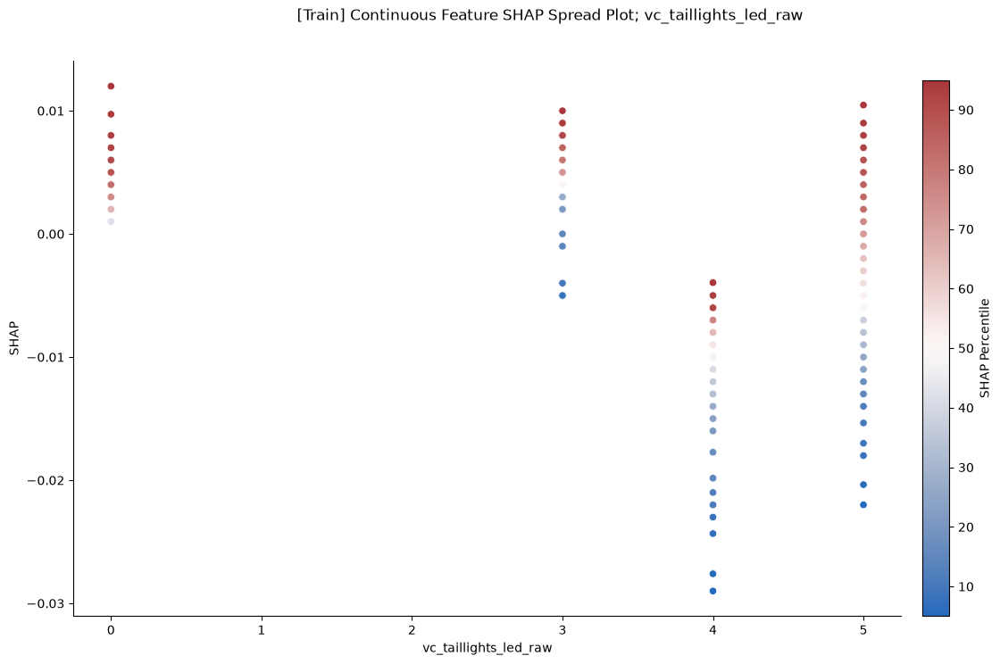

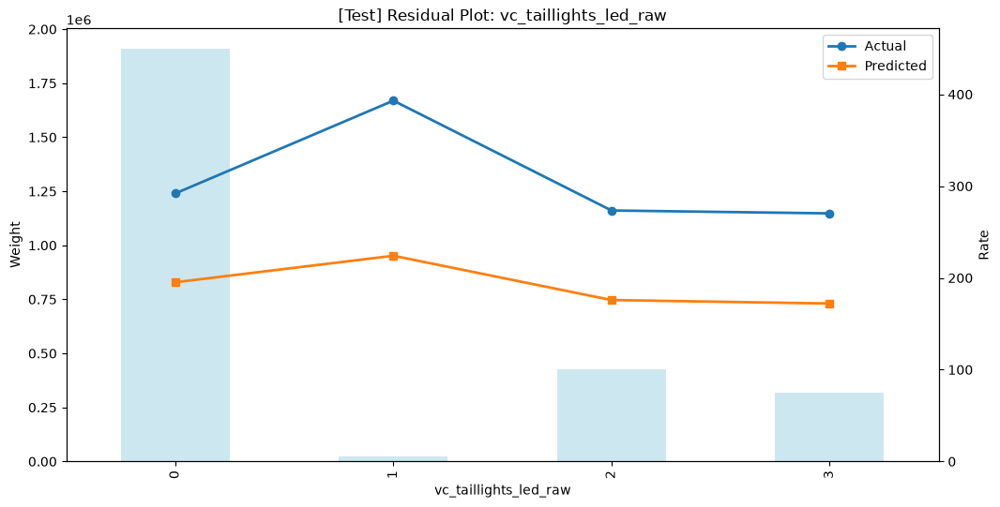

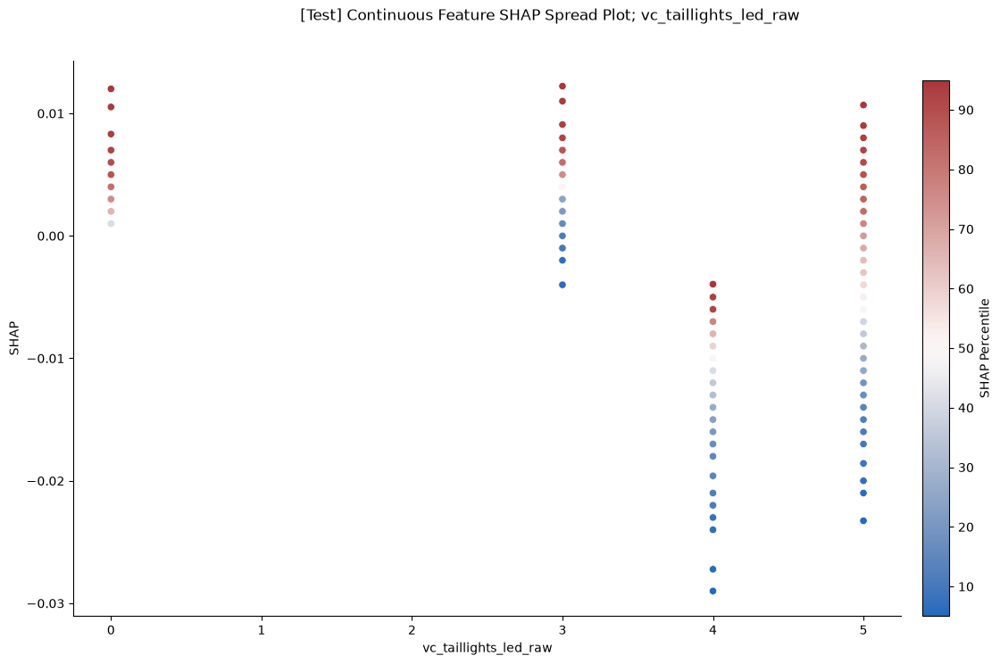


FEATURE: vc_auto_dimming_rearview_mirror_raw_5


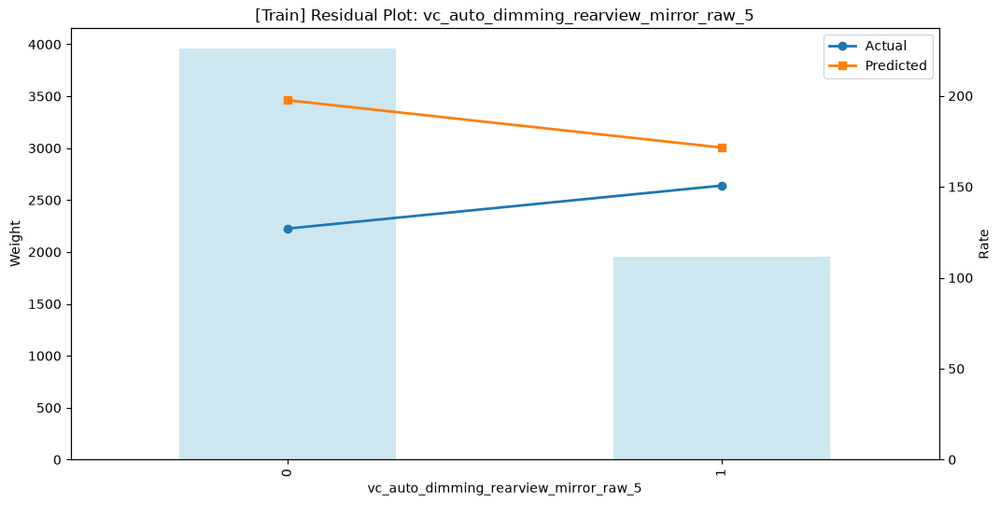

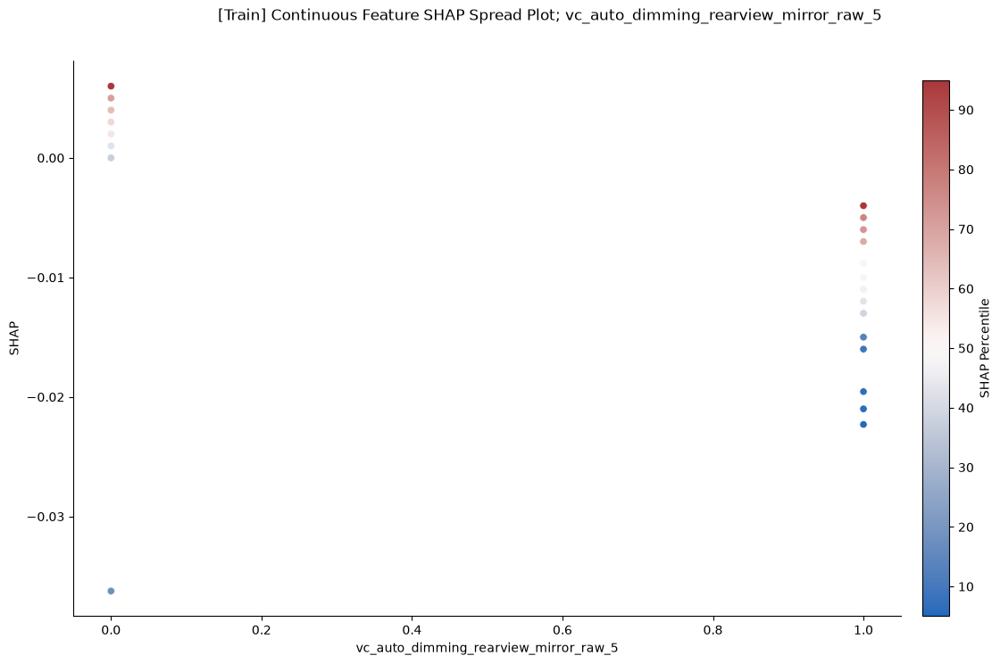

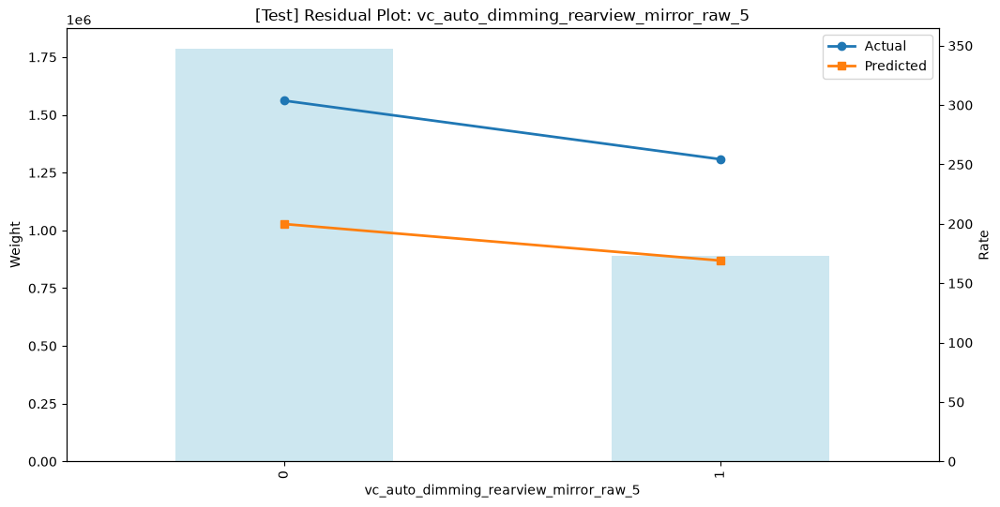

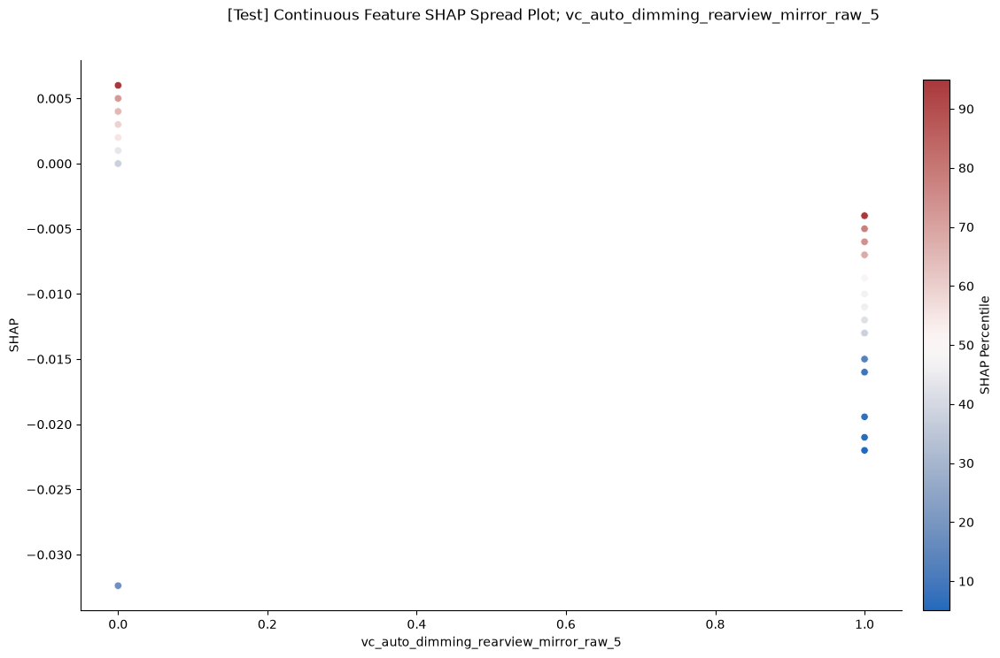


[OK] Displayed 155 plots


In [16]:
from IPython.display import Image, display
print("\n" + "="*60)
print("DISPLAYING ALL PLOTS")
print("="*60)
for f in features:
    if f not in plots_by_feature or not plots_by_feature[f]:
        continue
    print("\n" + "="*60)
    print(f"FEATURE: {f}")
    print("="*60)
    for plot_path in plots_by_feature[f]:
        if Path(plot_path).exists():
            display(Image(filename=plot_path))
        else:
            print(f"WARNING: {plot_path} not found")
print(f"\n[OK] Displayed {sum(len(v) for v in plots_by_feature.values())} plots")

In [17]:
summary["features"] = features
summary["top_n"] = top_n
summary_file = f"{output_base}/results/07_analysis_summary.yaml"
with open(summary_file, "w") as f:
    yaml.dump(summary, f)
print(f"\nSummary: {summary_file}")


Summary: output/car_liab/v1/results/07_analysis_summary.yaml


In [18]:
print("\n" + "#"*40)
print("# STAGE 07: COMPLETE")
print("#"*40)
print(f"Plots: {summary['plots']}")


########################################
# STAGE 07: COMPLETE
########################################
Plots: 155
